In [1]:
import pandas as pd

dog_parks = pd.read_csv("dog_tick_brisbane.csv")

print("Shape:", dog_parks.shape)
display(dog_parks.head())

print("\nColumns:")
print(dog_parks.columns.tolist())

Shape: (172, 17)


,OBJECTID,SAP_FUNCTIONAL_LOCATION,ITEM_DESCRIPTION,ITEM_TYPE,PARK_NUMBER,PARK_NAME,SUBURB,FENCING,LIGHTING,SMALL_DOG_ENCLOSURE,DOG_AGILITY_EQUIPMENT,LONG,LAT,Shape__Area,Shape__Length,geo_shape,geo_point_2d
0,1,B-RE-0113-N002,KEDRON BROOK DOG OFF LEASH AREA (GYMPIE RD SEC...,DOG OFF LEASH NODE,D2145,GYMPIE RD (NO 1) PARK,KEDRON,UNFENCED,NO,NO,NO,153.037702,-27.411984,5373.394043,558.647775,"{""coordinates"": [[[153.036540528163, -27.41270...","-27.411983601482856, 153.03770222645912"
1,2,B-RE-2561-N002,PIONEER CRES DOG OFF LEASH AREA,DOG OFF LEASH NODE,D1119,PIONEER CRESCENT PARK,BELLBOWRIE,FULLY FENCED,NO,YES,NO,152.872043,-27.561283,3508.695068,242.448140,"{""coordinates"": [[[152.871943139313, -27.56091...","-27.56128293230188, 152.8720425974478"
2,3,B-RE-0610-N003,KOOKABURRA PK WEST DOG OFF LEASH AREA,DOG OFF LEASH NODE,D1886,KOOKABURRA PARK - WEST,KARANA DOWNS,UNFENCED,NO,NO,NO,152.839382,-27.544227,9284.272217,480.281960,"{""coordinates"": [[[152.839813012019, -27.54374...","-27.544227407356452, 152.83938221004433"
3,4,B-RE-0508-N007,GREENWAYS ESP DOG OFF LEASH AREA,DOG OFF LEASH NODE,D1617,GREENWAYS ESPLANADE PARK,PARKINSON,FULLY FENCED,NO,YES,YES,153.019845,-27.636032,2985.900635,356.814709,"{""coordinates"": [[[153.019656358018, -27.63573...","-27.636032111612142, 153.01984493845796"
4,5,B-RE-0066-N003,SUMNERS RD DOG OFF LEASH AREA,DOG OFF LEASH NODE,D2031,WOLSTON CREEK BUSHLAND RESERVE,RIVERHILLS,FULLY FENCED,NO,YES,YES,152.902676,-27.563597,3422.946289,251.512023,"{""coordinates"": [[[152.902214094965, -27.56366...","-27.563596772193403, 152.90267601508424"



Columns:
['OBJECTID', 'SAP_FUNCTIONAL_LOCATION', 'ITEM_DESCRIPTION', 'ITEM_TYPE', 'PARK_NUMBER', 'PARK_NAME', 'SUBURB', 'FENCING', 'LIGHTING', 'SMALL_DOG_ENCLOSURE', 'DOG_AGILITY_EQUIPMENT', 'LONG', 'LAT', 'Shape__Area', 'Shape__Length', 'geo_shape', 'geo_point_2d']


In [2]:
# Summarise dog off-leash exposure by suburb

suburb_dog_exposure = (
    dog_parks.groupby("SUBURB")
    .agg(
        Number_of_Dog_Areas=("PARK_NAME", "count"),
        Total_Dog_Area_m2=("Shape__Area", "sum")
    )
    .reset_index()
)

suburb_dog_exposure["Avg_Dog_Area_m2"] = (
    suburb_dog_exposure["Total_Dog_Area_m2"] /
    suburb_dog_exposure["Number_of_Dog_Areas"]
)

suburb_dog_exposure = suburb_dog_exposure.sort_values(
    "Number_of_Dog_Areas",
    ascending=False
)

print("Number of suburbs:", suburb_dog_exposure.shape[0])

display(suburb_dog_exposure.head(20))

Number of suburbs: 116


,SUBURB,Number_of_Dog_Areas,Total_Dog_Area_m2,Avg_Dog_Area_m2
42,GORDON PARK,5,35088.654053,7017.730811
16,CALAMVALE,3,4858.060059,1619.353353
95,STAFFORD,3,6498.551025,2166.183675
21,CHAPEL HILL,3,23938.188232,7979.396077
28,DARRA,3,6201.998047,2067.332682
106,WAKERLEY,3,4742.733398,1580.911133
7,BALD HILLS,3,15680.693604,5226.897868
10,BOONDALL,3,10314.592529,3438.197510
100,THE GAP,3,17117.876709,5705.958903
76,NUDGEE,2,6583.058594,3291.529297


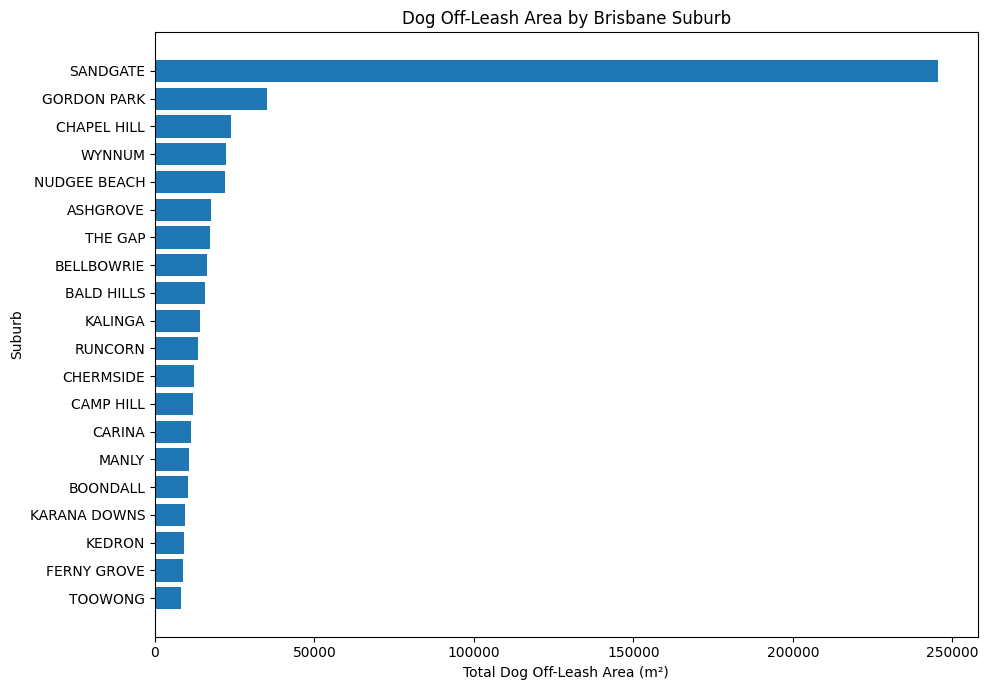

In [3]:
import matplotlib.pyplot as plt

top20 = suburb_dog_exposure.nlargest(20, "Total_Dog_Area_m2").sort_values(
    "Total_Dog_Area_m2"
)

plt.figure(figsize=(10, 7))

plt.barh(
    top20["SUBURB"],
    top20["Total_Dog_Area_m2"]
)

plt.xlabel("Total Dog Off-Leash Area (m²)")
plt.ylabel("Suburb")
plt.title("Dog Off-Leash Area by Brisbane Suburb")

plt.tight_layout()
plt.show()

In [4]:
# Check the Sandgate records
sandgate = dog_parks[
    dog_parks["SUBURB"].str.upper() == "SANDGATE"
][
    ["PARK_NAME", "ITEM_DESCRIPTION", "Shape__Area", "LAT", "LONG"]
]

display(sandgate)

,PARK_NAME,ITEM_DESCRIPTION,Shape__Area,LAT,LONG
12,SANDGATE FORESHORES PARK,SANDGATE FORESHORE DOG OFF LEASH AREA,239968.338867,-27.319284,153.076627
151,CURLEW PARK,CURLEW PK DOG OFF LEASH AREA,5679.561523,-27.326509,153.073360


In [5]:
import numpy as np

# Create suburb-level dog outdoor exposure dataset
dog_exposure = (
    dog_parks.groupby("SUBURB")
    .agg(
        Dog_Area_Count=("PARK_NAME", "count"),
        Total_Dog_Area_m2=("Shape__Area", "sum"),
        Mean_LAT=("LAT", "mean"),
        Mean_LONG=("LONG", "mean")
    )
    .reset_index()
)

# Log transform because Sandgate and some other areas are very large outliers
dog_exposure["Log_Dog_Area"] = np.log1p(
    dog_exposure["Total_Dog_Area_m2"]
)

dog_exposure = dog_exposure.sort_values(
    "Total_Dog_Area_m2",
    ascending=False
).reset_index(drop=True)

display(dog_exposure.head(20))

print("Suburbs:", len(dog_exposure))

,SUBURB,Dog_Area_Count,Total_Dog_Area_m2,Mean_LAT,Mean_LONG,Log_Dog_Area
0,SANDGATE,2,245647.900391,-27.322896,153.074993,12.411659
1,GORDON PARK,5,35088.654053,-27.420653,153.029042,10.465662
2,CHAPEL HILL,3,23938.188232,-27.498015,152.949463,10.083272
3,WYNNUM,1,22362.268311,-27.426761,153.167958,10.015175
4,NUDGEE BEACH,2,21873.566162,-27.350108,153.106702,9.993080
5,ASHGROVE,2,17554.777100,-27.445780,152.980568,9.773138
6,THE GAP,3,17117.876709,-27.447458,152.941078,9.747937
7,BELLBOWRIE,2,16294.893311,-27.562449,152.883229,9.698668
8,BALD HILLS,3,15680.693604,-27.304722,153.014377,9.660249
9,KALINGA,2,14114.498291,-27.407275,153.046774,9.555029


Suburbs: 116


In [6]:
import pandas as pd

brisbane_weather = pd.read_csv("curious_cat/brisbane_weather.csv")

print("Shape:", brisbane_weather.shape)

print("\nColumns:")
print(brisbane_weather.columns.tolist())

display(brisbane_weather.head())


Shape: (28478, 6)

Columns:
['latitude', 'longitude', 'elevation', 'utc_offset_seconds', 'timezone', 'timezone_abbreviation']


,latitude,longitude,elevation,utc_offset_seconds,timezone,timezone_abbreviation
0,-27.45167,153.02014,27.0,36000,Australia/Sydney,GMT+10
1,time,temperature_2m (°C),precipitation (mm),relative_humidity_2m (%),NaN,NaN
2,2023-07-01T00:00,9.2,0.00,65,NaN,NaN
3,2023-07-01T01:00,8.9,0.00,67,NaN,NaN
4,2023-07-01T02:00,8.7,0.00,69,NaN,NaN


In [7]:
import pandas as pd
import csv

file_path = "curious_cat/brisbane_weather.csv"

rows = []

with open(file_path, "r", encoding="utf-8") as f:
    reader = csv.reader(f)

    for row in reader:
        # Keep only hourly rows such as 2023-07-01T00:00
        if (
            len(row) >= 4
            and row[0][:4].isdigit()
            and "T" in row[0]
        ):
            rows.append(row[:4])

brisbane_weather = pd.DataFrame(
    rows,
    columns=[
        "time",
        "temperature_C",
        "precipitation_mm",
        "relative_humidity_pct"
    ]
)

# Convert data types
brisbane_weather["time"] = pd.to_datetime(
    brisbane_weather["time"],
    errors="coerce"
)

for col in [
    "temperature_C",
    "precipitation_mm",
    "relative_humidity_pct"
]:
    brisbane_weather[col] = pd.to_numeric(
        brisbane_weather[col],
        errors="coerce"
    )

brisbane_weather = brisbane_weather.dropna(subset=["time"])

print("Shape:", brisbane_weather.shape)
print("Date range:",
      brisbane_weather["time"].min(),
      "to",
      brisbane_weather["time"].max())

display(brisbane_weather.head())
display(brisbane_weather.tail())

Shape: (27336, 4)
Date range: 2023-07-01 00:00:00 to 2026-08-12 23:00:00


,time,temperature_C,precipitation_mm,relative_humidity_pct
0,2023-07-01 00:00:00,9.2,0.0,65
1,2023-07-01 01:00:00,8.9,0.0,67
2,2023-07-01 02:00:00,8.7,0.0,69
3,2023-07-01 03:00:00,8.5,0.0,70
4,2023-07-01 04:00:00,8.2,0.0,72


,time,temperature_C,precipitation_mm,relative_humidity_pct
27331,2026-08-12 19:00:00,16.1,0.2,61
27332,2026-08-12 20:00:00,14.4,1.1,71
27333,2026-08-12 21:00:00,13.5,0.6,75
27334,2026-08-12 22:00:00,13.1,0.0,83
27335,2026-08-12 23:00:00,14.5,0.0,66


In [8]:
# Convert hourly Brisbane weather to weekly rainfall

brisbane_weekly_rain = (
    brisbane_weather
    .set_index("time")
    .resample("W-SUN")
    .agg(
        Rainfall_mm=("precipitation_mm", "sum")
    )
    .reset_index()
    .rename(columns={"time": "Week_End"})
)

print("Shape:", brisbane_weekly_rain.shape)

print(
    "Date range:",
    brisbane_weekly_rain["Week_End"].min(),
    "to",
    brisbane_weekly_rain["Week_End"].max()
)

display(brisbane_weekly_rain.head(10))
display(brisbane_weekly_rain.tail(10))

Shape: (164, 2)
Date range: 2023-07-02 00:00:00 to 2026-08-16 00:00:00


,Week_End,Rainfall_mm
0,2023-07-02,0.0
1,2023-07-09,27.5
2,2023-07-16,0.7
3,2023-07-23,2.8
4,2023-07-30,0.0
5,2023-08-06,5.4
6,2023-08-13,0.6
7,2023-08-20,2.6
8,2023-08-27,2.4
9,2023-09-03,4.2


,Week_End,Rainfall_mm
154,2026-06-14,38.0
155,2026-06-21,1.8
156,2026-06-28,14.7
157,2026-07-05,3.7
158,2026-07-12,1.9
159,2026-07-19,7.2
160,2026-07-26,2.3
161,2026-08-02,1.6
162,2026-08-09,0.4
163,2026-08-16,6.7


In [9]:
# Previous 8 completed weeks of cumulative Brisbane rainfall

brisbane_weekly_rain["Rainfall_prev8w"] = (
    brisbane_weekly_rain["Rainfall_mm"]
    .shift(1)
    .rolling(window=8)
    .sum()
)

display(
    brisbane_weekly_rain[
        ["Week_End", "Rainfall_mm", "Rainfall_prev8w"]
    ].head(15)
)

print(
    "Available 8-week rainfall observations:",
    brisbane_weekly_rain["Rainfall_prev8w"].notna().sum()
)

,Week_End,Rainfall_mm,Rainfall_prev8w
0,2023-07-02,0.0,NaN
1,2023-07-09,27.5,NaN
2,2023-07-16,0.7,NaN
3,2023-07-23,2.8,NaN
4,2023-07-30,0.0,NaN
5,2023-08-06,5.4,NaN
6,2023-08-13,0.6,NaN
7,2023-08-20,2.6,NaN
8,2023-08-27,2.4,39.6
9,2023-09-03,4.2,42.0


Available 8-week rainfall observations: 156


In [10]:
# Show all pandas DataFrames currently loaded

for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame):
        print(name, obj.shape)

dog_parks (172, 17)
suburb_dog_exposure (116, 4)
top20 (20, 4)
sandgate (2, 5)
dog_exposure (116, 6)
brisbane_weather (27336, 4)
brisbane_weekly_rain (164, 3)


In [11]:
import os

for root, dirs, files in os.walk("."):
    for file in files:
        if file.lower().endswith(".csv"):
            print(os.path.join(root, file))

./qld_sa2_population_income.csv
./tracksandtrails.csv
./vetiq_weekly.csv
./basket_1.csv
./locality.csv
./basket_3.csv
./basket_2.csv
./dog_tick_brisbane.csv
./External Datasets/gbif/0012527-260806074905277.csv
./External Datasets/gbif/gbif_qld_ticks_clean.csv
./External Datasets/ABS Census and SEIFA/2021 Census GCP Statistical Area 2 for QLD/2021Census_G48B_QLD_SA2.csv
./External Datasets/ABS Census and SEIFA/2021 Census GCP Statistical Area 2 for QLD/2021Census_G10A_QLD_SA2.csv
./External Datasets/ABS Census and SEIFA/2021 Census GCP Statistical Area 2 for QLD/2021Census_G53C_QLD_SA2.csv
./External Datasets/ABS Census and SEIFA/2021 Census GCP Statistical Area 2 for QLD/2021Census_G17A_QLD_SA2.csv
./External Datasets/ABS Census and SEIFA/2021 Census GCP Statistical Area 2 for QLD/2021Census_G54C_QLD_SA2.csv
./External Datasets/ABS Census and SEIFA/2021 Census GCP Statistical Area 2 for QLD/2021Census_G38_QLD_SA2.csv
./External Datasets/ABS Census and SEIFA/2021 Census GCP Statistical 

In [12]:
import pandas as pd

clinics = pd.read_csv("cleaned/clinics_01.csv")

print("Shape:", clinics.shape)

print("\nColumns:")
print(clinics.columns.tolist())

display(clinics.head(10))

Shape: (61, 6)

Columns:
['Clinic_01', '4508', 'Deception Bay', 'QLD', 'AU', 'RXWorks']


,Clinic_01,4508,Deception Bay,QLD,AU,RXWorks
0,Clinic_02,4703,Yeppoon,QLD,AU,RXWorks
1,Clinic_03,4300,Augustine Heights,QLD,AU,Ascend
2,Clinic_04,4301,Redbank Plains,QLD,AU,Ascend
3,Clinic_05,4300,Springfield,QLD,AU,Ascend
4,Clinic_06,4124,Greenbank,QLD,AU,Ascend
5,Clinic_07,4280,North MacLean,QLD,AU,Ascend
6,Clinic_08,4350,Harristown,QLD,AU,Petbooqz
7,Clinic_09,4076,Darra,QLD,AU,Petbooqz
8,Clinic_10,4223,Currumbin Waters,QLD,AU,RXWorks
9,Clinic_11,4112,Kuraby,QLD,AU,RXWorks


In [13]:
appointments = pd.read_csv("cleaned/appointments.csv")

print("Shape:", appointments.shape)

print("\nColumns:")
print(appointments.columns.tolist())

display(appointments.head(5))

Shape: (2448979, 9)

Columns:
['AppointmentKey', 'ClientKey', 'PatientKey', 'ClinicPseudonym', 'AppointmentDate', 'AppointmentDateTime', 'AppointmentTypeName', 'AppointmentDurationDecimal', 'StatusName']


,AppointmentKey,ClientKey,PatientKey,ClinicPseudonym,AppointmentDate,AppointmentDateTime,AppointmentTypeName,AppointmentDurationDecimal,StatusName
0,DFB3F4E62681129D7160C86FA7CA59C6CAB1B016EEC1BA...,41DBE2408BEFB062CA590A685409D20904205FAA040303...,41DBE2408BEFB062CA590A685409D20904205FAA040303...,Clinic_31,2023-07-27,2023-07-27 07:00:00.0000000,Block Out,40.0,Scheduled
1,F793BA6D6EAF572B1CF9D7223C6F3D72F03DC36107B3E0...,41DBE2408BEFB062CA590A685409D20904205FAA040303...,41DBE2408BEFB062CA590A685409D20904205FAA040303...,Clinic_31,2023-07-27,2023-07-27 07:00:00.0000000,Block Out,790.0,Scheduled
2,2CD128946F1117E839CFF15C9016B26386C77B24C11757...,41DBE2408BEFB062CA590A685409D20904205FAA040303...,41DBE2408BEFB062CA590A685409D20904205FAA040303...,Clinic_31,2023-07-27,2023-07-27 07:00:00.0000000,Block Out,40.0,Scheduled
3,555397E5DBC514794E24763AAEEE06DF1CBAAE07A72D0E...,41DBE2408BEFB062CA590A685409D20904205FAA040303...,41DBE2408BEFB062CA590A685409D20904205FAA040303...,Clinic_31,2023-07-27,2023-07-27 07:00:00.0000000,Block Out,130.0,Scheduled
4,1AE087443AF401AAC513163481BF922A5AB24C5AEDD0FB...,41DBE2408BEFB062CA590A685409D20904205FAA040303...,41DBE2408BEFB062CA590A685409D20904205FAA040303...,Clinic_31,2023-07-27,2023-07-27 07:00:00.0000000,Block Out,790.0,Scheduled


In [14]:
clinics = pd.read_csv(
    "cleaned/clinics_01.csv",
    header=None,
    names=[
        "Clinic_ID",
        "Postcode",
        "Suburb",
        "State",
        "Country",
        "System"
    ]
)

print("Shape:", clinics.shape)
display(clinics.head(10))

Shape: (62, 6)


,Clinic_ID,Postcode,Suburb,State,Country,System
0,Clinic_01,4508,Deception Bay,QLD,AU,RXWorks
1,Clinic_02,4703,Yeppoon,QLD,AU,RXWorks
2,Clinic_03,4300,Augustine Heights,QLD,AU,Ascend
3,Clinic_04,4301,Redbank Plains,QLD,AU,Ascend
4,Clinic_05,4300,Springfield,QLD,AU,Ascend
5,Clinic_06,4124,Greenbank,QLD,AU,Ascend
6,Clinic_07,4280,North MacLean,QLD,AU,Ascend
7,Clinic_08,4350,Harristown,QLD,AU,Petbooqz
8,Clinic_09,4076,Darra,QLD,AU,Petbooqz
9,Clinic_10,4223,Currumbin Waters,QLD,AU,RXWorks


In [15]:
consultations = pd.read_csv("cleaned/consultations_freetext.csv")

print("Shape:", consultations.shape)
print("\nColumns:")
print(consultations.columns.tolist())

display(consultations.head())

/var/folders/_w/whgh5msd3m51z0f722vzc5140000gn/T/ipykernel_16572/3287596300.py:1: DtypeWarning: Columns (3,4,5) have mixed types. Specify dtype option on import or set low_memory=False.
  consultations = pd.read_csv("cleaned/consultations_freetext.csv")


Shape: (6748676, 9)

Columns:
['ConsultationKey', 'ClinicPseudonym', 'ConsultationDate', 'ExaminationTextString', 'SummaryString', 'SpecialInstructionString', 'PossibleNameMatch_ClientFirstName', 'PossibleNameMatch_ClientLastName', 'PossibleNameMatch_PatientName']


,ConsultationKey,ClinicPseudonym,ConsultationDate,ExaminationTextString,SummaryString,SpecialInstructionString,PossibleNameMatch_ClientFirstName,PossibleNameMatch_ClientLastName,PossibleNameMatch_PatientName
0,9A763DD0D42112D82E510D667E5F4A5F1E6FA1A3F2B42C...,Clinic_01,2023-07-27,Reason: Admit For BGC Fed 1 cup dry food at 6...,NaN,NaN,0,0,0
1,854150406CECBEE128992D93EF0FB60DBE7407E6A98AE1...,Clinic_01,2023-07-27,Reason: Admit For BGC Fed 1 cup dry food at 6...,NaN,NaN,0,0,0
2,AF349A69219EA3A30DC4785DF88BB03F8B8B9607C05C8F...,Clinic_01,2023-07-27,Reason: Admit For BGC Fed 1 cup dry food at 6...,NaN,NaN,0,0,0
3,046230348560935F217B0BAE398CEFCEA7DB38EA0A8B84...,Clinic_01,2023-07-27,Reason: Castrate PABT: all WNL No audible hea...,NaN,NaN,0,0,0
4,01D67E1A0AF6ABC7889D7610D984B2179C49EFC6A56161...,Clinic_01,2023-07-27,Reason: Castrate PABT: all WNL No audible hea...,NaN,NaN,0,0,0


In [16]:
# Convert consultation date
consultations["ConsultationDate"] = pd.to_datetime(
    consultations["ConsultationDate"],
    errors="coerce"
)

# Combine the useful consultation text fields
text_cols = [
    "ExaminationTextString",
    "SummaryString",
    "SpecialInstructionString"
]

consultations["CombinedText"] = (
    consultations[text_cols]
    .fillna("")
    .astype(str)
    .agg(" ".join, axis=1)
)

# Identify consultations mentioning ticks
tick_mask = consultations["CombinedText"].str.contains(
    r"\btick\b|\bticks\b|paralysis tick",
    case=False,
    regex=True,
    na=False
)

tick_consultations = consultations.loc[
    tick_mask,
    ["ConsultationKey", "ClinicPseudonym", "ConsultationDate", "CombinedText"]
].copy()

print("Tick-related records:", len(tick_consultations))
print("Date range:",
      tick_consultations["ConsultationDate"].min(),
      "to",
      tick_consultations["ConsultationDate"].max())

print("Clinics represented:",
      tick_consultations["ClinicPseudonym"].nunique())

display(tick_consultations.head(10))

Tick-related records: 465599
Date range: 2023-07-27 00:00:00 to 2026-07-26 00:00:00
Clinics represented: 33


,ConsultationKey,ClinicPseudonym,ConsultationDate,CombinedText
235,BEBBCB79477D1C8E7B2E1AA7072CF91ADD28B2DD4424C6...,Clinic_02,2023-07-27,Reason: Unable To Jump Appointment Notes: can ...
236,B41F02D0BDF99E0C13D2A6DDAC6C1D735E345B980D6BC5...,Clinic_02,2023-07-27,Reason: Unable To Jump Appointment Notes: can ...
252,2AA1CA0DCEAD1508772DA06976B4823E3C28A935A012BF...,Clinic_02,2023-07-27,"Reason: Bee Sting, Swollen Eye 3rd Vac, Flea T..."
253,642DFBF712AF96DB9299559599A03F664A8A0319AC3FDA...,Clinic_02,2023-07-27,"Reason: Bee Sting, Swollen Eye 3rd Vac, Flea T..."
254,FFDD7584929DEAE921AFFDA3AD478EFCC20884F245440E...,Clinic_02,2023-07-27,"Reason: Bee Sting, Swollen Eye 3rd Vac, Flea T..."
255,CB5BFC59A3AD3EC41AB939E41A3AFF6DFF862A50F5BD1A...,Clinic_02,2023-07-27,"Reason: Bee Sting, Swollen Eye 3rd Vac, Flea T..."
387,E98135DE4DE1E7A66191F277B793121A3DF4E4E16DC639...,Clinic_04,2023-07-27,"Reason: Scab on tail, O's keeping it clean but..."
388,1ED26E55BFAE4AA1158048E14FF625526D8CEE866AC65C...,Clinic_04,2023-07-27,"Reason: Scab on tail, O's keeping it clean but..."
395,9CFBC092A42DD4932485D17DD1EA5A1AC80723831ED3C4...,Clinic_04,2023-07-27,"Reason: C5, has some lumps/warts O wants check..."
396,3470F40D382C1D76AD5105D15D952D19BE68182B7FBC49...,Clinic_04,2023-07-27,"Reason: C5, has some lumps/warts O wants check..."


In [17]:
# Stricter extraction of likely tick-related consultations

specific_tick_pattern = (
    r"paralysis[\s-]?tick|"
    r"tick[\s-]?paralysis|"
    r"tick\s+(?:bite|attachment|attached|removal|removed)|"
    r"(?:found|remove|removed|attached)\s+(?:a\s+)?tick|"
    r"tick\s+toxicosis"
)

strict_mask = (
    consultations["ExaminationTextString"]
        .fillna("")
        .str.contains(specific_tick_pattern, case=False, regex=True)
    |
    consultations["SummaryString"]
        .fillna("")
        .str.contains(specific_tick_pattern, case=False, regex=True)
    |
    consultations["SpecialInstructionString"]
        .fillna("")
        .str.contains(specific_tick_pattern, case=False, regex=True)
)

tick_cases_strict = consultations.loc[
    strict_mask,
    [
        "ConsultationKey",
        "ClinicPseudonym",
        "ConsultationDate",
        "ExaminationTextString"
    ]
].copy()

tick_cases_strict = tick_cases_strict.drop_duplicates("ConsultationKey")

print("Likely tick-related consultations:", len(tick_cases_strict))
print("Clinics represented:", tick_cases_strict["ClinicPseudonym"].nunique())
print(
    "Date range:",
    tick_cases_strict["ConsultationDate"].min(),
    "to",
    tick_cases_strict["ConsultationDate"].max()
)

display(tick_cases_strict.head(10))

Likely tick-related consultations: 24625
Clinics represented: 32
Date range: 2023-07-27 00:00:00 to 2026-07-25 00:00:00


,ConsultationKey,ClinicPseudonym,ConsultationDate,ExaminationTextString
235,BEBBCB79477D1C8E7B2E1AA7072CF91ADD28B2DD4424C6...,Clinic_02,2023-07-27,Reason: Unable To Jump Appointment Notes: can ...
236,B41F02D0BDF99E0C13D2A6DDAC6C1D735E345B980D6BC5...,Clinic_02,2023-07-27,Reason: Unable To Jump Appointment Notes: can ...
395,9CFBC092A42DD4932485D17DD1EA5A1AC80723831ED3C4...,Clinic_04,2023-07-27,"Reason: C5, has some lumps/warts O wants check..."
396,3470F40D382C1D76AD5105D15D952D19BE68182B7FBC49...,Clinic_04,2023-07-27,"Reason: C5, has some lumps/warts O wants check..."
397,BD378369EDF41E53B3A0CF5D4A5599334C2C88988DA675...,Clinic_04,2023-07-27,"Reason: C5, has some lumps/warts O wants check..."
398,29A8626A170240018D474D445A596821D56AAA9AB0EA2E...,Clinic_04,2023-07-27,"Reason: C5, has some lumps/warts O wants check..."
399,3C2EBDCC0B311DB6C2CD82C5571EE66E34A6EA9D9A841D...,Clinic_04,2023-07-27,"Reason: C5, has some lumps/warts O wants check..."
400,9BED6F26CAE30F5A6FD65C1DCB2AE05AAB85909CD308F3...,Clinic_04,2023-07-27,"Reason: C5, has some lumps/warts O wants check..."
401,BCCBD55463A3575DBFF963C4A99535FB05242CA5DED58C...,Clinic_04,2023-07-27,"Reason: C5, has some lumps/warts O wants check..."
402,447FBBE956E25F736C3836818CC1ED66A8086DE4D36690...,Clinic_04,2023-07-27,"Reason: C5, has some lumps/warts O wants check..."


In [18]:
# Merge tick consultations with clinic location

tick_regional = tick_cases_strict.merge(
    clinics[
        ["Clinic_ID", "Postcode", "Suburb", "State"]
    ],
    left_on="ClinicPseudonym",
    right_on="Clinic_ID",
    how="left"
)

print("Tick records:", len(tick_regional))
print("Matched to location:", tick_regional["Suburb"].notna().sum())
print("Unmatched:", tick_regional["Suburb"].isna().sum())

# Count tick-related consultations by suburb
regional_summary = (
    tick_regional
    .groupby(["Suburb", "Postcode"], as_index=False)
    .agg(
        Tick_Consultations=("ConsultationKey", "nunique"),
        Clinic_Count=("ClinicPseudonym", "nunique")
    )
    .sort_values("Tick_Consultations", ascending=False)
)

display(regional_summary.head(20))

Tick records: 24625
Matched to location: 24625
Unmatched: 0


,Suburb,Postcode,Tick_Consultations,Clinic_Count
26,Trinity Beach,4879,2847,1
1,Augustine Heights,4300,2278,1
3,Beaudesert,4285,1947,1
23,Redbank Plains,4301,1890,1
30,Yeppoon,4703,1417,1
10,Greenbank,4124,1341,2
28,Wilsonton,4350,1079,1
20,North MacLean,4280,1055,1
4,Cairns City,4870,955,1
8,Flagstone,4280,862,1


In [19]:
# Greater Brisbane / nearby SEQ focus
# Using postcode range as a practical regional grouping for this exploratory analysis

brisbane_region = tick_regional[
    tick_regional["Postcode"].between(4000, 4300)
].copy()

brisbane_summary = (
    brisbane_region
    .groupby(["Suburb", "Postcode"], as_index=False)
    .agg(
        Tick_Consultations=("ConsultationKey", "nunique"),
        Clinic_Count=("ClinicPseudonym", "nunique")
    )
    .sort_values("Tick_Consultations", ascending=False)
)

print("Total tick-related consultations:", 
      brisbane_region["ConsultationKey"].nunique())

print("Clinics:", brisbane_region["ClinicPseudonym"].nunique())

print("Suburbs:", brisbane_region["Suburb"].nunique())

display(brisbane_summary)

Total tick-related consultations: 12643
Clinics: 20
Suburbs: 19


,Suburb,Postcode,Tick_Consultations,Clinic_Count
1,Augustine Heights,4300,2278,1
3,Beaudesert,4285,1947,1
7,Greenbank,4124,1341,2
14,North MacLean,4280,1055,1
5,Flagstone,4280,862,1
16,Springfield,4300,797,1
0,Ashgrove,4060,735,1
9,Jimboomba,4280,589,1
2,Bardon,4065,505,1
12,Loganholme,4129,477,1


In [20]:
# Create weekly tick-related consultation demand for SEQ

seq_weekly_ticks = (
    brisbane_region
    .set_index("ConsultationDate")
    .resample("W-SUN")
    .agg(
        Tick_Consultations=("ConsultationKey", "nunique")
    )
    .reset_index()
    .rename(columns={"ConsultationDate": "Week_End"})
)

# Make sure dates match
seq_weekly_ticks["Week_End"] = pd.to_datetime(
    seq_weekly_ticks["Week_End"]
)

brisbane_weekly_rain["Week_End"] = pd.to_datetime(
    brisbane_weekly_rain["Week_End"]
)

# Merge tick demand with rainfall
seq_rain = seq_weekly_ticks.merge(
    brisbane_weekly_rain[
        ["Week_End", "Rainfall_mm", "Rainfall_prev8w"]
    ],
    on="Week_End",
    how="inner"
)

print("Weeks available:", len(seq_rain))
print(
    "Period:",
    seq_rain["Week_End"].min(),
    "to",
    seq_rain["Week_End"].max()
)

display(seq_rain.head(12))

Weeks available: 157
Period: 2023-07-30 00:00:00 to 2026-07-26 00:00:00


,Week_End,Tick_Consultations,Rainfall_mm,Rainfall_prev8w
0,2023-07-30,15,0.0,NaN
1,2023-08-06,38,5.4,NaN
2,2023-08-13,17,0.6,NaN
3,2023-08-20,104,2.6,NaN
4,2023-08-27,104,2.4,39.6
5,2023-09-03,90,4.2,42.0
6,2023-09-10,86,10.1,18.7
7,2023-09-17,228,6.9,28.1
8,2023-09-24,151,0.4,32.2
9,2023-10-01,138,19.4,32.6


In [21]:
from scipy.stats import spearmanr
import pandas as pd

results = []

# Current weekly rainfall -> future tick consultations
for lead in range(5):

    temp = seq_rain[
        ["Rainfall_mm", "Tick_Consultations"]
    ].copy()

    # Tick demand lead weeks into the future
    temp["Future_Tick_Demand"] = (
        temp["Tick_Consultations"].shift(-lead)
    )

    temp = temp.dropna()

    rho, p = spearmanr(
        temp["Rainfall_mm"],
        temp["Future_Tick_Demand"]
    )

    results.append({
        "Rainfall_Measure": "Weekly rainfall",
        "Lead_Weeks": lead,
        "Spearman_rho": rho,
        "p_value": p,
        "N": len(temp)
    })


# Previous 8-week rainfall -> future tick consultations
for lead in range(5):

    temp = seq_rain[
        ["Rainfall_prev8w", "Tick_Consultations"]
    ].copy()

    temp["Future_Tick_Demand"] = (
        temp["Tick_Consultations"].shift(-lead)
    )

    temp = temp.dropna()

    rho, p = spearmanr(
        temp["Rainfall_prev8w"],
        temp["Future_Tick_Demand"]
    )

    results.append({
        "Rainfall_Measure": "Previous 8-week rainfall",
        "Lead_Weeks": lead,
        "Spearman_rho": rho,
        "p_value": p,
        "N": len(temp)
    })


rain_lead_results = pd.DataFrame(results)

display(
    rain_lead_results.round({
        "Spearman_rho": 3,
        "p_value": 4
    })
)

,Rainfall_Measure,Lead_Weeks,Spearman_rho,p_value,N
0,Weekly rainfall,0,-0.155,0.0529,157
1,Weekly rainfall,1,-0.206,0.0099,156
2,Weekly rainfall,2,-0.105,0.1917,155
3,Weekly rainfall,3,-0.188,0.0198,154
4,Weekly rainfall,4,-0.292,0.0002,153
5,Previous 8-week rainfall,0,-0.513,0.0000,153
6,Previous 8-week rainfall,1,-0.552,0.0000,152
7,Previous 8-week rainfall,2,-0.594,0.0000,151
8,Previous 8-week rainfall,3,-0.622,0.0000,150
9,Previous 8-week rainfall,4,-0.633,0.0000,149


In [22]:
import numpy as np
import pandas as pd
from scipy.stats import spearmanr
from sklearn.linear_model import LinearRegression

season_df = seq_rain.copy()

# Week of year
season_df["Week_of_Year"] = (
    season_df["Week_End"]
    .dt.isocalendar()
    .week
    .astype(int)
)

# Annual seasonal cycle
season_df["Season_Sin"] = np.sin(
    2 * np.pi * season_df["Week_of_Year"] / 52
)

season_df["Season_Cos"] = np.cos(
    2 * np.pi * season_df["Week_of_Year"] / 52
)

season_features = ["Season_Sin", "Season_Cos"]

results_adjusted = []

for rainfall_col in ["Rainfall_mm", "Rainfall_prev8w"]:

    for lead in range(5):

        temp = season_df[
            [
                rainfall_col,
                "Tick_Consultations",
                "Season_Sin",
                "Season_Cos"
            ]
        ].copy()

        # Future tick demand
        temp["Future_Tick_Demand"] = (
            temp["Tick_Consultations"].shift(-lead)
        )

        temp = temp.dropna()

        X = temp[season_features]

        # Remove seasonality from rainfall
        rain_model = LinearRegression().fit(
            X,
            temp[rainfall_col]
        )

        temp["Rain_Residual"] = (
            temp[rainfall_col]
            - rain_model.predict(X)
        )

        # Remove seasonality from future tick demand
        tick_model = LinearRegression().fit(
            X,
            temp["Future_Tick_Demand"]
        )

        temp["Tick_Residual"] = (
            temp["Future_Tick_Demand"]
            - tick_model.predict(X)
        )

        # Correlation after removing seasonality
        rho, p = spearmanr(
            temp["Rain_Residual"],
            temp["Tick_Residual"]
        )

        results_adjusted.append({
            "Rainfall_Measure": rainfall_col,
            "Lead_Weeks": lead,
            "Adjusted_rho": rho,
            "p_value": p,
            "N": len(temp)
        })

season_adjusted_results = pd.DataFrame(results_adjusted)

display(
    season_adjusted_results.round({
        "Adjusted_rho": 3,
        "p_value": 4
    })
)

,Rainfall_Measure,Lead_Weeks,Adjusted_rho,p_value,N
0,Rainfall_mm,0,-0.115,0.1500,157
1,Rainfall_mm,1,-0.123,0.1268,156
2,Rainfall_mm,2,0.014,0.8648,155
3,Rainfall_mm,3,-0.032,0.6963,154
4,Rainfall_mm,4,-0.091,0.2647,153
5,Rainfall_prev8w,0,-0.045,0.5783,153
6,Rainfall_prev8w,1,-0.049,0.5462,152
7,Rainfall_prev8w,2,-0.031,0.7017,151
8,Rainfall_prev8w,3,-0.035,0.6701,150
9,Rainfall_prev8w,4,-0.019,0.8170,149


In [23]:
# Create weekly Brisbane temperature

brisbane_weekly_temp = (
    brisbane_weather
    .set_index("time")
    .resample("W-SUN")
    .agg(
        Avg_Temperature_C=("temperature_C", "mean"),
        Max_Temperature_C=("temperature_C", "max"),
        Rainfall_mm=("precipitation_mm", "sum")
    )
    .reset_index()
    .rename(columns={"time": "Week_End"})
)

display(brisbane_weekly_temp.head())

print(
    "Period:",
    brisbane_weekly_temp["Week_End"].min(),
    "to",
    brisbane_weekly_temp["Week_End"].max()
)

,Week_End,Avg_Temperature_C,Max_Temperature_C,Rainfall_mm
0,2023-07-02,14.006250,21.9,0.0
1,2023-07-09,16.026190,24.3,27.5
2,2023-07-16,14.913095,23.7,0.7
3,2023-07-23,14.701786,24.1,2.8
4,2023-07-30,15.488095,25.2,0.0


Period: 2023-07-02 00:00:00 to 2026-08-16 00:00:00


In [24]:
import numpy as np
import pandas as pd
from scipy.stats import spearmanr
from sklearn.linear_model import LinearRegression

# Merge SEQ tick consultations with Brisbane temperature
temp_tick = seq_weekly_ticks.merge(
    brisbane_weekly_temp[
        ["Week_End", "Avg_Temperature_C", "Max_Temperature_C"]
    ],
    on="Week_End",
    how="inner"
)

# Seasonality variables
temp_tick["Week_of_Year"] = (
    temp_tick["Week_End"].dt.isocalendar().week.astype(int)
)

temp_tick["Season_Sin"] = np.sin(
    2 * np.pi * temp_tick["Week_of_Year"] / 52
)

temp_tick["Season_Cos"] = np.cos(
    2 * np.pi * temp_tick["Week_of_Year"] / 52
)

results = []

for temp_col in ["Avg_Temperature_C", "Max_Temperature_C"]:

    for lead in range(5):

        df_test = temp_tick[
            [
                temp_col,
                "Tick_Consultations",
                "Season_Sin",
                "Season_Cos"
            ]
        ].copy()

        # Future tick consultations
        df_test["Future_Tick_Demand"] = (
            df_test["Tick_Consultations"].shift(-lead)
        )

        df_test = df_test.dropna()

        # -----------------------
        # RAW CORRELATION
        # -----------------------
        raw_rho, raw_p = spearmanr(
            df_test[temp_col],
            df_test["Future_Tick_Demand"]
        )

        # -----------------------
        # REMOVE SEASONALITY
        # -----------------------
        X = df_test[["Season_Sin", "Season_Cos"]]

        temp_model = LinearRegression().fit(
            X,
            df_test[temp_col]
        )

        tick_model = LinearRegression().fit(
            X,
            df_test["Future_Tick_Demand"]
        )

        temp_residual = (
            df_test[temp_col] -
            temp_model.predict(X)
        )

        tick_residual = (
            df_test["Future_Tick_Demand"] -
            tick_model.predict(X)
        )

        adjusted_rho, adjusted_p = spearmanr(
            temp_residual,
            tick_residual
        )

        results.append({
            "Temperature": temp_col,
            "Lead_Weeks": lead,
            "Raw_rho": raw_rho,
            "Raw_p": raw_p,
            "Adjusted_rho": adjusted_rho,
            "Adjusted_p": adjusted_p,
            "N": len(df_test)
        })

temperature_results = pd.DataFrame(results)

display(
    temperature_results.round({
        "Raw_rho": 3,
        "Raw_p": 4,
        "Adjusted_rho": 3,
        "Adjusted_p": 4
    })
)

,Temperature,Lead_Weeks,Raw_rho,Raw_p,Adjusted_rho,Adjusted_p,N
0,Avg_Temperature_C,0,-0.093,0.2453,0.148,0.0637,157
1,Avg_Temperature_C,1,-0.171,0.0328,0.206,0.0100,156
2,Avg_Temperature_C,2,-0.285,0.0003,0.161,0.0451,155
3,Avg_Temperature_C,3,-0.377,0.0000,0.135,0.0954,154
4,Avg_Temperature_C,4,-0.443,0.0000,0.147,0.0689,153
5,Max_Temperature_C,0,0.131,0.1025,0.076,0.3470,157
6,Max_Temperature_C,1,0.111,0.1659,0.180,0.0247,156
7,Max_Temperature_C,2,-0.005,0.9475,0.151,0.0611,155
8,Max_Temperature_C,3,-0.072,0.3732,0.157,0.0517,154
9,Max_Temperature_C,4,-0.162,0.0456,0.063,0.4395,153


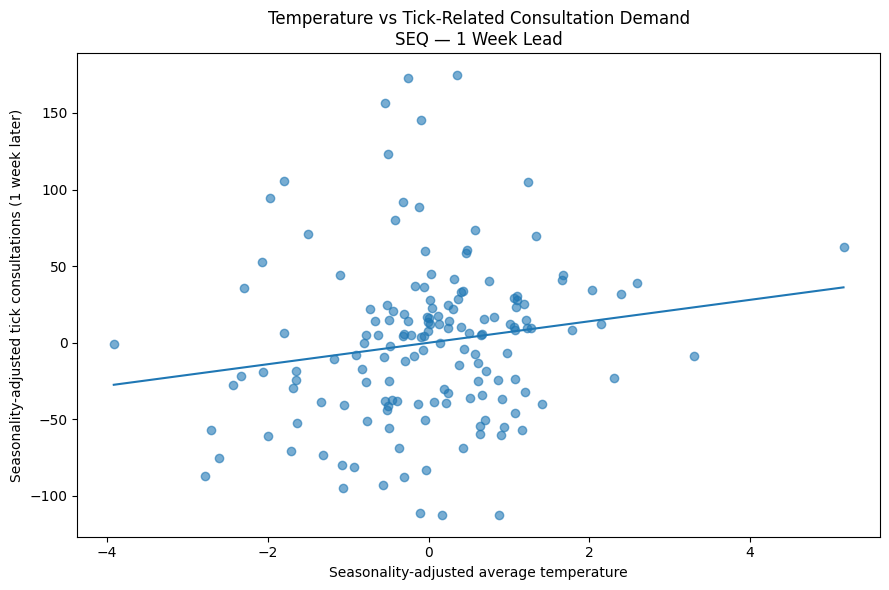

In [25]:
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
import numpy as np

plot_df = temp_tick[
    [
        "Avg_Temperature_C",
        "Tick_Consultations",
        "Season_Sin",
        "Season_Cos"
    ]
].copy()

# Tick consultations one week later
plot_df["Tick_Next_Week"] = (
    plot_df["Tick_Consultations"].shift(-1)
)

plot_df = plot_df.dropna()

X = plot_df[["Season_Sin", "Season_Cos"]]

# Remove seasonality from temperature
temp_model = LinearRegression().fit(
    X,
    plot_df["Avg_Temperature_C"]
)

plot_df["Temperature_Residual"] = (
    plot_df["Avg_Temperature_C"]
    - temp_model.predict(X)
)

# Remove seasonality from next-week tick demand
tick_model = LinearRegression().fit(
    X,
    plot_df["Tick_Next_Week"]
)

plot_df["Tick_Residual"] = (
    plot_df["Tick_Next_Week"]
    - tick_model.predict(X)
)

# Plot
plt.figure(figsize=(9, 6))

plt.scatter(
    plot_df["Temperature_Residual"],
    plot_df["Tick_Residual"],
    alpha=0.6
)

# Trend line
z = np.polyfit(
    plot_df["Temperature_Residual"],
    plot_df["Tick_Residual"],
    1
)

p = np.poly1d(z)

x_line = np.linspace(
    plot_df["Temperature_Residual"].min(),
    plot_df["Temperature_Residual"].max(),
    100
)

plt.plot(x_line, p(x_line))

plt.xlabel("Seasonality-adjusted average temperature")
plt.ylabel("Seasonality-adjusted tick consultations (1 week later)")

plt.title(
    "Temperature vs Tick-Related Consultation Demand\n"
    "SEQ — 1 Week Lead"
)

plt.tight_layout()
plt.show()

In [26]:
dog_exposure = (
    dog_parks.groupby("SUBURB")
    .agg(
        Dog_Area_Count=("PARK_NAME", "count"),
        Total_Dog_Area_m2=("Shape__Area", "sum"),
        Mean_LAT=("LAT", "mean"),
        Mean_LONG=("LONG", "mean")
    )
    .reset_index()
)

dog_exposure["Log_Dog_Area"] = np.log1p(
    dog_exposure["Total_Dog_Area_m2"]
)

In [27]:
# Standardise suburb names
dog_exposure["SUBURB_clean"] = (
    dog_exposure["SUBURB"]
    .str.upper()
    .str.strip()
)

tick_regional["Suburb_clean"] = (
    tick_regional["Suburb"]
    .str.upper()
    .str.strip()
)

# Find VetIQ clinic suburbs that also exist
# in the Brisbane dog off-leash dataset
matched_suburbs = (
    tick_regional[
        tick_regional["Suburb_clean"].isin(
            dog_exposure["SUBURB_clean"]
        )
    ][["Suburb", "Postcode", "Suburb_clean"]]
    .drop_duplicates()
    .sort_values("Suburb")
)

print("Matched VetIQ suburbs:", len(matched_suburbs))

display(matched_suburbs)

Matched VetIQ suburbs: 6


,Suburb,Postcode,Suburb_clean
327,Ashgrove,4060,ASHGROVE
13908,Darra,4076,DARRA
50,Kuraby,4112,KURABY
65,Northgate,4013,NORTHGATE
595,Virginia,4014,VIRGINIA
41,Wynnum,4178,WYNNUM


In [28]:
# Tick consultation totals for the 6 matched suburbs
matched_tick_summary = (
    tick_regional[
        tick_regional["Suburb_clean"].isin(
            matched_suburbs["Suburb_clean"]
        )
    ]
    .groupby("Suburb_clean")
    .agg(
        Tick_Consultations=("ConsultationKey", "nunique"),
        Clinic_Count=("ClinicPseudonym", "nunique")
    )
    .reset_index()
)

# Merge with dog off-leash exposure information
dog_tick_compare = matched_tick_summary.merge(
    dog_exposure[
        [
            "SUBURB_clean",
            "Dog_Area_Count",
            "Total_Dog_Area_m2",
            "Log_Dog_Area"
        ]
    ],
    left_on="Suburb_clean",
    right_on="SUBURB_clean",
    how="left"
)

dog_tick_compare = (
    dog_tick_compare
    .drop(columns="SUBURB_clean")
    .sort_values("Tick_Consultations", ascending=False)
)

display(dog_tick_compare)

,Suburb_clean,Tick_Consultations,Clinic_Count,Dog_Area_Count,Total_Dog_Area_m2,Log_Dog_Area
0,ASHGROVE,735,1,2,17554.777100,9.773138
5,WYNNUM,380,1,1,22362.268311,10.015175
3,NORTHGATE,235,1,1,2386.628174,7.778056
4,VIRGINIA,199,1,1,7537.466553,8.927774
2,KURABY,87,1,1,7668.041992,8.944947
1,DARRA,75,1,3,6201.998047,8.732788


In [29]:
from statsmodels.stats.multitest import multipletests

# Correct the 10 seasonality-adjusted temperature tests
temperature_results["FDR_p"] = multipletests(
    temperature_results["Adjusted_p"],
    method="fdr_bh"
)[1]

temperature_results["Significant_after_FDR"] = (
    temperature_results["FDR_p"] < 0.05
)

display(
    temperature_results[
        [
            "Temperature",
            "Lead_Weeks",
            "Adjusted_rho",
            "Adjusted_p",
            "FDR_p",
            "Significant_after_FDR"
        ]
    ].round(4)
)

,Temperature,Lead_Weeks,Adjusted_rho,Adjusted_p,FDR_p,Significant_after_FDR
0,Avg_Temperature_C,0,0.1483,0.0637,0.0984,False
1,Avg_Temperature_C,1,0.2056,0.0100,0.0984,False
2,Avg_Temperature_C,2,0.1612,0.0451,0.0984,False
3,Avg_Temperature_C,3,0.1349,0.0954,0.1192,False
4,Avg_Temperature_C,4,0.1475,0.0689,0.0984,False
5,Max_Temperature_C,0,0.0756,0.3470,0.3855,False
6,Max_Temperature_C,1,0.1798,0.0247,0.0984,False
7,Max_Temperature_C,2,0.1508,0.0611,0.0984,False
8,Max_Temperature_C,3,0.1571,0.0517,0.0984,False
9,Max_Temperature_C,4,0.0630,0.4395,0.4395,False


In [30]:
import os
import pandas as pd

# Search CSV files for possible clinic/location coordinate columns
results = []

for root, dirs, files in os.walk("."):
    for file in files:
        if file.endswith(".csv"):
            path = os.path.join(root, file)

            try:
                temp = pd.read_csv(path, nrows=5)

                coord_cols = [
                    col for col in temp.columns
                    if any(
                        word in col.lower()
                        for word in [
                            "lat",
                            "lon",
                            "lng",
                            "longitude",
                            "latitude",
                            "clinic",
                            "postcode",
                            "suburb"
                        ]
                    )
                ]

                if coord_cols:
                    results.append({
                        "File": path,
                        "Relevant_Columns": coord_cols
                    })

            except:
                pass

pd.set_option("display.max_colwidth", None)

display(pd.DataFrame(results))

,File,Relevant_Columns
0,./qld_sa2_population_income.csv,[total_population]
1,./locality.csv,"[latitude, longitude, australianpostcodes_id, postcode, long, lat, Lat_precise, Long_precise]"
2,./dog_tick_brisbane.csv,"[SUBURB, LONG, LAT]"
3,./External Datasets/gbif/0012527-260806074905277.csv,[gbifID\tdatasetKey\toccurrenceID\tkingdom\tphylum\tclass\torder\tfamily\tgenus\tspecies\tinfraspecificEpithet\ttaxonRank\tscientificName\tverbatimScientificName\tverbatimScientificNameAuthorship\tcountryCode\tlocality\tstateProvince\toccurrenceStatus\tindividualCount\tpublishingOrgKey\tdecimalLatitude\tdecimalLongitude\tcoordinateUncertaintyInMeters\tcoordinatePrecision\televation\televationAccuracy\tdepth\tdepthAccuracy\teventDate\tday\tmonth\tyear\ttaxonKey\tspeciesKey\tbasisOfRecord\tinstitutionCode\tcollectionCode\tcatalogNumber\trecordNumber\tidentifiedBy\tdateIdentified\tlicense\trightsHolder\trecordedBy\ttypeStatus\testablishmentMeans\tlastInterpreted\tmediaType\tissue]
4,./External Datasets/gbif/gbif_qld_ticks_clean.csv,"[decimalLatitude, decimalLongitude]"
5,./External Datasets/ABS Census and SEIFA/2021 Census GCP Statistical Area 2 for QLD/2021Census_G38_QLD_SA2.csv,"[M_0_299_DS_DS_Flat_apart, M_300_449_DS_Flat_apart, M_450_599_DS_Flat_apart, M_600_799_DS_Flat_apart, M_800_999_DS_Flat_apart, M_1000_1399_DS_Flat_apart, M_1400_1799_DS_Flat_apart, M_1800_2399_DS_Flat_apart, M_2400_2999_DS_Flat_apart, M_4000_over_DS_Flat_apart, Mrt_Rpmt_ns_DS_Flat_apart, Tot_DS_Flat_apartment]"
6,./External Datasets/ABS Census and SEIFA/2021 Census GCP Statistical Area 2 for QLD/2021Census_G13C_QLD_SA2.csv,"[POL_AIndLng_SEO, POL_AIndLng_UOLSE_VWorW, POL_AIndLng_UOLSE_NWorNAA, POL_AIndLng_UOLSE_Tot, POL_AIndLng_NS, POL_AIndLng_Tot]"
7,./External Datasets/ABS Census and SEIFA/2021 Census GCP Statistical Area 2 for QLD/2021Census_G27A_QLD_SA2.csv,"[M_LonePnt_0_14, M_LonePnt_15_24, M_LonePnt_25_34, M_LonePnt_35_44, M_LonePnt_45_54, M_LonePnt_55_64, M_LonePnt_65_74, M_LonePnt_75_84, M_LonePnt_85ov, M_LonePnt_Tot, M_LonePsn_0_14, M_LonePsn_15_24, M_LonePsn_25_34, M_LonePsn_35_44, M_LonePsn_45_54, M_LonePsn_55_64, M_LonePsn_65_74, M_LonePsn_75_84, M_LonePsn_85ov, M_LonePsn_Tot, F_LonePnt_0_14, F_LonePnt_15_24, F_LonePnt_25_34, F_LonePnt_35_44, F_LonePnt_45_54, F_LonePnt_55_64, F_LonePnt_65_74, F_LonePnt_75_84, F_LonePnt_85ov, F_LonePnt_Tot]"
8,./External Datasets/ABS Census and SEIFA/2021 Census GCP Statistical Area 2 for QLD/2021Census_G27B_QLD_SA2.csv,"[F_LonePsn_0_14, F_LonePsn_15_24, F_LonePsn_25_34, F_LonePsn_35_44, F_LonePsn_45_54, F_LonePsn_55_64, F_LonePsn_65_74, F_LonePsn_75_84, F_LonePsn_85ov, F_LonePsn_Tot, P_LonePnt_0_14, P_LonePnt_15_24, P_LonePnt_25_34, P_LonePnt_35_44, P_LonePnt_45_54, P_LonePnt_55_64, P_LonePnt_65_74, P_LonePnt_75_84, P_LonePnt_85ov, P_LonePnt_Tot, P_LonePsn_0_14, P_LonePsn_15_24, P_LonePsn_25_34, P_LonePsn_35_44, P_LonePsn_45_54, P_LonePsn_55_64, P_LonePsn_65_74, P_LonePsn_75_84, P_LonePsn_85ov, P_LonePsn_Tot]"
9,./External Datasets/ABS Census and SEIFA/2021 Census GCP Statistical Area 2 for QLD/2021Census_G37_QLD_SA2.csv,"[O_OR_DS_Flat_apart, O_MTG_DS_Flat_apart, R_RE_Agt_DS_Flat_apart, R_ST_h_auth_DS_Flat_apart, R_P_not_in_s_hh_DS_Flat_apart, R_Ot_LLd_typ_DS_Flat_apart, R_LLd_typ_NS_DS_Flat_apart, R_Tot_DS_Flat_apart, Oth_ten_type_DS_Flat_apart, Ten_ty_NS_DS_Flat_apart, Total_DS_Flat_apart]"


In [31]:
import pandas as pd

# Change filename if the downloaded file has a slightly different name
localities = pd.read_csv("locality.csv")

print(localities.shape)
print(localities.columns.tolist())

display(localities.head())

(18527, 46)
['_id', 'id', 'state_code', 'latitude', 'longitude', 'australianpostcodes_id', 'postcode', 'locality', 'state', 'long', 'lat', 'dc', 'type', 'status', 'sa3', 'sa3name', 'sa4', 'sa4name', 'region', 'Lat_precise', 'Long_precise', 'SA1_CODE_2021', 'SA1_NAME_2021', 'SA2_CODE_2021', 'SA2_NAME_2021', 'SA3_CODE_2021', 'SA3_NAME_2021', 'SA4_CODE_2021', 'SA4_NAME_2021', 'RA_2011', 'RA_2016', 'RA_2021', 'RA_2021_NAME', 'MMM_2015', 'MMM_2019', 'ced', 'altitude', 'chargezone', 'phn_code', 'phn_name', 'lgaregion', 'lgacode', 'electorate', 'electoraterating', 'sed_code', 'sed_name']


,_id,id,state_code,latitude,longitude,australianpostcodes_id,postcode,locality,state,long,...,altitude,chargezone,phn_code,phn_name,lgaregion,lgacode,electorate,electoraterating,sed_code,sed_name
0,1,_ _HEALTH CHECK,NaN,0.000000,0.00000,NaN,NaN,Health Check,NaN,149.11900,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,ACT_0200_ANU,ACT,-35.277700,149.11900,230.0,200.0,ANU,ACT,149.11900,...,NaN,N2,NaN,NaN,Unincorporated ACT,89399.0,Durack,NaN,NaN,NaN
2,3,ACT_0200_AUSTRALIAN NATIONAL UNIVERSITY,ACT,-35.277700,149.11890,21820.0,200.0,Australian National University,ACT,149.11890,...,NaN,N2,NaN,NaN,Unincorporated ACT,89399.0,Durack,NaN,NaN,NaN
3,4,NT_0800_DARWIN,NT,-12.458684,130.83668,232.0,800.0,DARWIN,NT,130.83668,...,NaN,NT1,PHN701,Northern Territory,Darwin Waterfront Precinct,71150.0,Solomon,Inner Metropolitan,70022.0,Port Darwin
4,5,NT_0800_DARWIN CITY,NT,-12.458684,130.83668,24049.0,800.0,DARWIN CITY,NT,130.83668,...,NaN,NT1,PHN701,Northern Territory,Darwin Waterfront Precinct,71150.0,Solomon,Inner Metropolitan,70022.0,Port Darwin


In [32]:
# Prepare Queensland locality coordinates
qld_localities = localities[
    localities["state"].astype(str).str.upper().eq("QLD")
].copy()

# Clean locality names
qld_localities["locality_clean"] = (
    qld_localities["locality"]
    .astype(str)
    .str.upper()
    .str.strip()
)

# Make postcodes numeric
qld_localities["postcode"] = pd.to_numeric(
    qld_localities["postcode"],
    errors="coerce"
)

clinics["Postcode"] = pd.to_numeric(
    clinics["Postcode"],
    errors="coerce"
)

clinics["Suburb_clean"] = (
    clinics["Suburb"]
    .astype(str)
    .str.upper()
    .str.strip()
)

# Keep one coordinate per suburb/postcode
qld_coords = (
    qld_localities[
        ["locality_clean", "postcode", "latitude", "longitude"]
    ]
    .dropna()
    .drop_duplicates(
        subset=["locality_clean", "postcode"]
    )
)

# Match VetIQ clinics to suburb coordinates
clinics_geo = clinics.merge(
    qld_coords,
    left_on=["Suburb_clean", "Postcode"],
    right_on=["locality_clean", "postcode"],
    how="left"
)

print("Total VetIQ clinics:", len(clinics_geo))

print(
    "Clinics with coordinates:",
    clinics_geo["latitude"].notna().sum()
)

print(
    "Clinics without coordinates:",
    clinics_geo["latitude"].isna().sum()
)

display(
    clinics_geo[
        [
            "Clinic_ID",
            "Suburb",
            "Postcode",
            "latitude",
            "longitude"
        ]
    ]
)

Total VetIQ clinics: 62
Clinics with coordinates: 61
Clinics without coordinates: 1


,Clinic_ID,Suburb,Postcode,latitude,longitude
0,Clinic_01,Deception Bay,4508,-27.181203,153.013716
1,Clinic_02,Yeppoon,4703,-23.074563,150.894331
2,Clinic_03,Augustine Heights,4300,-27.682273,152.884999
3,Clinic_04,Redbank Plains,4301,-27.629394,152.858086
4,Clinic_05,Springfield,4300,-27.682273,152.884999
...,...,...,...,...,...
57,Clinic_58,Virginia,4014,-27.373947,153.084784
58,Clinic_59,Northgate,4013,-27.397055,153.074982
59,Clinic_60,Beckett,4053,NaN,NaN
60,Clinic_61,East Toowoomba,4350,-27.576308,151.852689


In [33]:
import numpy as np
import pandas as pd

# Haversine distance function
def haversine_km(lat1, lon1, lat2, lon2):
    R = 6371.0

    lat1 = np.radians(lat1)
    lon1 = np.radians(lon1)
    lat2 = np.radians(lat2)
    lon2 = np.radians(lon2)

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1)
        * np.cos(lat2)
        * np.sin(dlon / 2) ** 2
    )

    return 2 * R * np.arcsin(np.sqrt(a))


exposure_results = []

# Only clinics with coordinates
for _, clinic in clinics_geo.dropna(
    subset=["latitude", "longitude"]
).iterrows():

    parks = dog_parks.copy()

    # Distance from clinic to every dog off-leash area
    parks["Distance_km"] = haversine_km(
        clinic["latitude"],
        clinic["longitude"],
        parks["LAT"],
        parks["LONG"]
    )

    # Dog areas within 5 km
    nearby = parks[parks["Distance_km"] <= 5].copy()

    exposure_results.append({
        "Clinic_ID": clinic["Clinic_ID"],
        "Suburb": clinic["Suburb"],
        "Postcode": clinic["Postcode"],

        "Dog_Areas_Within_5km": len(nearby),

        "Dog_Area_m2_Within_5km": (
            nearby["Shape__Area"].sum()
            if len(nearby) > 0 else 0
        ),

        "Nearest_Dog_Area_km": (
            parks["Distance_km"].min()
        )
    })


clinic_dog_exposure = pd.DataFrame(exposure_results)

clinic_dog_exposure = (
    clinic_dog_exposure
    .sort_values(
        "Dog_Areas_Within_5km",
        ascending=False
    )
    .reset_index(drop=True)
)

print(
    "Clinics with at least one dog area within 5 km:",
    (clinic_dog_exposure["Dog_Areas_Within_5km"] > 0).sum()
)

display(clinic_dog_exposure)

Clinics with at least one dog area within 5 km: 15


,Clinic_ID,Suburb,Postcode,Dog_Areas_Within_5km,Dog_Area_m2_Within_5km,Nearest_Dog_Area_km
0,Clinic_48,Chermside,4032,27,122223.133545,1.006476
1,Clinic_13,Ashgrove,4060,23,93715.465332,0.610438
2,Clinic_26,Paddington,4064,20,67995.859619,0.757156
3,Clinic_59,Northgate,4013,20,91023.351318,0.263166
4,Clinic_29,Zillmere,4034,20,74252.040283,0.650990
...,...,...,...,...,...,...
56,Clinic_28,Morayfield,4506,0,0.000000,20.835706
57,Clinic_30,Wynnum,4178,0,0.000000,5.217374
58,Clinic_02,Yeppoon,4703,0,0.000000,516.173513
59,Clinic_32,Cairns City,4870,0,0.000000,1374.853165


In [34]:
# Total consultations per clinic
total_by_clinic = (
    consultations
    .groupby("ClinicPseudonym")
    .agg(
        Total_Consultations=("ConsultationKey", "nunique")
    )
    .reset_index()
)

# Likely tick-related consultations per clinic
tick_by_clinic = (
    tick_cases_strict
    .groupby("ClinicPseudonym")
    .agg(
        Tick_Consultations=("ConsultationKey", "nunique")
    )
    .reset_index()
)

# Combine
clinic_tick_rate = total_by_clinic.merge(
    tick_by_clinic,
    on="ClinicPseudonym",
    how="left"
)

clinic_tick_rate["Tick_Consultations"] = (
    clinic_tick_rate["Tick_Consultations"]
    .fillna(0)
)

# Percentage of consultations that were tick-related
clinic_tick_rate["Tick_Percent"] = (
    clinic_tick_rate["Tick_Consultations"]
    / clinic_tick_rate["Total_Consultations"]
    * 100
)

# Add clinic location
clinic_tick_rate = clinic_tick_rate.merge(
    clinics[
        ["Clinic_ID", "Suburb", "Postcode"]
    ],
    left_on="ClinicPseudonym",
    right_on="Clinic_ID",
    how="left"
)

clinic_tick_rate = clinic_tick_rate.sort_values(
    "Tick_Percent",
    ascending=False
)

display(
    clinic_tick_rate[
        [
            "ClinicPseudonym",
            "Suburb",
            "Postcode",
            "Total_Consultations",
            "Tick_Consultations",
            "Tick_Percent"
        ]
    ].head(20)
)

,ClinicPseudonym,Suburb,Postcode,Total_Consultations,Tick_Consultations,Tick_Percent
52,Clinic_54,Beaudesert,4285,80148,1947.0,2.429256
2,Clinic_03,Augustine Heights,4300,128718,2278.0,1.769760
6,Clinic_07,North MacLean,4280,60779,1055.0,1.735797
18,Clinic_20,North Toowoomba,4350,32547,513.0,1.576182
1,Clinic_02,Yeppoon,4703,104108,1417.0,1.361087
3,Clinic_04,Redbank Plains,4301,139251,1890.0,1.357261
31,Clinic_33,Trinity Beach,4879,273089,2847.0,1.042517
15,Clinic_17,Flagstone,4280,85425,862.0,1.009072
4,Clinic_05,Springfield,4300,82519,797.0,0.965838
12,Clinic_14,Jimboomba,4280,63554,589.0,0.926771


In [35]:
from scipy.stats import spearmanr

# Merge tick proportion with dog-area exposure
dog_tick_analysis = clinic_dog_exposure.merge(
    clinic_tick_rate[
        [
            "ClinicPseudonym",
            "Total_Consultations",
            "Tick_Consultations",
            "Tick_Percent"
        ]
    ],
    left_on="Clinic_ID",
    right_on="ClinicPseudonym",
    how="inner"
)

# Keep clinics with dog-area coverage within 5 km
dog_tick_analysis = dog_tick_analysis[
    dog_tick_analysis["Dog_Areas_Within_5km"] > 0
].copy()

print("Clinics analysed:", len(dog_tick_analysis))

display(
    dog_tick_analysis[
        [
            "Clinic_ID",
            "Suburb",
            "Dog_Areas_Within_5km",
            "Dog_Area_m2_Within_5km",
            "Tick_Consultations",
            "Total_Consultations",
            "Tick_Percent"
        ]
    ].sort_values(
        "Tick_Percent",
        ascending=False
    )
)

# Spearman: number of dog areas vs tick proportion
rho_count, p_count = spearmanr(
    dog_tick_analysis["Dog_Areas_Within_5km"],
    dog_tick_analysis["Tick_Percent"]
)

# Spearman: total dog-area size vs tick proportion
rho_area, p_area = spearmanr(
    dog_tick_analysis["Dog_Area_m2_Within_5km"],
    dog_tick_analysis["Tick_Percent"]
)

print("\nDog-area COUNT vs tick proportion")
print("rho =", round(rho_count, 3))
print("p   =", round(p_count, 4))

print("\nDog-area SIZE vs tick proportion")
print("rho =", round(rho_area, 3))
print("p   =", round(p_area, 4))

Clinics analysed: 13


,Clinic_ID,Suburb,Dog_Areas_Within_5km,Dog_Area_m2_Within_5km,Tick_Consultations,Total_Consultations,Tick_Percent
7,Clinic_12,Bardon,15,75736.022217,505.0,73749,0.684755
1,Clinic_13,Ashgrove,23,93715.465332,735.0,142677,0.515150
11,Clinic_11,Kuraby,11,33637.014404,87.0,17143,0.507496
3,Clinic_59,Northgate,20,91023.351318,235.0,61173,0.384156
8,Clinic_58,Virginia,14,70504.291260,199.0,60409,0.329421
9,Clinic_22,Darra,12,40231.585449,75.0,30558,0.245435
0,Clinic_48,Chermside,27,122223.133545,0.0,280862,0.000000
2,Clinic_26,Paddington,20,67995.859619,0.0,4,0.000000
4,Clinic_29,Zillmere,20,74252.040283,0.0,25048,0.000000
5,Clinic_55,Paddington,20,67995.859619,0.0,49256,0.000000



Dog-area COUNT vs tick proportion
rho = -0.079
p   = 0.7979

Dog-area SIZE vs tick proportion
rho = 0.293
p   = 0.3311


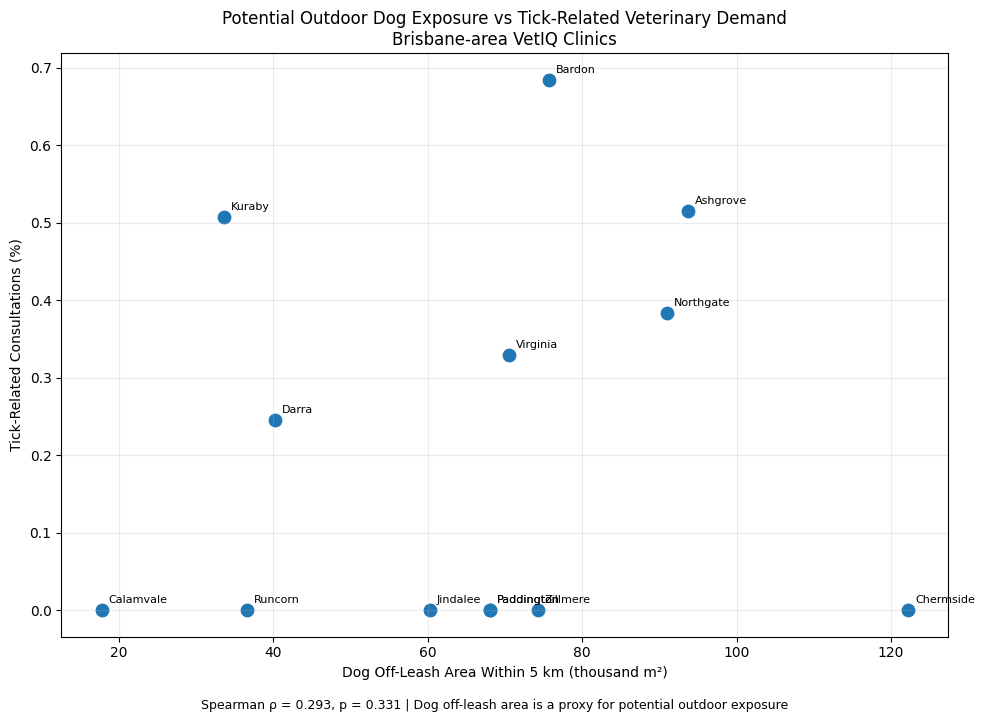

In [36]:
import matplotlib.pyplot as plt

plot_df = dog_tick_analysis.copy()

plt.figure(figsize=(10, 7))

plt.scatter(
    plot_df["Dog_Area_m2_Within_5km"] / 1000,
    plot_df["Tick_Percent"],
    s=80
)

# Add clinic suburb labels
for _, row in plot_df.iterrows():
    plt.annotate(
        row["Suburb"],
        (
            row["Dog_Area_m2_Within_5km"] / 1000,
            row["Tick_Percent"]
        ),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

plt.xlabel("Dog Off-Leash Area Within 5 km (thousand m²)")
plt.ylabel("Tick-Related Consultations (%)")

plt.title(
    "Potential Outdoor Dog Exposure vs Tick-Related Veterinary Demand\n"
    "Brisbane-area VetIQ Clinics"
)

plt.grid(alpha=0.25)

plt.figtext(
    0.5, -0.02,
    "Spearman ρ = 0.293, p = 0.331 | "
    "Dog off-leash area is a proxy for potential outdoor exposure",
    ha="center",
    fontsize=9
)

plt.tight_layout()
plt.show()

In [37]:
import pandas as pd

trails = pd.read_csv("tracksandtrails.csv")

# Extract coordinates
coords = trails["geo_point_2d"].str.split(",", expand=True)

trails["LAT"] = pd.to_numeric(
    coords[0].str.strip(),
    errors="coerce"
)

trails["LONG"] = pd.to_numeric(
    coords[1].str.strip(),
    errors="coerce"
)

trails["Shape__Length"] = pd.to_numeric(
    trails["Shape__Length"],
    errors="coerce"
)

print("Total trail segments:", len(trails))
print("Segments with coordinates:", trails["LAT"].notna().sum())

display(
    trails[
        ["PARK_NAME", "ITEM_TYPE", "Shape__Length", "LAT", "LONG"]
    ].head()
)

Total trail segments: 8989
Segments with coordinates: 8989


,PARK_NAME,ITEM_TYPE,Shape__Length,LAT,LONG
0,REGATTA PARK,PATH,3.481639,-27.482291,152.996858
1,BOYD PARK,PATH,542.552692,-27.400947,153.056902
2,THYNNE ROAD PARK,PATH,11.148640,-27.469048,153.070315
3,THE ESPLANADE PARK (ROAD RESERVE),WALKING TRACK,98.653319,-27.506135,153.000490
4,SOUTH BRISBANE RIVERSIDE LANDS PARK,BIKEWAY,247.780685,-27.471729,153.011021


In [38]:
trail_exposure_results = []

# Only clinics with coordinates
for _, clinic in clinics_geo.dropna(
    subset=["latitude", "longitude"]
).iterrows():

    temp = trails.copy()

    # Distance from clinic to every trail segment
    temp["Distance_km"] = haversine_km(
        clinic["latitude"],
        clinic["longitude"],
        temp["LAT"],
        temp["LONG"]
    )

    # Trails within 5 km
    nearby = temp[temp["Distance_km"] <= 5]

    trail_exposure_results.append({
        "Clinic_ID": clinic["Clinic_ID"],
        "Suburb": clinic["Suburb"],
        "Postcode": clinic["Postcode"],
        "Trail_Segments_5km": len(nearby),
        "Trail_Length_m_5km": nearby["Shape__Length"].sum(),
        "Nearest_Trail_km": temp["Distance_km"].min()
    })

clinic_trail_exposure = pd.DataFrame(trail_exposure_results)

clinic_trail_exposure = clinic_trail_exposure.sort_values(
    "Trail_Length_m_5km",
    ascending=False
).reset_index(drop=True)

print(
    "Clinics with trails within 5 km:",
    (clinic_trail_exposure["Trail_Segments_5km"] > 0).sum()
)

display(clinic_trail_exposure.head(20))

Clinics with trails within 5 km: 17


,Clinic_ID,Suburb,Postcode,Trail_Segments_5km,Trail_Length_m_5km,Nearest_Trail_km
0,Clinic_12,Bardon,4065,1396,186386.858449,0.323603
1,Clinic_13,Ashgrove,4060,1498,172068.359104,0.140069
2,Clinic_26,Paddington,4064,1659,165269.931394,0.167531
3,Clinic_55,Paddington,4064,1659,165269.931394,0.167531
4,Clinic_56,Calamvale,4116,579,153222.289453,0.272834
5,Clinic_62,Camp Hill,4152,936,136433.171144,0.019713
6,Clinic_29,Zillmere,4034,910,135361.289924,0.176495
7,Clinic_48,Chermside,4032,968,122611.321544,0.076687
8,Clinic_45,Runcorn,4113,747,121237.410873,0.102088
9,Clinic_11,Kuraby,4112,625,119060.170443,0.058697


In [39]:
from scipy.stats import spearmanr

# Merge trail exposure with tick consultation rates
trail_tick_analysis = clinic_trail_exposure.merge(
    clinic_tick_rate[
        [
            "ClinicPseudonym",
            "Total_Consultations",
            "Tick_Consultations",
            "Tick_Percent"
        ]
    ],
    left_on="Clinic_ID",
    right_on="ClinicPseudonym",
    how="inner"
)

# Keep clinics with tracks/trails within 5 km
trail_tick_analysis = trail_tick_analysis[
    trail_tick_analysis["Trail_Segments_5km"] > 0
].copy()

# Remove clinics with very few total consultations
trail_tick_analysis = trail_tick_analysis[
    trail_tick_analysis["Total_Consultations"] >= 1000
].copy()

print("Clinics analysed:", len(trail_tick_analysis))

# Correlation: number of trail segments
rho_segments, p_segments = spearmanr(
    trail_tick_analysis["Trail_Segments_5km"],
    trail_tick_analysis["Tick_Percent"]
)

# Correlation: total trail length
rho_length, p_length = spearmanr(
    trail_tick_analysis["Trail_Length_m_5km"],
    trail_tick_analysis["Tick_Percent"]
)

print("\nTrail SEGMENTS vs tick proportion")
print("rho =", round(rho_segments, 3))
print("p   =", round(p_segments, 4))

print("\nTrail LENGTH vs tick proportion")
print("rho =", round(rho_length, 3))
print("p   =", round(p_length, 4))

display(
    trail_tick_analysis[
        [
            "Clinic_ID",
            "Suburb",
            "Trail_Segments_5km",
            "Trail_Length_m_5km",
            "Total_Consultations",
            "Tick_Consultations",
            "Tick_Percent"
        ]
    ].sort_values("Tick_Percent", ascending=False)
)

Clinics analysed: 14

Trail SEGMENTS vs tick proportion
rho = -0.049
p   = 0.8671

Trail LENGTH vs tick proportion
rho = -0.031
p   = 0.9175


,Clinic_ID,Suburb,Trail_Segments_5km,Trail_Length_m_5km,Total_Consultations,Tick_Consultations,Tick_Percent
14,Clinic_04,Redbank Plains,4,264.443204,139251,1890.0,1.357261
0,Clinic_12,Bardon,1396,186386.858449,73749,505.0,0.684755
1,Clinic_13,Ashgrove,1498,172068.359104,142677,735.0,0.515150
8,Clinic_11,Kuraby,625,119060.170443,17143,87.0,0.507496
10,Clinic_59,Northgate,586,94224.537215,61173,235.0,0.384156
9,Clinic_58,Virginia,482,110275.919136,60409,199.0,0.329421
12,Clinic_22,Darra,376,55785.874300,30558,75.0,0.245435
3,Clinic_55,Paddington,1659,165269.931394,49256,0.0,0.000000
4,Clinic_56,Calamvale,579,153222.289453,179358,0.0,0.000000
5,Clinic_29,Zillmere,910,135361.289924,25048,0.0,0.000000


In [40]:
import numpy as np
import pandas as pd

hotspots = clinic_tick_rate.copy()

# Remove clinics with very small consultation volume
hotspots = hotspots[
    hotspots["Total_Consultations"] >= 1000
].copy()

# Tick consultations per 1,000 consultations
hotspots["Tick_per_1000"] = (
    hotspots["Tick_Consultations"]
    / hotspots["Total_Consultations"]
    * 1000
)

# Proportion
p = (
    hotspots["Tick_Consultations"]
    / hotspots["Total_Consultations"]
)

n = hotspots["Total_Consultations"]

# Approximate 95% confidence interval
se = np.sqrt((p * (1 - p)) / n)

hotspots["CI_Lower_per1000"] = np.maximum(
    0,
    (p - 1.96 * se) * 1000
)

hotspots["CI_Upper_per1000"] = (
    (p + 1.96 * se) * 1000
)

hotspots = hotspots.sort_values(
    "Tick_per_1000",
    ascending=False
)

display(
    hotspots[
        [
            "ClinicPseudonym",
            "Suburb",
            "Postcode",
            "Total_Consultations",
            "Tick_Consultations",
            "Tick_per_1000",
            "CI_Lower_per1000",
            "CI_Upper_per1000"
        ]
    ].head(20)
)

,ClinicPseudonym,Suburb,Postcode,Total_Consultations,Tick_Consultations,Tick_per_1000,CI_Lower_per1000,CI_Upper_per1000
52,Clinic_54,Beaudesert,4285,80148,1947.0,24.292559,23.226684,25.358433
2,Clinic_03,Augustine Heights,4300,128718,2278.0,17.697603,16.977298,18.417907
6,Clinic_07,North MacLean,4280,60779,1055.0,17.357969,16.319661,18.396278
18,Clinic_20,North Toowoomba,4350,32547,513.0,15.761821,14.408647,17.114996
1,Clinic_02,Yeppoon,4703,104108,1417.0,13.610866,12.907014,14.314717
3,Clinic_04,Redbank Plains,4301,139251,1890.0,13.572613,12.964869,14.180358
31,Clinic_33,Trinity Beach,4879,273089,2847.0,10.425173,10.044221,10.806124
15,Clinic_17,Flagstone,4280,85425,862.0,10.090723,9.420495,10.760951
4,Clinic_05,Springfield,4300,82519,797.0,9.658382,8.991078,10.325686
12,Clinic_14,Jimboomba,4280,63554,589.0,9.267709,8.522722,10.012697


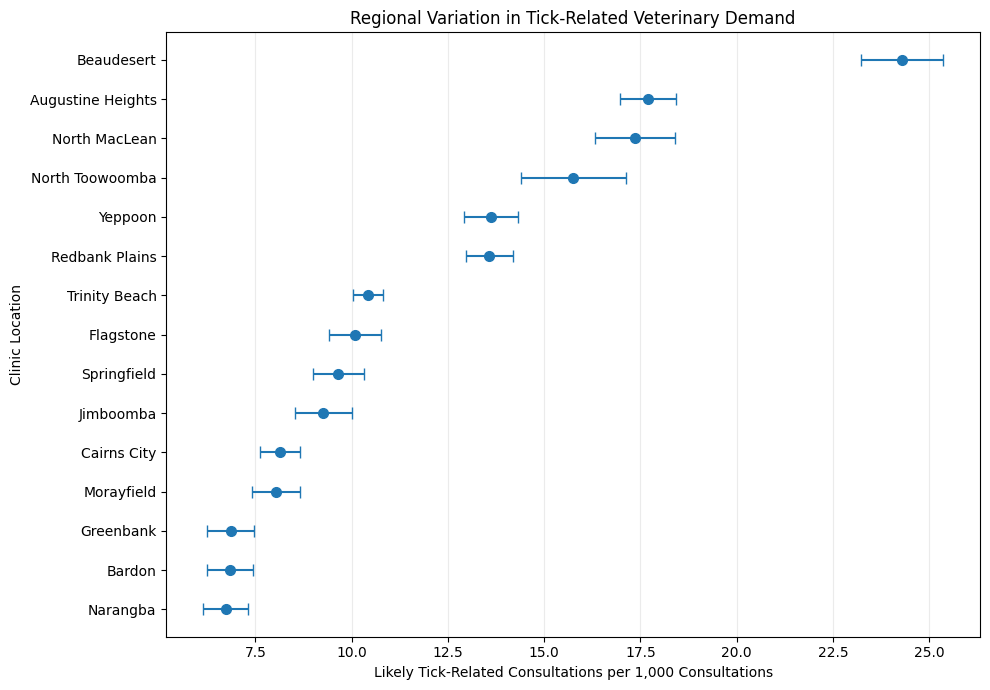

In [41]:
import matplotlib.pyplot as plt

# Top 15 regional hotspots
top = hotspots.head(15).copy()
top = top.sort_values("Tick_per_1000")

# Confidence interval distances
lower_error = (
    top["Tick_per_1000"] -
    top["CI_Lower_per1000"]
)

upper_error = (
    top["CI_Upper_per1000"] -
    top["Tick_per_1000"]
)

plt.figure(figsize=(10, 7))

plt.errorbar(
    top["Tick_per_1000"],
    top["Suburb"],
    xerr=[lower_error, upper_error],
    fmt="o",
    capsize=4,
    markersize=7
)

plt.xlabel(
    "Likely Tick-Related Consultations per 1,000 Consultations"
)

plt.ylabel("Clinic Location")

plt.title(
    "Regional Variation in Tick-Related Veterinary Demand"
)

plt.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.show()

In [42]:
import pandas as pd

# Make sure dates are datetime
consultations["ConsultationDate"] = pd.to_datetime(
    consultations["ConsultationDate"],
    errors="coerce"
)

tick_cases_strict["ConsultationDate"] = pd.to_datetime(
    tick_cases_strict["ConsultationDate"],
    errors="coerce"
)

# Beaudesert clinic from our clinic table
beaudesert_ids = clinics.loc[
    clinics["Suburb"].str.contains("Beaudesert", case=False, na=False),
    "Clinic_ID"
].tolist()

print("Beaudesert clinic ID(s):", beaudesert_ids)

# -----------------------------
# ALL CONSULTATIONS
# -----------------------------
beaudesert_total = consultations[
    consultations["ClinicPseudonym"].isin(beaudesert_ids)
].copy()

beaudesert_total["Week_End"] = (
    beaudesert_total["ConsultationDate"]
    .dt.to_period("W-SUN")
    .dt.end_time
    .dt.normalize()
)

weekly_total = (
    beaudesert_total
    .groupby("Week_End")["ConsultationKey"]
    .nunique()
    .rename("Total_Consultations")
)

# -----------------------------
# LIKELY TICK CONSULTATIONS
# -----------------------------
beaudesert_tick = tick_cases_strict[
    tick_cases_strict["ClinicPseudonym"].isin(beaudesert_ids)
].copy()

beaudesert_tick["Week_End"] = (
    beaudesert_tick["ConsultationDate"]
    .dt.to_period("W-SUN")
    .dt.end_time
    .dt.normalize()
)

weekly_tick = (
    beaudesert_tick
    .groupby("Week_End")["ConsultationKey"]
    .nunique()
    .rename("Tick_Consultations")
)

# -----------------------------
# MERGE
# -----------------------------
beaudesert_weekly = pd.concat(
    [weekly_total, weekly_tick],
    axis=1
).fillna(0).reset_index()

beaudesert_weekly["Tick_per_1000"] = (
    beaudesert_weekly["Tick_Consultations"]
    / beaudesert_weekly["Total_Consultations"]
    * 1000
)

print("\nWeeks:", len(beaudesert_weekly))
print(
    "Period:",
    beaudesert_weekly["Week_End"].min(),
    "to",
    beaudesert_weekly["Week_End"].max()
)

print(
    "Total consultations:",
    int(beaudesert_weekly["Total_Consultations"].sum())
)

print(
    "Likely tick consultations:",
    int(beaudesert_weekly["Tick_Consultations"].sum())
)

display(beaudesert_weekly.head(10))

Beaudesert clinic ID(s): ['Clinic_54']

Weeks: 157
Period: 2023-07-30 00:00:00 to 2026-07-26 00:00:00
Total consultations: 80148
Likely tick consultations: 1947


,Week_End,Total_Consultations,Tick_Consultations,Tick_per_1000
0,2023-07-30,202,4.0,19.801980
1,2023-08-06,443,0.0,0.000000
2,2023-08-13,486,3.0,6.172840
3,2023-08-20,449,15.0,33.407572
4,2023-08-27,438,11.0,25.114155
5,2023-09-03,542,11.0,20.295203
6,2023-09-10,543,0.0,0.000000
7,2023-09-17,488,34.0,69.672131
8,2023-09-24,496,32.0,64.516129
9,2023-10-01,461,12.0,26.030369


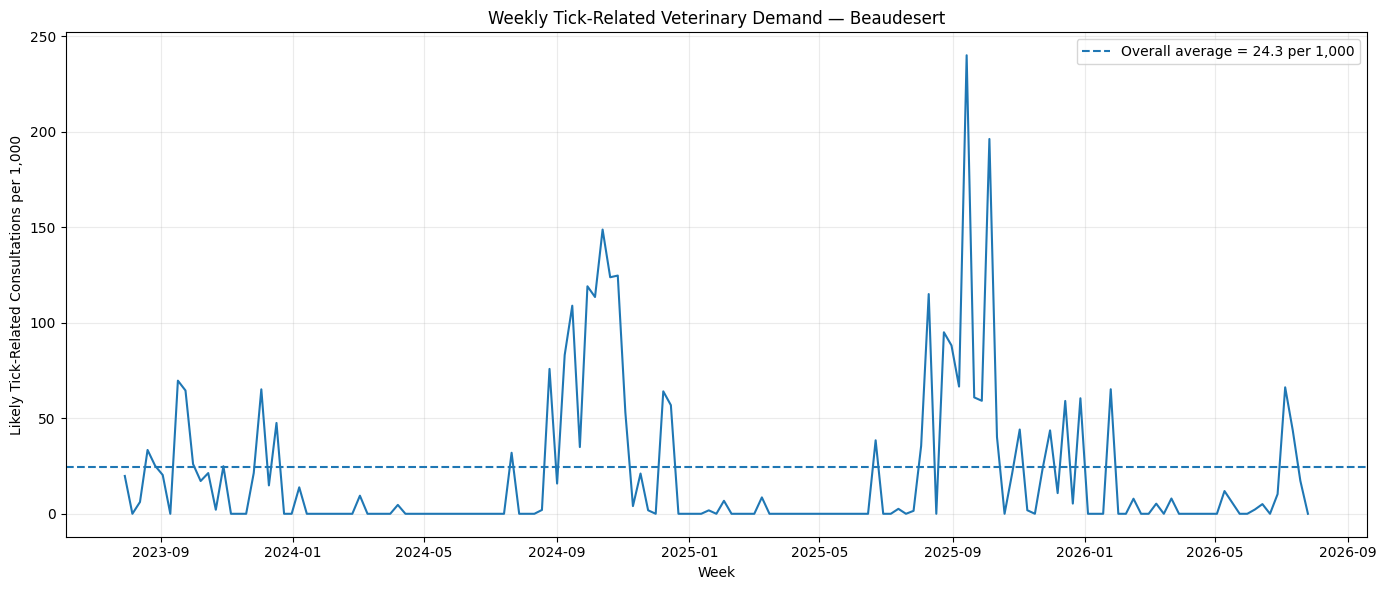

,Week_End,Total_Consultations,Tick_Consultations,Tick_per_1000
111,2025-09-14,596,143.0,239.932886
114,2025-10-05,724,142.0,196.132597
63,2024-10-13,632,94.0,148.734177
65,2024-10-27,730,91.0,124.657534
64,2024-10-20,816,101.0,123.774510
61,2024-09-29,588,70.0,119.047619
106,2025-08-10,661,76.0,114.977307
62,2024-10-06,811,92.0,113.440197
59,2024-09-15,450,49.0,108.888889
108,2025-08-24,558,53.0,94.982079


In [43]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    beaudesert_weekly["Week_End"],
    beaudesert_weekly["Tick_per_1000"],
    linewidth=1.5
)

# Overall average rate
overall_rate = (
    beaudesert_weekly["Tick_Consultations"].sum()
    / beaudesert_weekly["Total_Consultations"].sum()
    * 1000
)

plt.axhline(
    overall_rate,
    linestyle="--",
    label=f"Overall average = {overall_rate:.1f} per 1,000"
)

plt.xlabel("Week")
plt.ylabel("Likely Tick-Related Consultations per 1,000")
plt.title(
    "Weekly Tick-Related Veterinary Demand — Beaudesert"
)

plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

# Show the 15 highest-demand weeks
top_beaudesert_weeks = (
    beaudesert_weekly
    .sort_values("Tick_per_1000", ascending=False)
    .head(15)
)

display(
    top_beaudesert_weeks[
        [
            "Week_End",
            "Total_Consultations",
            "Tick_Consultations",
            "Tick_per_1000"
        ]
    ]
)

In [44]:
# Define unusually high-demand weeks using Beaudesert's own distribution
surge_threshold = beaudesert_weekly["Tick_per_1000"].quantile(0.90)

beaudesert_weekly["Surge"] = (
    beaudesert_weekly["Tick_per_1000"] >= surge_threshold
)

print(
    f"90th percentile surge threshold: "
    f"{surge_threshold:.2f} tick consultations per 1,000"
)

print(
    "Number of surge weeks:",
    beaudesert_weekly["Surge"].sum()
)

display(
    beaudesert_weekly.loc[
        beaudesert_weekly["Surge"],
        [
            "Week_End",
            "Total_Consultations",
            "Tick_Consultations",
            "Tick_per_1000"
        ]
    ].sort_values("Week_End")
)

90th percentile surge threshold: 65.57 tick consultations per 1,000
Number of surge weeks: 16


,Week_End,Total_Consultations,Tick_Consultations,Tick_per_1000
7,2023-09-17,488,34.0,69.672131
56,2024-08-25,699,53.0,75.822604
58,2024-09-08,626,52.0,83.067093
59,2024-09-15,450,49.0,108.888889
61,2024-09-29,588,70.0,119.047619
62,2024-10-06,811,92.0,113.440197
63,2024-10-13,632,94.0,148.734177
64,2024-10-20,816,101.0,123.774510
65,2024-10-27,730,91.0,124.657534
106,2025-08-10,661,76.0,114.977307


In [45]:
beaudesert_geo = clinics_geo[
    clinics_geo["Clinic_ID"] == "Clinic_54"
][
    [
        "Clinic_ID",
        "Suburb",
        "Postcode",
        "latitude",
        "longitude"
    ]
]

display(beaudesert_geo)

,Clinic_ID,Suburb,Postcode,latitude,longitude
53,Clinic_54,Beaudesert,4285,-28.056979,152.975131


In [46]:
import requests
import pandas as pd

# Beaudesert clinic coordinates
lat = -28.056979
lon = 152.975131

url = "https://archive-api.open-meteo.com/v1/archive"

params = {
    "latitude": lat,
    "longitude": lon,
    "start_date": "2023-07-23",
    "end_date": "2026-07-26",
    "daily": [
        "temperature_2m_mean",
        "temperature_2m_max",
        "temperature_2m_min"
    ],
    "timezone": "Australia/Brisbane"
}

response = requests.get(url, params=params)
response.raise_for_status()

data = response.json()

beaudesert_temp = pd.DataFrame({
    "Date": pd.to_datetime(data["daily"]["time"]),
    "AvgTemp_C": data["daily"]["temperature_2m_mean"],
    "MaxTemp_C": data["daily"]["temperature_2m_max"],
    "MinTemp_C": data["daily"]["temperature_2m_min"]
})

print("Rows:", len(beaudesert_temp))
print(
    "Period:",
    beaudesert_temp["Date"].min(),
    "to",
    beaudesert_temp["Date"].max()
)

display(beaudesert_temp.head(10))

Rows: 1100
Period: 2023-07-23 00:00:00 to 2026-07-26 00:00:00


,Date,AvgTemp_C,MaxTemp_C,MinTemp_C
0,2023-07-23,13.1,20.6,5.7
1,2023-07-24,14.5,19.1,11.9
2,2023-07-25,14.4,21.3,10.4
3,2023-07-26,14.1,19.5,9.6
4,2023-07-27,14.7,21.7,10.2
5,2023-07-28,14.0,22.2,6.8
6,2023-07-29,14.3,23.6,7.6
7,2023-07-30,15.2,24.5,7.7
8,2023-07-31,16.7,26.1,10.2
9,2023-08-01,17.8,25.4,12.0


In [47]:
import numpy as np
from sklearn.linear_model import LinearRegression

# --------------------------------
# 1. Daily -> weekly temperature
# --------------------------------
beaudesert_temp["Date"] = pd.to_datetime(beaudesert_temp["Date"])

beaudesert_temp_weekly = (
    beaudesert_temp
    .set_index("Date")
    .resample("W-SUN")
    .agg(
        AvgTemp_C=("AvgTemp_C", "mean"),
        MaxTemp_C=("MaxTemp_C", "max"),
        MinTemp_C=("MinTemp_C", "min")
    )
    .reset_index()
    .rename(columns={"Date": "Week_End"})
)

# --------------------------------
# 2. Annual seasonal terms
# --------------------------------
beaudesert_temp_weekly["Week_of_Year"] = (
    beaudesert_temp_weekly["Week_End"]
    .dt.isocalendar()
    .week
    .astype(int)
)

beaudesert_temp_weekly["Season_Sin"] = np.sin(
    2 * np.pi *
    beaudesert_temp_weekly["Week_of_Year"] / 52
)

beaudesert_temp_weekly["Season_Cos"] = np.cos(
    2 * np.pi *
    beaudesert_temp_weekly["Week_of_Year"] / 52
)

# --------------------------------
# 3. Expected temperature
# --------------------------------
X = beaudesert_temp_weekly[
    ["Season_Sin", "Season_Cos"]
]

y = beaudesert_temp_weekly["AvgTemp_C"]

season_model = LinearRegression()
season_model.fit(X, y)

beaudesert_temp_weekly["Expected_Temp_C"] = (
    season_model.predict(X)
)

# --------------------------------
# 4. Temperature anomaly
# --------------------------------
beaudesert_temp_weekly["Temp_Anomaly_C"] = (
    beaudesert_temp_weekly["AvgTemp_C"]
    - beaudesert_temp_weekly["Expected_Temp_C"]
)

print("Weekly weather rows:", len(beaudesert_temp_weekly))

display(
    beaudesert_temp_weekly[
        [
            "Week_End",
            "AvgTemp_C",
            "Expected_Temp_C",
            "Temp_Anomaly_C"
        ]
    ].head(12)
)

Weekly weather rows: 158


,Week_End,AvgTemp_C,Expected_Temp_C,Temp_Anomaly_C
0,2023-07-23,13.100000,14.510245,-1.410245
1,2023-07-30,14.457143,14.598068,-0.140925
2,2023-08-06,15.928571,14.762621,1.165950
3,2023-08-13,15.485714,15.001504,0.484210
4,2023-08-20,16.085714,15.311234,0.774480
5,2023-08-27,16.642857,15.687294,0.955563
6,2023-09-03,16.628571,16.124201,0.504370
7,2023-09-10,18.128571,16.615583,1.512989
8,2023-09-17,16.000000,17.154275,-1.154275
9,2023-09-24,18.600000,17.732421,0.867579


In [48]:
from scipy.stats import spearmanr

# Merge weekly VetIQ demand with Beaudesert-specific temperature
beaudesert_analysis = beaudesert_weekly.merge(
    beaudesert_temp_weekly[
        [
            "Week_End",
            "AvgTemp_C",
            "Expected_Temp_C",
            "Temp_Anomaly_C"
        ]
    ],
    on="Week_End",
    how="inner"
).sort_values("Week_End").reset_index(drop=True)

# Future tick demand
beaudesert_analysis["Tick_per_1000_1w_ahead"] = (
    beaudesert_analysis["Tick_per_1000"].shift(-1)
)

beaudesert_analysis["Tick_per_1000_2w_ahead"] = (
    beaudesert_analysis["Tick_per_1000"].shift(-2)
)

# Test warmer-than-expected temperature against future demand
results = []

for lead, target in [
    (1, "Tick_per_1000_1w_ahead"),
    (2, "Tick_per_1000_2w_ahead")
]:
    
    temp = beaudesert_analysis[
        ["Temp_Anomaly_C", target]
    ].dropna()
    
    rho, p = spearmanr(
        temp["Temp_Anomaly_C"],
        temp[target]
    )
    
    results.append({
        "Lead_Weeks": lead,
        "Spearman_rho": rho,
        "p_value": p,
        "N": len(temp)
    })

results = pd.DataFrame(results)

print("Matched weeks:", len(beaudesert_analysis))
display(results)

Matched weeks: 157


,Lead_Weeks,Spearman_rho,p_value,N
0,1,0.063904,0.428039,156
1,2,-0.001466,0.985552,155


In [49]:
import requests
import pandas as pd

# Beaudesert / Clinic_54 locality coordinates
lat = -28.056979
lon = 152.975131

url = "https://archive-api.open-meteo.com/v1/archive"

params = {
    "latitude": lat,
    "longitude": lon,
    "start_date": "2023-07-16",   # extra history for lag calculations
    "end_date": "2026-07-26",

    "daily": [
        "temperature_2m_mean",
        "precipitation_sum"
    ],

    "hourly": [
        "relative_humidity_2m"
    ],

    "timezone": "Australia/Brisbane"
}

response = requests.get(url, params=params)
response.raise_for_status()

weather_json = response.json()

# -------------------------------
# Daily temperature + rainfall
# -------------------------------
daily_weather = pd.DataFrame({
    "Date": pd.to_datetime(weather_json["daily"]["time"]),
    "AvgTemp_C": weather_json["daily"]["temperature_2m_mean"],
    "Rainfall_mm": weather_json["daily"]["precipitation_sum"]
})

# -------------------------------
# Hourly humidity -> daily average
# -------------------------------
hourly_weather = pd.DataFrame({
    "DateTime": pd.to_datetime(weather_json["hourly"]["time"]),
    "Humidity_pct": weather_json["hourly"]["relative_humidity_2m"]
})

hourly_weather["Date"] = hourly_weather["DateTime"].dt.normalize()

daily_humidity = (
    hourly_weather
    .groupby("Date", as_index=False)
    .agg(Humidity_pct=("Humidity_pct", "mean"))
)

# Combine
beaudesert_weather = daily_weather.merge(
    daily_humidity,
    on="Date",
    how="left"
)

print("Rows:", len(beaudesert_weather))
print(
    "Period:",
    beaudesert_weather["Date"].min(),
    "to",
    beaudesert_weather["Date"].max()
)

print("\nMissing values:")
print(
    beaudesert_weather[
        ["AvgTemp_C", "Rainfall_mm", "Humidity_pct"]
    ].isna().sum()
)

display(beaudesert_weather.head(10))

Rows: 1107
Period: 2023-07-16 00:00:00 to 2026-07-26 00:00:00

Missing values:
AvgTemp_C       0
Rainfall_mm     0
Humidity_pct    0
dtype: int64


,Date,AvgTemp_C,Rainfall_mm,Humidity_pct
0,2023-07-16,14.4,0.0,68.250000
1,2023-07-17,14.8,0.5,80.625000
2,2023-07-18,15.1,1.7,91.625000
3,2023-07-19,14.8,0.0,72.583333
4,2023-07-20,12.9,0.0,70.000000
5,2023-07-21,13.1,0.0,69.041667
6,2023-07-22,12.4,0.0,63.875000
7,2023-07-23,13.1,0.0,68.333333
8,2023-07-24,14.5,0.0,69.125000
9,2023-07-25,14.4,0.0,67.375000


In [50]:
# ============================================================
# CELL 2 — Weekly weather + VetIQ demand
# ============================================================

# Convert external daily weather to Sunday-ending weeks
beaudesert_weather_weekly = (
    beaudesert_weather
    .set_index("Date")
    .resample("W-SUN")
    .agg(
        AvgTemp_C=("AvgTemp_C", "mean"),
        Rainfall_mm=("Rainfall_mm", "sum"),
        Humidity_pct=("Humidity_pct", "mean")
    )
    .reset_index()
    .rename(columns={"Date": "Week_End"})
)

# Make sure dates match
beaudesert_weather_weekly["Week_End"] = pd.to_datetime(
    beaudesert_weather_weekly["Week_End"]
)

beaudesert_weekly["Week_End"] = pd.to_datetime(
    beaudesert_weekly["Week_End"]
)

# Merge INTERNAL VetIQ + EXTERNAL weather
beaudesert_combined = beaudesert_weekly.merge(
    beaudesert_weather_weekly,
    on="Week_End",
    how="inner"
)

print("Matched weeks:", len(beaudesert_combined))
print(
    "Period:",
    beaudesert_combined["Week_End"].min(),
    "to",
    beaudesert_combined["Week_End"].max()
)

display(
    beaudesert_combined[
        [
            "Week_End",
            "Total_Consultations",
            "Tick_Consultations",
            "Tick_per_1000",
            "AvgTemp_C",
            "Rainfall_mm",
            "Humidity_pct"
        ]
    ].head(10)
)

Matched weeks: 157
Period: 2023-07-30 00:00:00 to 2026-07-26 00:00:00


,Week_End,Total_Consultations,Tick_Consultations,Tick_per_1000,AvgTemp_C,Rainfall_mm,Humidity_pct
0,2023-07-30,202,4.0,19.801980,14.457143,0.2,73.202381
1,2023-08-06,443,0.0,0.000000,15.928571,1.6,77.660714
2,2023-08-13,486,3.0,6.172840,15.485714,0.4,70.339286
3,2023-08-20,449,15.0,33.407572,16.085714,13.8,66.440476
4,2023-08-27,438,11.0,25.114155,16.642857,0.2,71.845238
5,2023-09-03,542,11.0,20.295203,16.628571,32.8,75.654762
6,2023-09-10,543,0.0,0.000000,18.128571,5.2,72.148810
7,2023-09-17,488,34.0,69.672131,16.000000,6.3,72.327381
8,2023-09-24,496,32.0,64.516129,18.600000,1.8,67.845238
9,2023-10-01,461,12.0,26.030369,19.042857,6.8,71.994048


In [51]:
# ============================================================
# CELL 3 — Remove annual seasonality
# ============================================================

import numpy as np
from sklearn.linear_model import LinearRegression

analysis = beaudesert_combined.copy()

# Week of year
analysis["Week_of_Year"] = (
    analysis["Week_End"]
    .dt.isocalendar()
    .week
    .astype(int)
)

# Annual seasonal cycle
analysis["Season_Sin"] = np.sin(
    2 * np.pi * analysis["Week_of_Year"] / 52
)

analysis["Season_Cos"] = np.cos(
    2 * np.pi * analysis["Week_of_Year"] / 52
)

X_season = analysis[["Season_Sin", "Season_Cos"]]

# Variables to seasonally adjust
variables = {
    "Tick_per_1000": "Tick_Anomaly",
    "AvgTemp_C": "Temp_Anomaly",
    "Rainfall_mm": "Rainfall_Anomaly",
    "Humidity_pct": "Humidity_Anomaly"
}

for original, anomaly in variables.items():

    model = LinearRegression()
    model.fit(X_season, analysis[original])

    expected = model.predict(X_season)

    analysis[anomaly] = (
        analysis[original] - expected
    )

print("Seasonality-adjusted weeks:", len(analysis))

display(
    analysis[
        [
            "Week_End",
            "Tick_per_1000",
            "Tick_Anomaly",
            "AvgTemp_C",
            "Temp_Anomaly",
            "Rainfall_mm",
            "Rainfall_Anomaly",
            "Humidity_pct",
            "Humidity_Anomaly"
        ]
    ].head(10)
)

Seasonality-adjusted weeks: 157


,Week_End,Tick_per_1000,Tick_Anomaly,AvgTemp_C,Temp_Anomaly,Rainfall_mm,Rainfall_Anomaly,Humidity_pct,Humidity_Anomaly
0,2023-07-30,19.801980,-13.115829,14.457143,-0.167404,0.2,-6.586724,73.202381,-0.601304
1,2023-08-06,0.000000,-36.049234,15.928571,1.139862,1.6,-5.233996,77.660714,4.143971
2,2023-08-13,6.172840,-32.784279,15.485714,0.458764,0.4,-6.705686,70.339286,-2.913072
3,2023-08-20,33.407572,-8.191488,16.085714,0.749918,13.8,6.202167,66.440476,-6.573905
4,2023-08-27,25.114155,-18.822379,16.642857,0.932113,0.2,-8.103259,71.845238,-0.961049
5,2023-09-03,20.295203,-25.640250,16.628571,0.482246,32.8,23.588322,75.654762,3.023655
6,2023-09-10,0.000000,-47.566669,18.128571,1.492383,5.2,-5.109843,72.148810,-0.342587
7,2023-09-17,69.672131,20.865736,16.000000,-1.173190,6.3,-5.281741,72.327381,-0.061812
8,2023-09-24,64.516129,14.879576,18.600000,0.850499,1.8,-11.208823,67.845238,-4.480749
9,2023-10-01,26.030369,-24.014669,19.042857,0.686142,6.8,-7.770281,71.994048,-0.308652


In [52]:
# ============================================================
# CELL 4 — Weather anomalies vs future VetIQ demand
# ============================================================

from scipy.stats import spearmanr
from statsmodels.stats.multitest import multipletests
import pandas as pd

results = []

weather_variables = {
    "Temperature": "Temp_Anomaly",
    "Rainfall": "Rainfall_Anomaly",
    "Humidity": "Humidity_Anomaly"
}

for weather_name, weather_col in weather_variables.items():

    for lead in [1, 2]:

        # Future seasonality-adjusted VetIQ demand
        future_demand = analysis["Tick_Anomaly"].shift(-lead)

        test_data = pd.DataFrame({
            "Weather": analysis[weather_col],
            "Future_Demand": future_demand
        }).dropna()

        rho, p_value = spearmanr(
            test_data["Weather"],
            test_data["Future_Demand"]
        )

        results.append({
            "Weather_Factor": weather_name,
            "Lead_Weeks": lead,
            "Spearman_rho": rho,
            "Raw_p_value": p_value,
            "N": len(test_data)
        })

weather_results = pd.DataFrame(results)

# ------------------------------------------------------------
# Multiple-testing correction across all 6 tests
# ------------------------------------------------------------

reject, fdr_p, _, _ = multipletests(
    weather_results["Raw_p_value"],
    method="fdr_bh",
    alpha=0.05
)

weather_results["FDR_p_value"] = fdr_p
weather_results["Significant_after_FDR"] = reject

# Round only for display
display_results = weather_results.copy()

display_results["Spearman_rho"] = (
    display_results["Spearman_rho"].round(3)
)

display_results["Raw_p_value"] = (
    display_results["Raw_p_value"].round(4)
)

display_results["FDR_p_value"] = (
    display_results["FDR_p_value"].round(4)
)

display(display_results)

,Weather_Factor,Lead_Weeks,Spearman_rho,Raw_p_value,N,FDR_p_value,Significant_after_FDR
0,Temperature,1,0.050,0.5337,156,0.6373,False
1,Temperature,2,0.047,0.5651,155,0.6373,False
2,Rainfall,1,-0.108,0.1795,156,0.5386,False
3,Rainfall,2,0.051,0.5283,155,0.6373,False
4,Humidity,1,-0.038,0.6373,156,0.6373,False
5,Humidity,2,0.151,0.0605,155,0.3630,False


In [53]:
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

np.random.seed(42)

def block_bootstrap_spearman(x, y, block_size=4, n_boot=2000):
    
    data = pd.DataFrame({
        "x": x,
        "y": y
    }).dropna().reset_index(drop=True)

    n = len(data)
    boot_rhos = []

    for _ in range(n_boot):
        
        indices = []

        while len(indices) < n:
            start = np.random.randint(0, n - block_size + 1)
            indices.extend(
                range(start, start + block_size)
            )

        indices = indices[:n]

        sample = data.iloc[indices]

        rho, _ = spearmanr(
            sample["x"],
            sample["y"]
        )

        if np.isfinite(rho):
            boot_rhos.append(rho)

    lower = np.percentile(boot_rhos, 2.5)
    upper = np.percentile(boot_rhos, 97.5)

    return lower, upper


ci_results = []

weather_variables = {
    "Temperature": "Temp_Anomaly",
    "Rainfall": "Rainfall_Anomaly",
    "Humidity": "Humidity_Anomaly"
}

for weather_name, weather_col in weather_variables.items():

    for lead in [1, 2]:

        future_demand = analysis["Tick_Anomaly"].shift(-lead)

        test = pd.DataFrame({
            "weather": analysis[weather_col],
            "demand": future_demand
        }).dropna()

        rho, raw_p = spearmanr(
            test["weather"],
            test["demand"]
        )

        ci_low, ci_high = block_bootstrap_spearman(
            test["weather"],
            test["demand"],
            block_size=4,
            n_boot=2000
        )

        ci_results.append({
            "Weather": weather_name,
            "Lead_Weeks": lead,
            "Spearman_rho": rho,
            "CI_95_Lower": ci_low,
            "CI_95_Upper": ci_high,
            "Raw_p_value": raw_p,
            "N": len(test)
        })


ci_results = pd.DataFrame(ci_results)

display(
    ci_results.round({
        "Spearman_rho": 3,
        "CI_95_Lower": 3,
        "CI_95_Upper": 3,
        "Raw_p_value": 4
    })
)

,Weather,Lead_Weeks,Spearman_rho,CI_95_Lower,CI_95_Upper,Raw_p_value,N
0,Temperature,1,0.050,-0.155,0.226,0.5337,156
1,Temperature,2,0.047,-0.170,0.237,0.5651,155
2,Rainfall,1,-0.108,-0.257,0.044,0.1795,156
3,Rainfall,2,0.051,-0.108,0.202,0.5283,155
4,Humidity,1,-0.038,-0.213,0.124,0.6373,156
5,Humidity,2,0.151,-0.020,0.311,0.0605,155


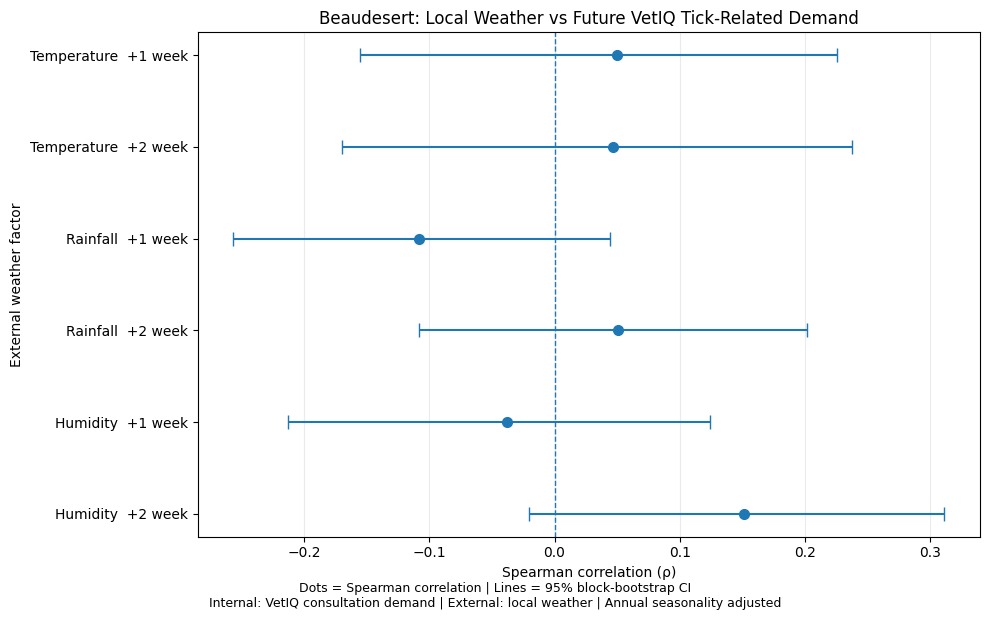

In [54]:
import matplotlib.pyplot as plt
import numpy as np

plot_df = ci_results.copy()

plot_df["Label"] = (
    plot_df["Weather"] +
    "  +" +
    plot_df["Lead_Weeks"].astype(str) +
    " week"
)

# Reverse order for plotting
plot_df = plot_df.iloc[::-1].reset_index(drop=True)

y = np.arange(len(plot_df))

# Distance from rho to CI bounds
lower_error = (
    plot_df["Spearman_rho"] -
    plot_df["CI_95_Lower"]
)

upper_error = (
    plot_df["CI_95_Upper"] -
    plot_df["Spearman_rho"]
)

plt.figure(figsize=(10, 6))

plt.errorbar(
    plot_df["Spearman_rho"],
    y,
    xerr=[lower_error, upper_error],
    fmt="o",
    capsize=5,
    markersize=7
)

# Zero = no association
plt.axvline(
    0,
    linestyle="--",
    linewidth=1
)

plt.yticks(
    y,
    plot_df["Label"]
)

plt.xlabel("Spearman correlation (ρ)")
plt.ylabel("External weather factor")

plt.title(
    "Beaudesert: Local Weather vs Future VetIQ Tick-Related Demand"
)

plt.figtext(
    0.5,
    -0.02,
    "Dots = Spearman correlation | Lines = 95% block-bootstrap CI\n"
    "Internal: VetIQ consultation demand | External: local weather | "
    "Annual seasonality adjusted",
    ha="center",
    fontsize=9
)

plt.grid(
    axis="x",
    alpha=0.25
)

plt.tight_layout()
plt.show()

In [55]:
clinic_locations = (
    clinics[
        [
            "Clinic_ID",
            "Suburb",
            "Postcode",
            "State"
        ]
    ]
    .sort_values(["Postcode", "Suburb"])
    .reset_index(drop=True)
)

display(clinic_locations)

print("Total clinics:", len(clinic_locations))

,Clinic_ID,Suburb,Postcode,State
0,Clinic_59,Northgate,4013,QLD
1,Clinic_58,Virginia,4014,QLD
2,Clinic_48,Chermside,4032,QLD
3,Clinic_29,Zillmere,4034,QLD
4,Clinic_60,Beckett,4053,QLD
...,...,...,...,...
57,Clinic_43,Babinda,4861,QLD
58,Clinic_32,Cairns City,4870,QLD
59,Clinic_35,Stratford,4870,QLD
60,Clinic_33,Trinity Beach,4879,QLD


Total clinics: 62


In [56]:
# Prepare QLD locality -> LGA lookup
qld_lga_lookup = (
    qld_localities[
        [
            "locality_clean",
            "postcode",
            "lgaregion"
        ]
    ]
    .dropna(subset=["locality_clean", "postcode"])
    .drop_duplicates(
        subset=["locality_clean", "postcode"]
    )
)

# Attach LGA to VetIQ clinics
clinics_lga = clinics.merge(
    qld_lga_lookup,
    left_on=["Suburb_clean", "Postcode"],
    right_on=["locality_clean", "postcode"],
    how="left"
)

display(
    clinics_lga[
        [
            "Clinic_ID",
            "Suburb",
            "Postcode",
            "lgaregion"
        ]
    ].sort_values("lgaregion")
)

print("Total clinics:", len(clinics_lga))
print(
    "Clinics with LGA:",
    clinics_lga["lgaregion"].notna().sum()
)

,Clinic_ID,Suburb,Postcode,lgaregion
61,Clinic_62,Camp Hill,4152,Brisbane
49,Clinic_50,Jindalee,4074,Brisbane
28,Clinic_29,Zillmere,4034,Brisbane
54,Clinic_55,Paddington,4064,Brisbane
55,Clinic_56,Calamvale,4116,Brisbane
...,...,...,...,...
60,Clinic_61,East Toowoomba,4350,Toowoomba
19,Clinic_20,North Toowoomba,4350,Toowoomba
7,Clinic_08,Harristown,4350,Toowoomba
37,Clinic_38,Ingham,4850,NaN


Total clinics: 62
Clinics with LGA: 60


In [57]:
# ============================================================
# Identify VetIQ clinics in South-East Queensland
# ============================================================

seq_lgas = [
    "Brisbane",
    "Gold Coast",
    "Ipswich",
    "Lockyer Valley",
    "Logan",
    "Moreton Bay",
    "Noosa",
    "Redland",
    "Scenic Rim",
    "Somerset",
    "Sunshine Coast"
]

seq_clinics = clinics_lga[
    clinics_lga["lgaregion"].isin(seq_lgas)
].copy()

seq_clinics = (
    seq_clinics[
        [
            "Clinic_ID",
            "Suburb",
            "Postcode",
            "lgaregion"
        ]
    ]
    .sort_values(["lgaregion", "Suburb"])
    .reset_index(drop=True)
)

print("SEQ VetIQ clinics:", len(seq_clinics))

print("\nClinics by LGA:")
display(
    seq_clinics.groupby("lgaregion")
    .size()
    .reset_index(name="Clinic_Count")
)

print("\nSEQ clinic list:")
display(seq_clinics)

SEQ VetIQ clinics: 46

Clinics by LGA:


,lgaregion,Clinic_Count
0,Brisbane,15
1,Gold Coast,9
2,Ipswich,7
3,Logan,6
4,Moreton Bay,5
5,Noosa,1
6,Redland,1
7,Scenic Rim,1
8,Sunshine Coast,1



SEQ clinic list:


,Clinic_ID,Suburb,Postcode,lgaregion
0,Clinic_13,Ashgrove,4060,Brisbane
1,Clinic_12,Bardon,4065,Brisbane
2,Clinic_56,Calamvale,4116,Brisbane
3,Clinic_62,Camp Hill,4152,Brisbane
4,Clinic_48,Chermside,4032,Brisbane
5,Clinic_09,Darra,4076,Brisbane
6,Clinic_22,Darra,4076,Brisbane
7,Clinic_50,Jindalee,4074,Brisbane
8,Clinic_11,Kuraby,4112,Brisbane
9,Clinic_59,Northgate,4013,Brisbane


In [59]:
# Add coordinates to the 46 SEQ candidate clinics

seq_clinics_geo = seq_clinics.merge(
    clinics_geo[
        [
            "Clinic_ID",
            "latitude",
            "longitude"
        ]
    ],
    on="Clinic_ID",
    how="left"
)

print("SEQ clinics:", len(seq_clinics_geo))
print(
    "Clinics with coordinates:",
    seq_clinics_geo["latitude"].notna().sum()
)

print(
    "Clinics missing coordinates:",
    seq_clinics_geo["latitude"].isna().sum()
)

display(
    seq_clinics_geo[
        [
            "Clinic_ID",
            "Suburb",
            "Postcode",
            "lgaregion",
            "latitude",
            "longitude"
        ]
    ]
)

SEQ clinics: 46
Clinics with coordinates: 46
Clinics missing coordinates: 0


,Clinic_ID,Suburb,Postcode,lgaregion,latitude,longitude
0,Clinic_13,Ashgrove,4060,Brisbane,-27.445107,152.985176
1,Clinic_12,Bardon,4065,Brisbane,-27.462504,152.975992
2,Clinic_56,Calamvale,4116,Brisbane,-27.633988,153.050793
3,Clinic_62,Camp Hill,4152,Brisbane,-27.501349,153.096812
4,Clinic_48,Chermside,4032,Brisbane,-27.385605,153.019449
5,Clinic_09,Darra,4076,Brisbane,-27.584561,152.921067
6,Clinic_22,Darra,4076,Brisbane,-27.584561,152.921067
7,Clinic_50,Jindalee,4074,Brisbane,-27.554082,152.921521
8,Clinic_11,Kuraby,4112,Brisbane,-27.611129,153.087839
9,Clinic_59,Northgate,4013,Brisbane,-27.397055,153.074982


In [60]:
# ============================================================
# WEEKLY VETIQ DEMAND FOR ALL SEQ CLINICS
# ============================================================

import pandas as pd
import numpy as np

seq_clinic_ids = seq_clinics_geo["Clinic_ID"].tolist()

# Make sure dates are datetime
consultations["ConsultationDate"] = pd.to_datetime(
    consultations["ConsultationDate"],
    errors="coerce"
)

tick_cases_strict["ConsultationDate"] = pd.to_datetime(
    tick_cases_strict["ConsultationDate"],
    errors="coerce"
)

# ------------------------------------------------------------
# 1. ALL consultations in SEQ clinics
# ------------------------------------------------------------

seq_all = consultations[
    consultations["ClinicPseudonym"].isin(seq_clinic_ids)
][
    ["ConsultationKey", "ClinicPseudonym", "ConsultationDate"]
].copy()

seq_all["Week_End"] = (
    seq_all["ConsultationDate"]
    .dt.to_period("W-SUN")
    .dt.end_time
    .dt.normalize()
)

weekly_total = (
    seq_all
    .groupby(["ClinicPseudonym", "Week_End"])
    ["ConsultationKey"]
    .nunique()
    .rename("Total_Consultations")
    .reset_index()
)

# ------------------------------------------------------------
# 2. Likely tick-related consultations
# ------------------------------------------------------------

seq_tick = tick_cases_strict[
    tick_cases_strict["ClinicPseudonym"].isin(seq_clinic_ids)
][
    ["ConsultationKey", "ClinicPseudonym", "ConsultationDate"]
].copy()

seq_tick["Week_End"] = (
    seq_tick["ConsultationDate"]
    .dt.to_period("W-SUN")
    .dt.end_time
    .dt.normalize()
)

weekly_tick = (
    seq_tick
    .groupby(["ClinicPseudonym", "Week_End"])
    ["ConsultationKey"]
    .nunique()
    .rename("Tick_Consultations")
    .reset_index()
)

# ------------------------------------------------------------
# 3. Combine
# ------------------------------------------------------------

seq_weekly = weekly_total.merge(
    weekly_tick,
    on=["ClinicPseudonym", "Week_End"],
    how="left"
)

seq_weekly["Tick_Consultations"] = (
    seq_weekly["Tick_Consultations"]
    .fillna(0)
)

seq_weekly["Tick_per_1000"] = (
    seq_weekly["Tick_Consultations"]
    / seq_weekly["Total_Consultations"]
    * 1000
)

# Add clinic information
seq_weekly = seq_weekly.merge(
    seq_clinics_geo[
        [
            "Clinic_ID",
            "Suburb",
            "lgaregion",
            "latitude",
            "longitude"
        ]
    ],
    left_on="ClinicPseudonym",
    right_on="Clinic_ID",
    how="left"
)

# ------------------------------------------------------------
# 4. Basic checks
# ------------------------------------------------------------

print("Rows (Clinic × Week):", len(seq_weekly))
print(
    "Clinics:",
    seq_weekly["ClinicPseudonym"].nunique()
)

print(
    "Period:",
    seq_weekly["Week_End"].min(),
    "to",
    seq_weekly["Week_End"].max()
)

print(
    "\nTotal consultations:",
    seq_weekly["Total_Consultations"].sum()
)

print(
    "Likely tick-related consultations:",
    int(seq_weekly["Tick_Consultations"].sum())
)

print("\nWeeks available per clinic:")

display(
    seq_weekly
    .groupby(["ClinicPseudonym", "Suburb"])
    .agg(
        Weeks=("Week_End", "nunique"),
        Total_Consultations=("Total_Consultations", "sum"),
        Tick_Consultations=("Tick_Consultations", "sum")
    )
    .reset_index()
    .sort_values(
        "Tick_Consultations",
        ascending=False
    )
)

Rows (Clinic × Week): 5929
Clinics: 44
Period: 2023-07-30 00:00:00 to 2026-08-30 00:00:00

Total consultations: 5039636
Likely tick-related consultations: 17123

Weeks available per clinic:


,ClinicPseudonym,Suburb,Weeks,Total_Consultations,Tick_Consultations
1,Clinic_03,Augustine Heights,157,128718,2278.0
38,Clinic_54,Beaudesert,157,80148,1947.0
2,Clinic_04,Redbank Plains,157,139251,1890.0
5,Clinic_07,North MacLean,157,60779,1055.0
26,Clinic_31,Greenbank,157,152279,862.0
13,Clinic_17,Flagstone,157,85425,862.0
3,Clinic_05,Springfield,157,82519,797.0
9,Clinic_13,Ashgrove,157,142677,735.0
23,Clinic_28,Morayfield,153,79330,637.0
10,Clinic_14,Jimboomba,157,63554,589.0


In [61]:
# ============================================================
# ELIGIBLE SEQ CLINICS FOR REGIONAL TIME-SERIES ANALYSIS
# Rule defined by DATA COVERAGE, not tick outcome
# ============================================================

clinic_coverage = (
    seq_weekly
    .groupby(["ClinicPseudonym", "Suburb"])
    .agg(
        Weeks=("Week_End", "nunique"),
        Total_Consultations=("Total_Consultations", "sum"),
        Tick_Consultations=("Tick_Consultations", "sum")
    )
    .reset_index()
)

# Require at least 100 weeks of consultation history
eligible_clinics = clinic_coverage[
    clinic_coverage["Weeks"] >= 100
].copy()

print("Original SEQ clinics with consultation data:",
      clinic_coverage["ClinicPseudonym"].nunique())

print("Eligible clinics (>=100 weeks):",
      eligible_clinics["ClinicPseudonym"].nunique())

print("Excluded clinics:",
      clinic_coverage["ClinicPseudonym"].nunique()
      - eligible_clinics["ClinicPseudonym"].nunique())

print("\nEligible clinics:")
display(
    eligible_clinics
    .sort_values("Tick_Consultations", ascending=False)
)

print("\nTick extraction check:")
print(
    "Eligible clinics with >=1 likely tick consultation:",
    (eligible_clinics["Tick_Consultations"] > 0).sum()
)

print(
    "Eligible clinics with 0 likely tick consultations:",
    (eligible_clinics["Tick_Consultations"] == 0).sum()
)

Original SEQ clinics with consultation data: 44
Eligible clinics (>=100 weeks): 36
Excluded clinics: 8

Eligible clinics:


,ClinicPseudonym,Suburb,Weeks,Total_Consultations,Tick_Consultations
1,Clinic_03,Augustine Heights,157,128718,2278.0
38,Clinic_54,Beaudesert,157,80148,1947.0
2,Clinic_04,Redbank Plains,157,139251,1890.0
5,Clinic_07,North MacLean,157,60779,1055.0
26,Clinic_31,Greenbank,157,152279,862.0
13,Clinic_17,Flagstone,157,85425,862.0
3,Clinic_05,Springfield,157,82519,797.0
9,Clinic_13,Ashgrove,157,142677,735.0
23,Clinic_28,Morayfield,153,79330,637.0
10,Clinic_14,Jimboomba,157,63554,589.0



Tick extraction check:
Eligible clinics with >=1 likely tick consultation: 22
Eligible clinics with 0 likely tick consultations: 14


In [62]:
# ============================================================
# VALIDATE ZERO-TICK CLINICS
# Compare broad "tick" mentions with strict extraction
# ============================================================

eligible_ids = eligible_clinics["ClinicPseudonym"].tolist()

# Combine the three clinical text fields
text_combined = (
    consultations["ExaminationTextString"].fillna("").astype(str)
    + " "
    + consultations["SummaryString"].fillna("").astype(str)
    + " "
    + consultations["SpecialInstructionString"].fillna("").astype(str)
)

# Broad tick mention
broad_tick_mask = text_combined.str.contains(
    r"\btick(?:s)?\b",
    case=False,
    regex=True
)

broad_tick = consultations.loc[
    broad_tick_mask &
    consultations["ClinicPseudonym"].isin(eligible_ids),
    ["ConsultationKey", "ClinicPseudonym"]
].drop_duplicates("ConsultationKey")

# Count broad mentions per clinic
broad_counts = (
    broad_tick
    .groupby("ClinicPseudonym")
    ["ConsultationKey"]
    .nunique()
    .rename("Broad_Tick_Mentions")
    .reset_index()
)

# Combine with our existing strict counts
validation = eligible_clinics.merge(
    broad_counts,
    on="ClinicPseudonym",
    how="left"
)

validation["Broad_Tick_Mentions"] = (
    validation["Broad_Tick_Mentions"]
    .fillna(0)
    .astype(int)
)

validation["Strict_to_Broad_Percent"] = np.where(
    validation["Broad_Tick_Mentions"] > 0,
    validation["Tick_Consultations"]
    / validation["Broad_Tick_Mentions"]
    * 100,
    np.nan
)

# Focus especially on clinics where strict extraction = 0
zero_strict = validation[
    validation["Tick_Consultations"] == 0
].copy()

print("Eligible clinics:", len(validation))

print(
    "Strict-zero clinics:",
    len(zero_strict)
)

print(
    "Strict-zero clinics that still have broad tick mentions:",
    (zero_strict["Broad_Tick_Mentions"] > 0).sum()
)

print("\nZERO STRICT-TICK CLINICS:")
display(
    zero_strict[
        [
            "ClinicPseudonym",
            "Suburb",
            "Weeks",
            "Total_Consultations",
            "Broad_Tick_Mentions",
            "Tick_Consultations"
        ]
    ].sort_values(
        "Broad_Tick_Mentions",
        ascending=False
    )
)

print("\nALL ELIGIBLE CLINICS:")
display(
    validation[
        [
            "ClinicPseudonym",
            "Suburb",
            "Broad_Tick_Mentions",
            "Tick_Consultations",
            "Strict_to_Broad_Percent"
        ]
    ].sort_values(
        "Broad_Tick_Mentions",
        ascending=False
    )
)

Eligible clinics: 36
Strict-zero clinics: 14
Strict-zero clinics that still have broad tick mentions: 0

ZERO STRICT-TICK CLINICS:


,ClinicPseudonym,Suburb,Weeks,Total_Consultations,Broad_Tick_Mentions,Tick_Consultations
14,Clinic_24,Bundamba,140,28956,0,0.0
17,Clinic_29,Zillmere,141,25048,0,0.0
20,Clinic_37,Coomera,156,104370,0,0.0
21,Clinic_44,Varsity Lakes,156,228208,0,0.0
22,Clinic_45,Runcorn,157,506198,0,0.0
23,Clinic_46,Morayfield,157,111921,0,0.0
25,Clinic_48,Chermside,148,280862,0,0.0
26,Clinic_49,Buderim,149,271745,0,0.0
27,Clinic_50,Jindalee,149,349613,0,0.0
28,Clinic_51,Carrara,147,222567,0,0.0



ALL ELIGIBLE CLINICS:


,ClinicPseudonym,Suburb,Broad_Tick_Mentions,Tick_Consultations,Strict_to_Broad_Percent
10,Clinic_16,Helensvale,63845,473.0,0.740857
30,Clinic_54,Beaudesert,39467,1947.0,4.933235
4,Clinic_06,Greenbank,33877,479.0,1.413939
13,Clinic_19,Lawnton,27051,535.0,1.977746
11,Clinic_17,Flagstone,26992,862.0,3.193539
8,Clinic_14,Jimboomba,25592,589.0,2.301500
5,Clinic_07,North MacLean,24786,1055.0,4.256435
12,Clinic_18,Loganholme,20071,477.0,2.376563
9,Clinic_15,Miami,20017,450.0,2.248089
6,Clinic_12,Bardon,18261,505.0,2.765456


In [63]:
# ============================================================
# FINAL ANALYTICAL COHORT FOR SEQ WEATHER ANALYSIS
# ============================================================

analysis_clinics = validation[
    (validation["Weeks"] >= 100) &
    (validation["Broad_Tick_Mentions"] > 0)
].copy()

analysis_clinic_ids = analysis_clinics[
    "ClinicPseudonym"
].tolist()

# Attach coordinates / region information
analysis_clinics_geo = analysis_clinics.merge(
    seq_clinics_geo[
        [
            "Clinic_ID",
            "lgaregion",
            "latitude",
            "longitude"
        ]
    ],
    left_on="ClinicPseudonym",
    right_on="Clinic_ID",
    how="left"
)

print(
    "Clinics in final analytical cohort:",
    len(analysis_clinics_geo)
)

print(
    "Unique clinic locations:",
    analysis_clinics_geo[
        ["latitude", "longitude"]
    ].drop_duplicates().shape[0]
)

print("\nClinics by LGA:")
display(
    analysis_clinics_geo
    .groupby("lgaregion")
    .size()
    .reset_index(name="Clinic_Count")
)

print("\nFinal clinic cohort:")
display(
    analysis_clinics_geo[
        [
            "ClinicPseudonym",
            "Suburb",
            "lgaregion",
            "Weeks",
            "Total_Consultations",
            "Tick_Consultations",
            "latitude",
            "longitude"
        ]
    ].sort_values(
        ["lgaregion", "Suburb"]
    )
)

Clinics in final analytical cohort: 22
Unique clinic locations: 19

Clinics by LGA:


,lgaregion,Clinic_Count
0,Brisbane,4
1,Gold Coast,2
2,Ipswich,5
3,Logan,5
4,Moreton Bay,4
5,Noosa,1
6,Redland,1



Final clinic cohort:


,ClinicPseudonym,Suburb,lgaregion,Weeks,Total_Consultations,Tick_Consultations,latitude,longitude
7,Clinic_13,Ashgrove,Brisbane,157,142677,735.0,-27.445107,152.985176
6,Clinic_12,Bardon,Brisbane,157,73749,505.0,-27.462504,152.975992
21,Clinic_59,Northgate,Brisbane,156,61173,235.0,-27.397055,153.074982
20,Clinic_58,Virginia,Brisbane,156,60409,199.0,-27.373947,153.084784
10,Clinic_16,Helensvale,Gold Coast,157,187697,473.0,-27.869823,153.360694
9,Clinic_15,Miami,Gold Coast,157,100295,450.0,-28.084952,153.434406
1,Clinic_03,Augustine Heights,Ipswich,157,128718,2278.0,-27.682273,152.884999
4,Clinic_06,Greenbank,Ipswich,157,69863,479.0,-27.701681,152.967761
17,Clinic_31,Greenbank,Ipswich,157,152279,862.0,-27.701681,152.967761
2,Clinic_04,Redbank Plains,Ipswich,157,139251,1890.0,-27.629394,152.858086


In [64]:
import pandas as pd
import requests
import time

# ============================================================
# UNIQUE WEATHER LOCATIONS
# ============================================================

weather_locations = (
    analysis_clinics_geo[
        ["latitude", "longitude"]
    ]
    .drop_duplicates()
    .reset_index(drop=True)
)

print("Unique weather locations:", len(weather_locations))

# ============================================================
# DOWNLOAD OPEN-METEO HISTORICAL WEATHER
# ============================================================

all_weather = []

for i, row in weather_locations.iterrows():

    lat = row["latitude"]
    lon = row["longitude"]

    print(
        f"Downloading {i+1}/{len(weather_locations)} "
        f"({lat:.4f}, {lon:.4f})"
    )

    url = "https://archive-api.open-meteo.com/v1/archive"

    params = {
        "latitude": lat,
        "longitude": lon,
        "start_date": "2023-07-16",
        "end_date": "2026-07-26",

        # Daily temperature + rainfall
        "daily": [
            "temperature_2m_mean",
            "precipitation_sum"
        ],

        # Hourly humidity
        "hourly": [
            "relative_humidity_2m"
        ],

        "timezone": "Australia/Brisbane"
    }

    response = requests.get(
        url,
        params=params,
        timeout=60
    )

    response.raise_for_status()

    data = response.json()

    # ----------------------------
    # DAILY DATA
    # ----------------------------

    daily = pd.DataFrame({
        "Date": pd.to_datetime(data["daily"]["time"]),

        "AvgTemp_C":
            data["daily"]["temperature_2m_mean"],

        "Rainfall_mm":
            data["daily"]["precipitation_sum"]
    })

    # ----------------------------
    # HOURLY HUMIDITY
    # ----------------------------

    hourly = pd.DataFrame({
        "time":
            pd.to_datetime(data["hourly"]["time"]),

        "Humidity_pct":
            data["hourly"]["relative_humidity_2m"]
    })

    hourly["Date"] = hourly["time"].dt.normalize()

    daily_humidity = (
        hourly
        .groupby("Date")
        ["Humidity_pct"]
        .mean()
        .reset_index()
    )

    # ----------------------------
    # COMBINE
    # ----------------------------

    location_weather = daily.merge(
        daily_humidity,
        on="Date",
        how="left"
    )

    location_weather["latitude"] = lat
    location_weather["longitude"] = lon

    all_weather.append(location_weather)

    # Small pause between requests
    time.sleep(0.3)

# ============================================================
# COMBINE ALL LOCATIONS
# ============================================================

seq_local_weather = pd.concat(
    all_weather,
    ignore_index=True
)

print("\nDONE")

print(
    "Unique locations downloaded:",
    seq_local_weather[
        ["latitude", "longitude"]
    ].drop_duplicates().shape[0]
)

print(
    "Rows:",
    len(seq_local_weather)
)

print(
    "Period:",
    seq_local_weather["Date"].min(),
    "to",
    seq_local_weather["Date"].max()
)

print("\nMissing values:")
print(
    seq_local_weather[
        [
            "AvgTemp_C",
            "Rainfall_mm",
            "Humidity_pct"
        ]
    ].isna().sum()
)

display(seq_local_weather.head())

Unique weather locations: 19

DONE
Unique locations downloaded: 19
Rows: 21033
Period: 2023-07-16 00:00:00 to 2026-07-26 00:00:00

Missing values:
AvgTemp_C       0
Rainfall_mm     0
Humidity_pct    0
dtype: int64


,Date,AvgTemp_C,Rainfall_mm,Humidity_pct,latitude,longitude
0,2023-07-16,16.5,0.0,69.791667,-27.181203,153.013716
1,2023-07-17,15.9,4.6,84.541667,-27.181203,153.013716
2,2023-07-18,16.5,1.9,87.916667,-27.181203,153.013716
3,2023-07-19,16.8,0.0,72.708333,-27.181203,153.013716
4,2023-07-20,14.9,0.0,70.583333,-27.181203,153.013716


In [65]:
# ============================================================
# CREATE WEEKLY LOCAL WEATHER + MERGE WITH EACH SEQ CLINIC
# ============================================================

import pandas as pd

# Make sure Date is datetime
seq_local_weather["Date"] = pd.to_datetime(
    seq_local_weather["Date"]
)

# ------------------------------------------------------------
# 1. Convert daily local weather -> weekly local weather
# ------------------------------------------------------------

weekly_weather_list = []

for (lat, lon), group in seq_local_weather.groupby(
    ["latitude", "longitude"]
):

    group = group.copy().set_index("Date")

    weekly = (
        group
        .resample("W-SUN")
        .agg(
            AvgTemp_C=("AvgTemp_C", "mean"),
            Rainfall_mm=("Rainfall_mm", "sum"),
            Humidity_pct=("Humidity_pct", "mean")
        )
        .reset_index()
        .rename(columns={"Date": "Week_End"})
    )

    weekly["latitude"] = lat
    weekly["longitude"] = lon

    weekly_weather_list.append(weekly)

seq_weekly_weather = pd.concat(
    weekly_weather_list,
    ignore_index=True
)

# ------------------------------------------------------------
# 2. Keep only the 22 eligible analysis clinics
# ------------------------------------------------------------

regional_panel = seq_weekly[
    seq_weekly["ClinicPseudonym"].isin(
        analysis_clinic_ids
    )
].copy()

# ------------------------------------------------------------
# 3. Merge local weather using clinic coordinates + week
# ------------------------------------------------------------

regional_panel = regional_panel.merge(
    seq_weekly_weather,
    on=[
        "latitude",
        "longitude",
        "Week_End"
    ],
    how="left"
)

# ------------------------------------------------------------
# 4. Basic checks
# ------------------------------------------------------------

print("Clinic × Week rows:", len(regional_panel))

print(
    "Clinics:",
    regional_panel["ClinicPseudonym"].nunique()
)

print(
    "Unique weather locations:",
    regional_panel[
        ["latitude", "longitude"]
    ].drop_duplicates().shape[0]
)

print(
    "Period:",
    regional_panel["Week_End"].min(),
    "to",
    regional_panel["Week_End"].max()
)

print("\nMissing matched weather:")
print(
    regional_panel[
        [
            "AvgTemp_C",
            "Rainfall_mm",
            "Humidity_pct"
        ]
    ].isna().sum()
)

print("\nExample:")
display(
    regional_panel[
        [
            "ClinicPseudonym",
            "Suburb",
            "Week_End",
            "Total_Consultations",
            "Tick_Consultations",
            "Tick_per_1000",
            "AvgTemp_C",
            "Rainfall_mm",
            "Humidity_pct"
        ]
    ].head(15)
)

Clinic × Week rows: 3444
Clinics: 22
Unique weather locations: 19
Period: 2023-07-30 00:00:00 to 2026-07-26 00:00:00

Missing matched weather:
AvgTemp_C       0
Rainfall_mm     0
Humidity_pct    0
dtype: int64

Example:


,ClinicPseudonym,Suburb,Week_End,Total_Consultations,Tick_Consultations,Tick_per_1000,AvgTemp_C,Rainfall_mm,Humidity_pct
0,Clinic_01,Deception Bay,2023-07-30,290,2.0,6.896552,16.571429,0.2,69.404762
1,Clinic_01,Deception Bay,2023-08-06,763,0.0,0.000000,17.471429,6.8,76.678571
2,Clinic_01,Deception Bay,2023-08-13,703,3.0,4.267425,16.928571,1.3,68.660714
3,Clinic_01,Deception Bay,2023-08-20,629,3.0,4.769475,18.128571,0.9,59.892857
4,Clinic_01,Deception Bay,2023-08-27,610,0.0,0.000000,17.885714,1.2,72.684524
5,Clinic_01,Deception Bay,2023-09-03,719,2.0,2.781641,17.800000,9.9,77.130952
6,Clinic_01,Deception Bay,2023-09-10,786,1.0,1.272265,19.514286,25.9,71.547619
7,Clinic_01,Deception Bay,2023-09-17,780,0.0,0.000000,17.885714,3.0,67.279762
8,Clinic_01,Deception Bay,2023-09-24,671,5.0,7.451565,19.471429,2.1,68.273810
9,Clinic_01,Deception Bay,2023-10-01,952,3.0,3.151261,19.428571,13.7,71.702381


In [66]:
# ============================================================
# REMOVE ANNUAL SEASONALITY WITHIN EACH CLINIC
# ============================================================

import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression

regional_adjusted_list = []

for clinic_id, clinic_df in regional_panel.groupby("ClinicPseudonym"):

    clinic_df = clinic_df.copy().sort_values("Week_End")

    # Week of year
    clinic_df["Week_of_Year"] = (
        clinic_df["Week_End"]
        .dt.isocalendar()
        .week
        .astype(int)
    )

    # Annual seasonal cycle
    clinic_df["Season_Sin"] = np.sin(
        2 * np.pi * clinic_df["Week_of_Year"] / 52
    )

    clinic_df["Season_Cos"] = np.cos(
        2 * np.pi * clinic_df["Week_of_Year"] / 52
    )

    X = clinic_df[["Season_Sin", "Season_Cos"]]

    # --------------------------------------------------------
    # Remove seasonality separately from demand + weather
    # --------------------------------------------------------

    variables = {
        "Tick_per_1000": "Tick_Anomaly",
        "AvgTemp_C": "Temp_Anomaly",
        "Rainfall_mm": "Rainfall_Anomaly",
        "Humidity_pct": "Humidity_Anomaly"
    }

    for original, residual_name in variables.items():

        model = LinearRegression()

        model.fit(
            X,
            clinic_df[original]
        )

        expected = model.predict(X)

        clinic_df[residual_name] = (
            clinic_df[original] - expected
        )

    regional_adjusted_list.append(clinic_df)


regional_adjusted = pd.concat(
    regional_adjusted_list,
    ignore_index=True
)

# ============================================================
# CHECK
# ============================================================

print("Rows:", len(regional_adjusted))

print(
    "Clinics:",
    regional_adjusted["ClinicPseudonym"].nunique()
)

print("\nAnomaly averages (should be very close to zero):")

print(
    regional_adjusted[
        [
            "Tick_Anomaly",
            "Temp_Anomaly",
            "Rainfall_Anomaly",
            "Humidity_Anomaly"
        ]
    ].mean().round(6)
)

print("\nExample:")
display(
    regional_adjusted[
        [
            "ClinicPseudonym",
            "Suburb",
            "Week_End",
            "Tick_per_1000",
            "Tick_Anomaly",
            "AvgTemp_C",
            "Temp_Anomaly",
            "Rainfall_Anomaly",
            "Humidity_Anomaly"
        ]
    ].head(10)
)

Rows: 3444
Clinics: 22

Anomaly averages (should be very close to zero):
Tick_Anomaly        0.0
Temp_Anomaly        0.0
Rainfall_Anomaly   -0.0
Humidity_Anomaly   -0.0
dtype: float64

Example:


,ClinicPseudonym,Suburb,Week_End,Tick_per_1000,Tick_Anomaly,AvgTemp_C,Temp_Anomaly,Rainfall_Anomaly,Humidity_Anomaly
0,Clinic_01,Deception Bay,2023-07-30,6.896552,4.279773,16.571429,0.264514,-6.319237,-2.227047
1,Clinic_01,Deception Bay,2023-08-06,0.000000,-2.937212,17.471429,1.041016,0.563073,5.231324
2,Clinic_01,Deception Bay,2023-08-13,4.267425,1.012125,16.928571,0.308370,-4.985729,-2.649433
3,Clinic_01,Deception Bay,2023-08-20,4.769475,1.203068,18.128571,1.255057,-5.764933,-11.329651
4,Clinic_01,Deception Bay,2023-08-27,0.000000,-3.865996,17.885714,0.699057,-6.169007,1.498915
5,Clinic_01,Deception Bay,2023-09-03,2.781641,-1.368056,17.800000,0.244937,1.512314,5.930966
6,Clinic_01,Deception Bay,2023-09-10,1.272265,-3.141110,19.514286,1.540926,16.193886,0.282187
7,Clinic_01,Deception Bay,2023-09-17,0.000000,-4.653182,17.885714,-0.549733,-8.305066,-4.101229
8,Clinic_01,Deception Bay,2023-09-24,7.451565,2.585941,19.471429,0.536840,-11.061226,-3.271169
9,Clinic_01,Deception Bay,2023-10-01,3.151261,-1.896341,19.428571,-0.034933,-1.547527,-0.052622


In [67]:
# ============================================================
# REGIONAL SEQ TEMPERATURE -> FUTURE TICK DEMAND
# +1 week and +2 weeks
# ============================================================

import pandas as pd
from scipy.stats import spearmanr

regional_test = (
    regional_adjusted
    .sort_values(["ClinicPseudonym", "Week_End"])
    .copy()
)

# Future demand WITHIN each clinic
regional_test["Tick_Anomaly_1w_Ahead"] = (
    regional_test
    .groupby("ClinicPseudonym")["Tick_Anomaly"]
    .shift(-1)
)

regional_test["Tick_Anomaly_2w_Ahead"] = (
    regional_test
    .groupby("ClinicPseudonym")["Tick_Anomaly"]
    .shift(-2)
)

results = []

for lead, target in [
    (1, "Tick_Anomaly_1w_Ahead"),
    (2, "Tick_Anomaly_2w_Ahead")
]:

    test = regional_test[
        [
            "Temp_Anomaly",
            target
        ]
    ].dropna()

    rho, p = spearmanr(
        test["Temp_Anomaly"],
        test[target]
    )

    results.append({
        "Lead_Weeks": lead,
        "Spearman_rho": rho,
        "Raw_p_value": p,
        "N_ClinicWeeks": len(test)
    })

regional_temperature_results = pd.DataFrame(results)

display(
    regional_temperature_results.round({
        "Spearman_rho": 3,
        "Raw_p_value": 5
    })
)

print(
    "Clinics represented:",
    regional_test["ClinicPseudonym"].nunique()
)

,Lead_Weeks,Spearman_rho,Raw_p_value,N_ClinicWeeks
0,1,0.073,0.00002,3422
1,2,0.058,0.00076,3400


Clinics represented: 22


In [68]:
# ============================================================
# TEMPERATURE EFFECT BY INDIVIDUAL SEQ CLINIC
# ============================================================

from scipy.stats import spearmanr
import pandas as pd

clinic_results = []

for clinic_id, g in regional_test.groupby("ClinicPseudonym"):

    g = g.sort_values("Week_End").copy()

    suburb = g["Suburb"].iloc[0]
    region = g["lgaregion"].iloc[0]

    for lead, target in [
        (1, "Tick_Anomaly_1w_Ahead"),
        (2, "Tick_Anomaly_2w_Ahead")
    ]:

        test = g[
            ["Temp_Anomaly", target]
        ].dropna()

        rho, p = spearmanr(
            test["Temp_Anomaly"],
            test[target]
        )

        clinic_results.append({
            "Clinic": clinic_id,
            "Suburb": suburb,
            "Region": region,
            "Lead_Weeks": lead,
            "Spearman_rho": rho,
            "Raw_p_value": p,
            "N": len(test)
        })

clinic_temperature_results = pd.DataFrame(
    clinic_results
)

# Show results
display(
    clinic_temperature_results
    .sort_values(
        ["Lead_Weeks", "Spearman_rho"],
        ascending=[True, False]
    )
    .round({
        "Spearman_rho": 3,
        "Raw_p_value": 4
    })
)

# Direction consistency
direction_summary = (
    clinic_temperature_results
    .groupby("Lead_Weeks")
    .agg(
        Clinics=("Clinic", "count"),
        Positive_Rho=(
            "Spearman_rho",
            lambda x: (x > 0).sum()
        ),
        Negative_Rho=(
            "Spearman_rho",
            lambda x: (x < 0).sum()
        ),
        Median_Rho=("Spearman_rho", "median")
    )
    .reset_index()
)

print("\nDIRECTION CONSISTENCY:")
display(direction_summary.round(3))

,Clinic,Suburb,Region,Lead_Weeks,Spearman_rho,Raw_p_value,N
10,Clinic_07,North MacLean,Logan,1,0.276,0.0005,156
36,Clinic_47,Coolum Beach,Noosa,1,0.205,0.0102,156
24,Clinic_18,Loganholme,Logan,1,0.183,0.0219,156
34,Clinic_31,Greenbank,Ipswich,1,0.169,0.0353,156
22,Clinic_17,Flagstone,Logan,1,0.137,0.0871,156
42,Clinic_59,Northgate,Brisbane,1,0.119,0.1419,155
14,Clinic_13,Ashgrove,Brisbane,1,0.103,0.1986,156
16,Clinic_14,Jimboomba,Logan,1,0.101,0.2076,156
32,Clinic_30,Wynnum,Redland,1,0.091,0.2604,156
12,Clinic_12,Bardon,Brisbane,1,0.071,0.3806,156



DIRECTION CONSISTENCY:


,Lead_Weeks,Clinics,Positive_Rho,Negative_Rho,Median_Rho
0,1,22,18,4,0.053
1,2,22,18,4,0.037


In [69]:
from scipy.stats import binomtest
import pandas as pd

sign_results = []

for lead in [1, 2]:

    temp = clinic_temperature_results[
        clinic_temperature_results["Lead_Weeks"] == lead
    ].dropna(subset=["Spearman_rho"])

    positive = (temp["Spearman_rho"] > 0).sum()
    negative = (temp["Spearman_rho"] < 0).sum()

    test = binomtest(
        k=positive,
        n=positive + negative,
        p=0.5,
        alternative="two-sided"
    )

    sign_results.append({
        "Lead_Weeks": lead,
        "Positive_Clinics": positive,
        "Negative_Clinics": negative,
        "Positive_Percent": positive / (positive + negative) * 100,
        "Sign_Test_p": test.pvalue
    })

sign_results = pd.DataFrame(sign_results)

display(
    sign_results.round({
        "Positive_Percent": 1,
        "Sign_Test_p": 4
    })
)

,Lead_Weeks,Positive_Clinics,Negative_Clinics,Positive_Percent,Sign_Test_p
0,1,18,4,81.8,0.0043
1,2,18,4,81.8,0.0043


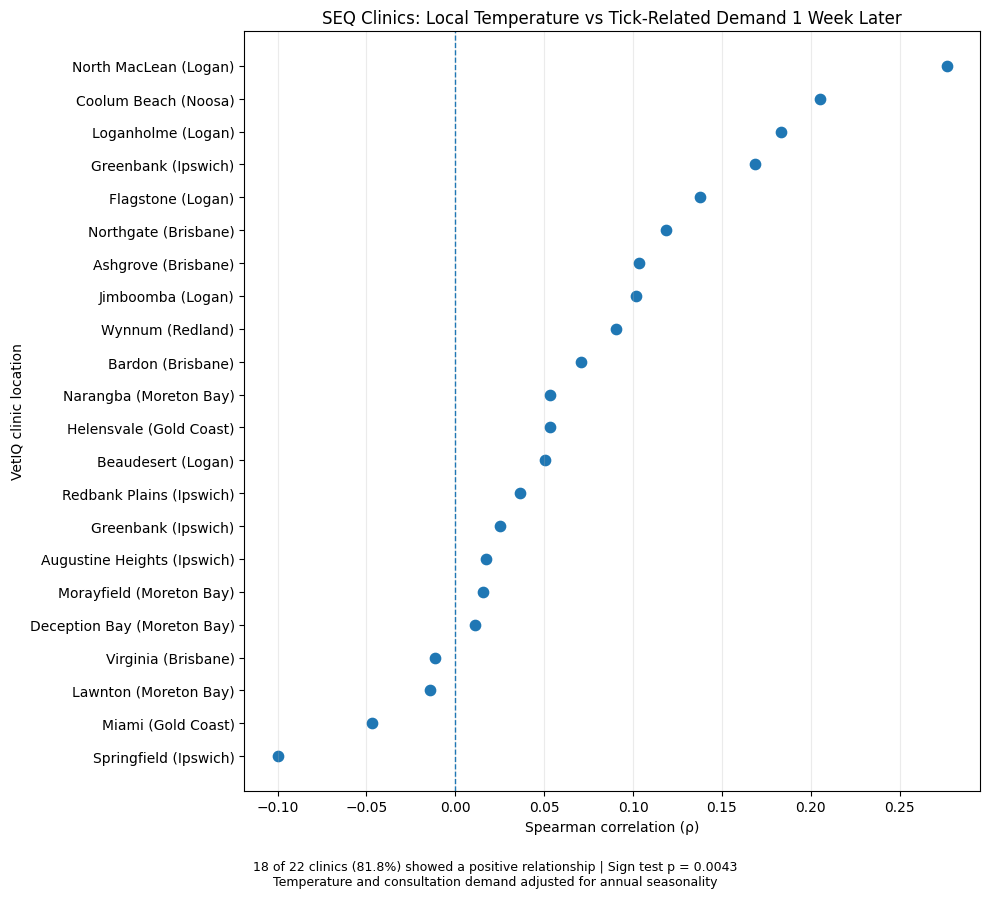

In [71]:
import matplotlib.pyplot as plt
import numpy as np

plot_df = (
    clinic_temperature_results[
        clinic_temperature_results["Lead_Weeks"] == 1
    ]
    .copy()
    .sort_values("Spearman_rho")
)

plot_df["Label"] = (
    plot_df["Suburb"] +
    " (" +
    plot_df["Region"] +
    ")"
)

y = np.arange(len(plot_df))

plt.figure(figsize=(10, 9))

plt.scatter(
    plot_df["Spearman_rho"],
    y,
    s=55
)

plt.axvline(
    0,
    linestyle="--",
    linewidth=1
)

plt.yticks(
    y,
    plot_df["Label"]
)

plt.xlabel(
    "Spearman correlation (ρ)"
)

plt.ylabel(
    "VetIQ clinic location"
)

plt.title(
    "SEQ Clinics: Local Temperature vs Tick-Related Demand 1 Week Later"
)

plt.figtext(
    0.5,
    0.01,
    "18 of 22 clinics (81.8%) showed a positive relationship | "
    "Sign test p = 0.0043\n"
    "Temperature and consultation demand adjusted for annual seasonality",
    ha="center",
    fontsize=9
)

plt.grid(
    axis="x",
    alpha=0.25
)

plt.tight_layout(rect=[0, 0.05, 1, 1])

plt.show()

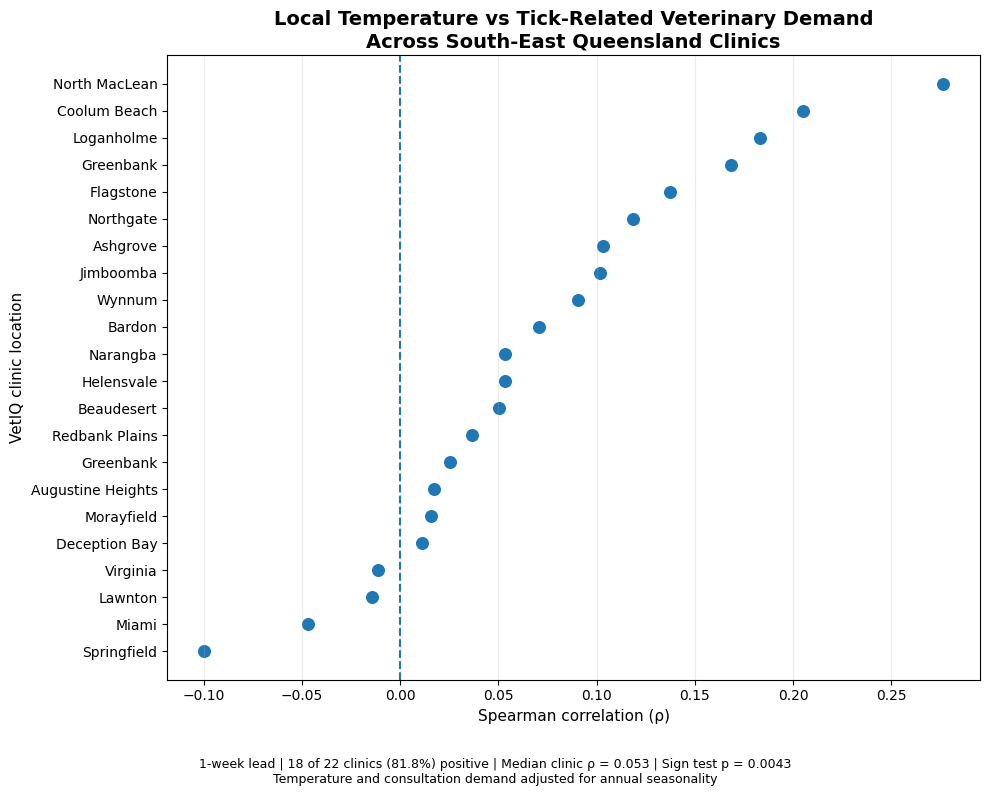

In [72]:

# Temperature anomaly -> Tick demand 1 week later
# ============================================================

import matplotlib.pyplot as plt
import numpy as np

# Keep 1-week results
plot_df = (
    clinic_temperature_results[
        clinic_temperature_results["Lead_Weeks"] == 1
    ]
    .copy()
    .sort_values("Spearman_rho")
)

# Label = suburb only (cleaner for presentation)
plot_df["Label"] = plot_df["Suburb"]

y = np.arange(len(plot_df))

plt.figure(figsize=(10, 8))

# Plot correlations
plt.scatter(
    plot_df["Spearman_rho"],
    y,
    s=70
)

# Zero correlation reference line
plt.axvline(
    x=0,
    linestyle="--",
    linewidth=1.5
)

plt.yticks(
    y,
    plot_df["Label"],
    fontsize=10
)

plt.xlabel(
    "Spearman correlation (ρ)",
    fontsize=11
)

plt.ylabel(
    "VetIQ clinic location",
    fontsize=11
)

plt.title(
    "Local Temperature vs Tick-Related Veterinary Demand\n"
    "Across South-East Queensland Clinics",
    fontsize=14,
    fontweight="bold"
)

# Add summary
plt.figtext(
    0.5,
    0.015,
    "1-week lead | 18 of 22 clinics (81.8%) positive | "
    "Median clinic ρ = 0.053 | Sign test p = 0.0043\n"
    "Temperature and consultation demand adjusted for annual seasonality",
    ha="center",
    fontsize=9
)

plt.grid(
    axis="x",
    alpha=0.25
)

plt.tight_layout(
    rect=[0, 0.07, 1, 1]
)

plt.show()

In [73]:
# ============================================================
# COMPARE ENVIRONMENTAL SIGNALS ACROSS SEQ CLINICS
# Temperature vs Rainfall vs Humidity
# +1 and +2 week future tick demand
# ============================================================

from scipy.stats import spearmanr
import pandas as pd

environment_results = []

variables = {
    "Temperature": "Temp_Anomaly",
    "Rainfall": "Rainfall_Anomaly",
    "Humidity": "Humidity_Anomaly"
}

targets = {
    1: "Tick_Anomaly_1w_Ahead",
    2: "Tick_Anomaly_2w_Ahead"
}

for variable_name, variable_col in variables.items():

    for lead, target_col in targets.items():

        for clinic_id, g in regional_test.groupby("ClinicPseudonym"):

            test = g[
                [variable_col, target_col]
            ].dropna()

            rho, p = spearmanr(
                test[variable_col],
                test[target_col]
            )

            environment_results.append({
                "Clinic": clinic_id,
                "Suburb": g["Suburb"].iloc[0],
                "Variable": variable_name,
                "Lead_Weeks": lead,
                "Spearman_rho": rho,
                "p_value": p,
                "N": len(test)
            })


environment_results = pd.DataFrame(
    environment_results
)

# ============================================================
# SUMMARY ACROSS THE 22 CLINICS
# ============================================================

environment_summary = (
    environment_results
    .groupby(["Variable", "Lead_Weeks"])
    .agg(
        Clinics=("Clinic", "count"),

        Positive_Clinics=(
            "Spearman_rho",
            lambda x: (x > 0).sum()
        ),

        Negative_Clinics=(
            "Spearman_rho",
            lambda x: (x < 0).sum()
        ),

        Median_Rho=(
            "Spearman_rho",
            "median"
        )
    )
    .reset_index()
)

environment_summary["Positive_Percent"] = (
    environment_summary["Positive_Clinics"]
    / environment_summary["Clinics"]
    * 100
)

display(
    environment_summary.round({
        "Median_Rho": 3,
        "Positive_Percent": 1
    })
)

,Variable,Lead_Weeks,Clinics,Positive_Clinics,Negative_Clinics,Median_Rho,Positive_Percent
0,Humidity,1,22,5,17,-0.071,22.7
1,Humidity,2,22,12,10,0.021,54.5
2,Rainfall,1,22,3,19,-0.100,13.6
3,Rainfall,2,22,6,16,-0.042,27.3
4,Temperature,1,22,18,4,0.053,81.8
5,Temperature,2,22,18,4,0.037,81.8


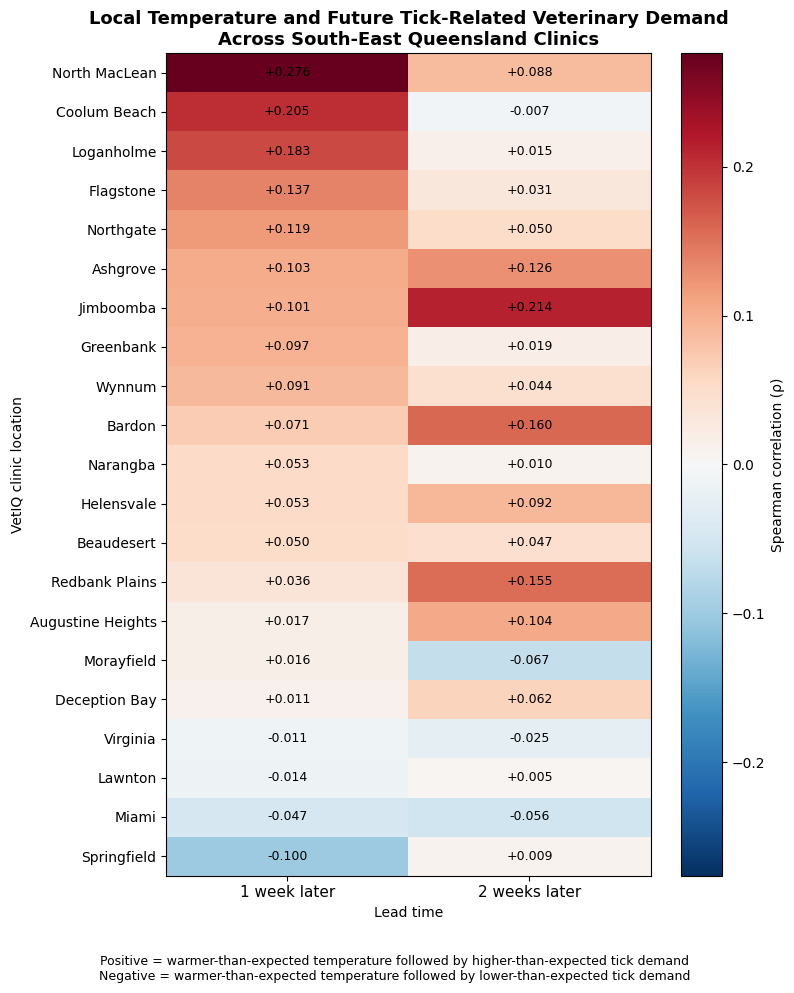

In [75]:
# ============================================================
# CLINIC HEATMAP:
# Temperature correlation at +1 week and +2 weeks
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Create clinic x lead-time table
clinic_heatmap = (
    clinic_temperature_results
    .pivot_table(
        index="Suburb",
        columns="Lead_Weeks",
        values="Spearman_rho",
        aggfunc="mean"
    )
    .rename(columns={
        1: "1 week later",
        2: "2 weeks later"
    })
)

# Sort clinics by 1-week relationship
clinic_heatmap = clinic_heatmap.sort_values(
    "1 week later",
    ascending=False
)

fig, ax = plt.subplots(figsize=(8, 10))

# Symmetric scale so zero is the centre
limit = np.abs(clinic_heatmap.values).max()

im = ax.imshow(
    clinic_heatmap.values,
    aspect="auto",
    vmin=-limit,
    vmax=limit,
    cmap="RdBu_r"
)

# Axis labels
ax.set_xticks(
    np.arange(len(clinic_heatmap.columns))
)

ax.set_xticklabels(
    clinic_heatmap.columns,
    fontsize=11
)

ax.set_yticks(
    np.arange(len(clinic_heatmap.index))
)

ax.set_yticklabels(
    clinic_heatmap.index,
    fontsize=10
)

# Put rho value inside every cell
for i in range(len(clinic_heatmap.index)):
    for j in range(len(clinic_heatmap.columns)):

        value = clinic_heatmap.iloc[i, j]

        ax.text(
            j,
            i,
            f"{value:+.3f}",
            ha="center",
            va="center",
            fontsize=9
        )

cbar = plt.colorbar(
    im,
    ax=ax
)

cbar.set_label(
    "Spearman correlation (ρ)"
)

ax.set_title(
    "Local Temperature and Future Tick-Related Veterinary Demand\n"
    "Across South-East Queensland Clinics",
    fontsize=13,
    fontweight="bold"
)

ax.set_xlabel(
    "Lead time"
)

ax.set_ylabel(
    "VetIQ clinic location"
)

plt.figtext(
    0.5,
    0.015,
    "Positive = warmer-than-expected temperature followed by higher-than-expected tick demand\n"
    "Negative = warmer-than-expected temperature followed by lower-than-expected tick demand",
    ha="center",
    fontsize=9
)

plt.tight_layout(
    rect=[0, 0.06, 1, 1]
)

plt.show()


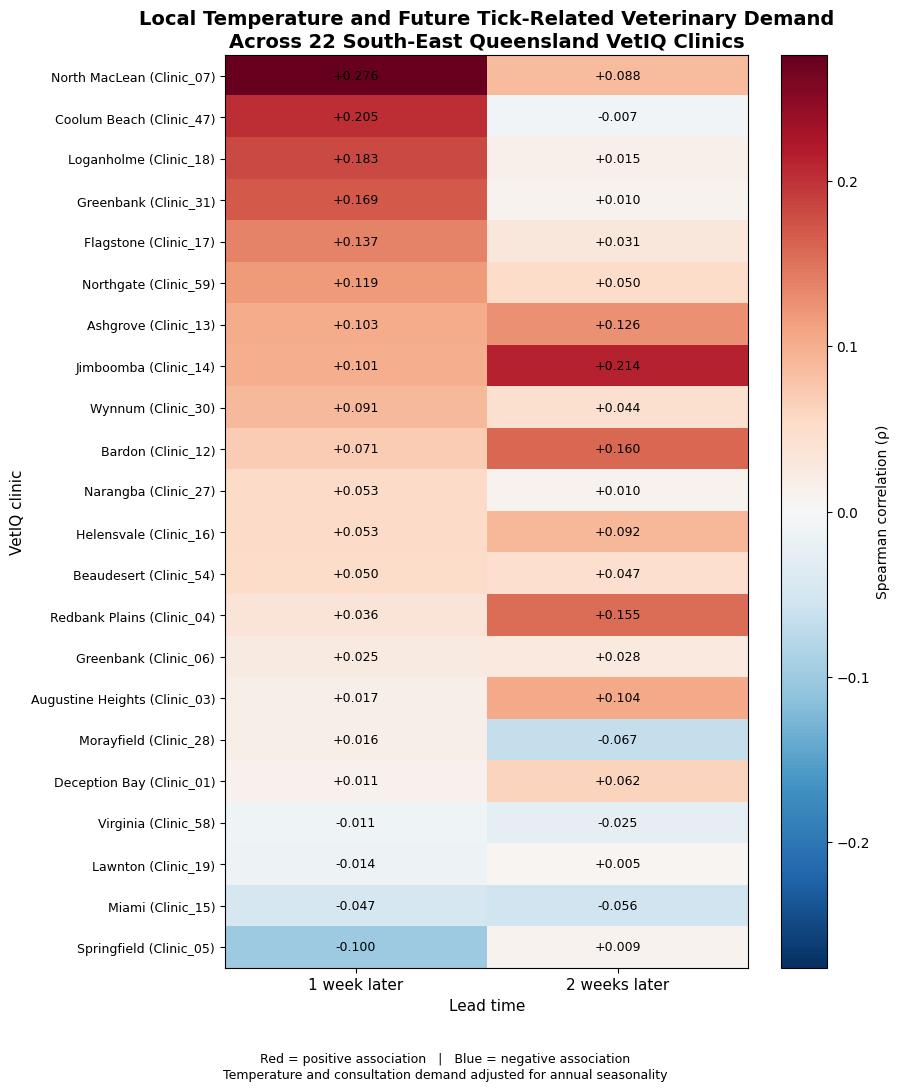

In [76]:
# ============================================================
# FINAL HEATMAP — KEEP ALL 22 CLINICS SEPARATE
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plot_data = clinic_temperature_results.copy()

# Unique label so duplicate suburbs are NOT averaged
plot_data["Clinic_Label"] = (
    plot_data["Suburb"] +
    " (" +
    plot_data["Clinic"] +
    ")"
)

clinic_heatmap = (
    plot_data
    .pivot(
        index="Clinic_Label",
        columns="Lead_Weeks",
        values="Spearman_rho"
    )
    .rename(columns={
        1: "1 week later",
        2: "2 weeks later"
    })
)

# Sort by 1-week correlation
clinic_heatmap = clinic_heatmap.sort_values(
    "1 week later",
    ascending=False
)

fig, ax = plt.subplots(figsize=(9, 11))

# Centre colour scale around zero
limit = np.abs(clinic_heatmap.values).max()

im = ax.imshow(
    clinic_heatmap.values,
    aspect="auto",
    cmap="RdBu_r",
    vmin=-limit,
    vmax=limit
)

# X axis
ax.set_xticks(
    np.arange(len(clinic_heatmap.columns))
)

ax.set_xticklabels(
    clinic_heatmap.columns,
    fontsize=11
)

# Y axis
ax.set_yticks(
    np.arange(len(clinic_heatmap.index))
)

ax.set_yticklabels(
    clinic_heatmap.index,
    fontsize=9
)

# Correlation values inside cells
for i in range(len(clinic_heatmap.index)):
    for j in range(len(clinic_heatmap.columns)):

        value = clinic_heatmap.iloc[i, j]

        ax.text(
            j,
            i,
            f"{value:+.3f}",
            ha="center",
            va="center",
            fontsize=9
        )

# Colour bar
cbar = plt.colorbar(im, ax=ax)

cbar.set_label(
    "Spearman correlation (ρ)",
    fontsize=10
)

ax.set_title(
    "Local Temperature and Future Tick-Related Veterinary Demand\n"
    "Across 22 South-East Queensland VetIQ Clinics",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel(
    "Lead time",
    fontsize=11
)

ax.set_ylabel(
    "VetIQ clinic",
    fontsize=11
)

plt.figtext(
    0.5,
    0.015,
    "Red = positive association   |   Blue = negative association\n"
    "Temperature and consultation demand adjusted for annual seasonality",
    ha="center",
    fontsize=9
)

plt.tight_layout(
    rect=[0, 0.06, 1, 1]
)

plt.show()

In [77]:
# Check the SEQ dataframe before Ridge modelling

print("Available SEQ dataframes:")
for name in list(globals()):
    if "seq" in name.lower():
        obj = globals()[name]
        if hasattr(obj, "shape"):
            print(f"{name:30s} {obj.shape}")

print("\nColumns in seq_panel (if available):")
if "seq_panel" in globals():
    print(seq_panel.columns.tolist())

Available SEQ dataframes:
seq_weekly_ticks               (157, 2)
seq_rain                       (157, 4)
seq_clinics                    (46, 4)
seq_clinics_geo                (46, 6)
seq_all                        (5039636, 4)
seq_tick                       (17123, 4)
seq_weekly                     (5929, 10)
seq_local_weather              (21033, 6)
seq_weekly_weather             (3021, 6)

Columns in seq_panel (if available):


In [78]:
# CELL 2 — Check columns before creating the Ridge modelling dataset

print("seq_weekly columns:")
print(seq_weekly.columns.tolist())

print("\nseq_weekly_weather columns:")
print(seq_weekly_weather.columns.tolist())

print("\nseq_clinics_geo columns:")
print(seq_clinics_geo.columns.tolist())

print("\nFirst rows of seq_weekly:")
display(seq_weekly.head())

print("\nFirst rows of seq_weekly_weather:")
display(seq_weekly_weather.head())

print("\nFirst rows of seq_clinics_geo:")
display(seq_clinics_geo.head())

seq_weekly columns:
['ClinicPseudonym', 'Week_End', 'Total_Consultations', 'Tick_Consultations', 'Tick_per_1000', 'Clinic_ID', 'Suburb', 'lgaregion', 'latitude', 'longitude']

seq_weekly_weather columns:
['Week_End', 'AvgTemp_C', 'Rainfall_mm', 'Humidity_pct', 'latitude', 'longitude']

seq_clinics_geo columns:
['Clinic_ID', 'Suburb', 'Postcode', 'lgaregion', 'latitude', 'longitude']

First rows of seq_weekly:


,ClinicPseudonym,Week_End,Total_Consultations,Tick_Consultations,Tick_per_1000,Clinic_ID,Suburb,lgaregion,latitude,longitude
0,Clinic_01,2023-07-30,290,2.0,6.896552,Clinic_01,Deception Bay,Moreton Bay,-27.181203,153.013716
1,Clinic_01,2023-08-06,763,0.0,0.000000,Clinic_01,Deception Bay,Moreton Bay,-27.181203,153.013716
2,Clinic_01,2023-08-13,703,3.0,4.267425,Clinic_01,Deception Bay,Moreton Bay,-27.181203,153.013716
3,Clinic_01,2023-08-20,629,3.0,4.769475,Clinic_01,Deception Bay,Moreton Bay,-27.181203,153.013716
4,Clinic_01,2023-08-27,610,0.0,0.000000,Clinic_01,Deception Bay,Moreton Bay,-27.181203,153.013716



First rows of seq_weekly_weather:


,Week_End,AvgTemp_C,Rainfall_mm,Humidity_pct,latitude,longitude
0,2023-07-16,16.800000,0.0,63.208333,-28.084952,153.434406
1,2023-07-23,15.900000,9.5,68.678571,-28.084952,153.434406
2,2023-07-30,17.085714,0.2,66.077381,-28.084952,153.434406
3,2023-08-06,17.657143,8.2,75.244048,-28.084952,153.434406
4,2023-08-13,17.242857,0.6,68.160714,-28.084952,153.434406



First rows of seq_clinics_geo:


,Clinic_ID,Suburb,Postcode,lgaregion,latitude,longitude
0,Clinic_13,Ashgrove,4060,Brisbane,-27.445107,152.985176
1,Clinic_12,Bardon,4065,Brisbane,-27.462504,152.975992
2,Clinic_56,Calamvale,4116,Brisbane,-27.633988,153.050793
3,Clinic_62,Camp Hill,4152,Brisbane,-27.501349,153.096812
4,Clinic_48,Chermside,4032,Brisbane,-27.385605,153.019449


In [79]:
# CELL 3 — Build final 22-clinic SEQ modelling panel

import pandas as pd
import numpy as np

# 22 clinics in our final analytical cohort
analysis_clinics = [
    "Clinic_01",  # Deception Bay
    "Clinic_03",  # Augustine Heights
    "Clinic_04",  # Redbank Plains
    "Clinic_05",  # Springfield
    "Clinic_06",  # Greenbank
    "Clinic_07",  # North MacLean
    "Clinic_12",  # Bardon
    "Clinic_13",  # Ashgrove
    "Clinic_14",  # Jimboomba
    "Clinic_15",  # Miami
    "Clinic_16",  # Helensvale
    "Clinic_17",  # Flagstone
    "Clinic_18",  # Loganholme
    "Clinic_19",  # Lawnton
    "Clinic_27",  # Narangba
    "Clinic_28",  # Morayfield
    "Clinic_30",  # Wynnum
    "Clinic_31",  # Greenbank
    "Clinic_47",  # Coolum Beach
    "Clinic_54",  # Beaudesert
    "Clinic_58",  # Virginia
    "Clinic_59"   # Northgate
]

# Make copies
weekly = seq_weekly.copy()
weather = seq_weekly_weather.copy()

weekly["Week_End"] = pd.to_datetime(weekly["Week_End"])
weather["Week_End"] = pd.to_datetime(weather["Week_End"])

# Keep only our 22 analytical clinics
weekly = weekly[
    weekly["Clinic_ID"].isin(analysis_clinics)
].copy()

# Round coordinates to avoid tiny floating-point matching problems
weekly["lat_key"] = weekly["latitude"].round(6)
weekly["lon_key"] = weekly["longitude"].round(6)

weather["lat_key"] = weather["latitude"].round(6)
weather["lon_key"] = weather["longitude"].round(6)

# Remove original coordinate columns from weather before merge
weather_merge = weather[
    [
        "Week_End",
        "lat_key",
        "lon_key",
        "AvgTemp_C",
        "Rainfall_mm",
        "Humidity_pct"
    ]
].copy()

# Merge each clinic-week with weather at that clinic's location
seq_panel = weekly.merge(
    weather_merge,
    on=["Week_End", "lat_key", "lon_key"],
    how="left",
    validate="many_to_one"
)

# Sort correctly for time-series feature creation
seq_panel = seq_panel.sort_values(
    ["Clinic_ID", "Week_End"]
).reset_index(drop=True)

print("FINAL SEQ MODELLING PANEL")
print("=" * 55)

print("Rows:", len(seq_panel))
print("Clinics:", seq_panel["Clinic_ID"].nunique())
print(
    "Period:",
    seq_panel["Week_End"].min().date(),
    "to",
    seq_panel["Week_End"].max().date()
)

print("\nWeather missing after merge:")
print(
    seq_panel[
        ["AvgTemp_C", "Rainfall_mm", "Humidity_pct"]
    ].isna().sum()
)

print("\nRows per clinic:")
print(
    seq_panel.groupby(
        ["Clinic_ID", "Suburb"]
    ).size().sort_values(ascending=False)
)

print("\nPreview:")
display(
    seq_panel[
        [
            "Clinic_ID",
            "Suburb",
            "Week_End",
            "Total_Consultations",
            "Tick_Consultations",
            "Tick_per_1000",
            "AvgTemp_C",
            "Rainfall_mm",
            "Humidity_pct"
        ]
    ].head(10)
)

FINAL SEQ MODELLING PANEL
Rows: 3444
Clinics: 22
Period: 2023-07-30 to 2026-07-26

Weather missing after merge:
AvgTemp_C       0
Rainfall_mm     0
Humidity_pct    0
dtype: int64

Rows per clinic:
Clinic_ID  Suburb           
Clinic_01  Deception Bay        157
Clinic_16  Helensvale           157
Clinic_54  Beaudesert           157
Clinic_47  Coolum Beach         157
Clinic_31  Greenbank            157
Clinic_30  Wynnum               157
Clinic_19  Lawnton              157
Clinic_18  Loganholme           157
Clinic_03  Augustine Heights    157
Clinic_17  Flagstone            157
Clinic_15  Miami                157
Clinic_14  Jimboomba            157
Clinic_13  Ashgrove             157
Clinic_12  Bardon               157
Clinic_07  North MacLean        157
Clinic_06  Greenbank            157
Clinic_05  Springfield          157
Clinic_04  Redbank Plains       157
Clinic_58  Virginia             156
Clinic_59  Northgate            156
Clinic_27  Narangba             153
Clinic_28  Morayfi

,Clinic_ID,Suburb,Week_End,Total_Consultations,Tick_Consultations,Tick_per_1000,AvgTemp_C,Rainfall_mm,Humidity_pct
0,Clinic_01,Deception Bay,2023-07-30,290,2.0,6.896552,16.571429,0.2,69.404762
1,Clinic_01,Deception Bay,2023-08-06,763,0.0,0.000000,17.471429,6.8,76.678571
2,Clinic_01,Deception Bay,2023-08-13,703,3.0,4.267425,16.928571,1.3,68.660714
3,Clinic_01,Deception Bay,2023-08-20,629,3.0,4.769475,18.128571,0.9,59.892857
4,Clinic_01,Deception Bay,2023-08-27,610,0.0,0.000000,17.885714,1.2,72.684524
5,Clinic_01,Deception Bay,2023-09-03,719,2.0,2.781641,17.800000,9.9,77.130952
6,Clinic_01,Deception Bay,2023-09-10,786,1.0,1.272265,19.514286,25.9,71.547619
7,Clinic_01,Deception Bay,2023-09-17,780,0.0,0.000000,17.885714,3.0,67.279762
8,Clinic_01,Deception Bay,2023-09-24,671,5.0,7.451565,19.471429,2.1,68.273810
9,Clinic_01,Deception Bay,2023-10-01,952,3.0,3.151261,19.428571,13.7,71.702381


In [80]:
# CELL 4 — Create 2-week target and baseline Ridge features

import numpy as np
import pandas as pd

# Make sure data is correctly ordered
seq_panel = seq_panel.sort_values(
    ["Clinic_ID", "Week_End"]
).copy()

# -------------------------------------------------------
# 1. TARGET: tick-related demand 2 weeks ahead
# -------------------------------------------------------

seq_panel["Target_2w"] = (
    seq_panel.groupby("Clinic_ID")["Tick_per_1000"]
    .shift(-2)
)

# -------------------------------------------------------
# 2. DEMAND LAG FEATURES
# -------------------------------------------------------

# Current week's observed demand
seq_panel["Tick_Current"] = seq_panel["Tick_per_1000"]

# Previous 1–4 weeks
for lag in range(1, 5):
    seq_panel[f"Tick_Lag_{lag}"] = (
        seq_panel.groupby("Clinic_ID")["Tick_per_1000"]
        .shift(lag)
    )

# -------------------------------------------------------
# 3. PREVIOUS 4-WEEK AVERAGE
# -------------------------------------------------------
# shift(1) ensures the current week is NOT included

seq_panel["Tick_Prev4w_Avg"] = (
    seq_panel.groupby("Clinic_ID")["Tick_per_1000"]
    .transform(
        lambda x: x.shift(1).rolling(4).mean()
    )
)

# -------------------------------------------------------
# 4. ANNUAL SEASONALITY
# -------------------------------------------------------

seq_panel["Week_of_Year"] = (
    seq_panel["Week_End"]
    .dt.isocalendar()
    .week.astype(int)
)

seq_panel["Season_Sin"] = np.sin(
    2 * np.pi * seq_panel["Week_of_Year"] / 52
)

seq_panel["Season_Cos"] = np.cos(
    2 * np.pi * seq_panel["Week_of_Year"] / 52
)

# -------------------------------------------------------
# 5. Define baseline features
# -------------------------------------------------------

baseline_features = [
    "Tick_Current",
    "Tick_Lag_1",
    "Tick_Lag_2",
    "Tick_Lag_3",
    "Tick_Lag_4",
    "Tick_Prev4w_Avg",
    "Season_Sin",
    "Season_Cos"
]

# -------------------------------------------------------
# 6. Create clean modelling dataframe
# -------------------------------------------------------

model_df = seq_panel.dropna(
    subset=baseline_features + ["Target_2w"]
).copy()

print("RIDGE MODELLING DATA")
print("=" * 55)

print("Rows:", len(model_df))
print("Clinics:", model_df["Clinic_ID"].nunique())

print(
    "Period:",
    model_df["Week_End"].min().date(),
    "to",
    model_df["Week_End"].max().date()
)

print("\nTarget:")
print("Target_2w = Tick-related consultations per 1,000, 2 weeks ahead")

print("\nBaseline features:")
for feature in baseline_features:
    print(" -", feature)

print("\nMissing values:")
print(
    model_df[baseline_features + ["Target_2w"]]
    .isna()
    .sum()
)

print("\nPreview:")
display(
    model_df[
        [
            "Clinic_ID",
            "Suburb",
            "Week_End",
            "Tick_per_1000",
            "Tick_Lag_1",
            "Tick_Lag_2",
            "Tick_Prev4w_Avg",
            "Target_2w"
        ]
    ].head(10)
)

RIDGE MODELLING DATA
Rows: 3312
Clinics: 22
Period: 2023-08-27 to 2026-07-12

Target:
Target_2w = Tick-related consultations per 1,000, 2 weeks ahead

Baseline features:
 - Tick_Current
 - Tick_Lag_1
 - Tick_Lag_2
 - Tick_Lag_3
 - Tick_Lag_4
 - Tick_Prev4w_Avg
 - Season_Sin
 - Season_Cos

Missing values:
Tick_Current       0
Tick_Lag_1         0
Tick_Lag_2         0
Tick_Lag_3         0
Tick_Lag_4         0
Tick_Prev4w_Avg    0
Season_Sin         0
Season_Cos         0
Target_2w          0
dtype: int64

Preview:


,Clinic_ID,Suburb,Week_End,Tick_per_1000,Tick_Lag_1,Tick_Lag_2,Tick_Prev4w_Avg,Target_2w
4,Clinic_01,Deception Bay,2023-08-27,0.000000,4.769475,4.267425,3.983363,1.272265
5,Clinic_01,Deception Bay,2023-09-03,2.781641,0.000000,4.769475,2.259225,0.000000
6,Clinic_01,Deception Bay,2023-09-10,1.272265,2.781641,0.000000,2.954635,7.451565
7,Clinic_01,Deception Bay,2023-09-17,0.000000,1.272265,2.781641,2.205845,3.151261
8,Clinic_01,Deception Bay,2023-09-24,7.451565,0.000000,1.272265,1.013476,6.157635
9,Clinic_01,Deception Bay,2023-10-01,3.151261,7.451565,0.000000,2.876368,27.310924
10,Clinic_01,Deception Bay,2023-10-08,6.157635,3.151261,7.451565,2.968772,17.085427
11,Clinic_01,Deception Bay,2023-10-15,27.310924,6.157635,3.151261,4.190115,17.126546
12,Clinic_01,Deception Bay,2023-10-22,17.085427,27.310924,6.157635,11.017846,9.466437
13,Clinic_01,Deception Bay,2023-10-29,17.126546,17.085427,27.310924,13.426312,12.948207


In [81]:
# CELL 5 — Rolling time-series validation for SEQ Ridge models

import numpy as np
import pandas as pd

from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error

# -------------------------------------------------------
# 1. FEATURE SETS
# -------------------------------------------------------

baseline_features = [
    "Tick_Current",
    "Tick_Lag_1",
    "Tick_Lag_2",
    "Tick_Lag_3",
    "Tick_Lag_4",
    "Tick_Prev4w_Avg",
    "Season_Sin",
    "Season_Cos"
]

temperature_features = baseline_features + [
    "AvgTemp_C"
]

weather_features = baseline_features + [
    "AvgTemp_C",
    "Rainfall_mm",
    "Humidity_pct"
]

feature_sets = {
    "Ridge Baseline": baseline_features,
    "Ridge + Temperature": temperature_features,
    "Ridge + Local Weather": weather_features
}

# -------------------------------------------------------
# 2. USE COMMON COMPLETE DATA
# -------------------------------------------------------

all_required = list(
    dict.fromkeys(
        weather_features + ["Target_2w"]
    )
)

ridge_df = (
    model_df
    .dropna(subset=all_required)
    .sort_values(["Week_End", "Clinic_ID"])
    .copy()
)

unique_weeks = np.array(
    sorted(ridge_df["Week_End"].unique())
)

print("Total modelling rows:", len(ridge_df))
print("Clinics:", ridge_df["Clinic_ID"].nunique())
print("Unique weeks:", len(unique_weeks))

# -------------------------------------------------------
# 3. CREATE ROLLING VALIDATION WINDOWS
# -------------------------------------------------------
# Initial training = 104 weeks (~2 years)
# Test window = 4 weeks
# Step = 4 weeks
#
# This gives multiple forward-in-time validation folds.

initial_train_weeks = 104
test_weeks = 4
step_weeks = 4

splits = []

test_start = initial_train_weeks

while test_start + test_weeks <= len(unique_weeks):

    train_week_values = unique_weeks[:test_start]

    test_week_values = unique_weeks[
        test_start:test_start + test_weeks
    ]

    train_idx = ridge_df[
        "Week_End"
    ].isin(train_week_values)

    test_idx = ridge_df[
        "Week_End"
    ].isin(test_week_values)

    splits.append((train_idx, test_idx))

    test_start += step_weeks

print("Rolling validation folds:", len(splits))

# -------------------------------------------------------
# 4. FIT RIDGE WITHIN EACH FOLD
# -------------------------------------------------------
# Scaling is fitted ONLY on training data.
# This avoids leakage.

results = []

for model_name, features in feature_sets.items():

    for fold, (train_idx, test_idx) in enumerate(
        splits, start=1
    ):

        train = ridge_df.loc[train_idx]
        test = ridge_df.loc[test_idx]

        X_train = train[features]
        y_train = train["Target_2w"]

        X_test = test[features]
        y_test = test["Target_2w"]

        model = Pipeline([
            ("scaler", StandardScaler()),
            ("ridge", Ridge(alpha=1.0))
        ])

        model.fit(X_train, y_train)

        pred = model.predict(X_test)

        mae = mean_absolute_error(y_test, pred)

        rmse = np.sqrt(
            mean_squared_error(y_test, pred)
        )

        results.append({
            "Model": model_name,
            "Fold": fold,
            "Train_End": train["Week_End"].max(),
            "Test_Start": test["Week_End"].min(),
            "Test_End": test["Week_End"].max(),
            "N_Train": len(train),
            "N_Test": len(test),
            "MAE": mae,
            "RMSE": rmse
        })

ridge_fold_results = pd.DataFrame(results)

# -------------------------------------------------------
# 5. SHOW FOLD RESULTS
# -------------------------------------------------------

print("\nFOLD-LEVEL RESULTS")
print("=" * 80)

display(
    ridge_fold_results.round(3)
)

# -------------------------------------------------------
# 6. SUMMARY: MEAN + SD + 95% CI
# -------------------------------------------------------

summary_rows = []

for model_name, group in ridge_fold_results.groupby("Model"):

    n = len(group)

    mean_mae = group["MAE"].mean()
    sd_mae = group["MAE"].std(ddof=1)
    se_mae = sd_mae / np.sqrt(n)
    ci_mae = 1.96 * se_mae

    mean_rmse = group["RMSE"].mean()
    sd_rmse = group["RMSE"].std(ddof=1)
    se_rmse = sd_rmse / np.sqrt(n)
    ci_rmse = 1.96 * se_rmse

    summary_rows.append({
        "Model": model_name,
        "Folds": n,

        "Mean_MAE": mean_mae,
        "SD_MAE": sd_mae,
        "MAE_CI_Lower": mean_mae - ci_mae,
        "MAE_CI_Upper": mean_mae + ci_mae,

        "Mean_RMSE": mean_rmse,
        "SD_RMSE": sd_rmse,
        "RMSE_CI_Lower": mean_rmse - ci_rmse,
        "RMSE_CI_Upper": mean_rmse + ci_rmse
    })

ridge_summary = (
    pd.DataFrame(summary_rows)
    .sort_values("Mean_MAE")
    .reset_index(drop=True)
)

print("\nRIDGE MODEL COMPARISON")
print("=" * 80)

display(ridge_summary.round(3))

Total modelling rows: 3312
Clinics: 22
Unique weeks: 151
Rolling validation folds: 11

FOLD-LEVEL RESULTS


/Users/sreelakshmi/.pyenv/versions/3.9.18/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/sreelakshmi/.pyenv/versions/3.9.18/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/sreelakshmi/.pyenv/versions/3.9.18/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/sreelakshmi/.pyenv/versions/3.9.18/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/sreelakshmi/.pyenv/versions/3.9.18/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/sreelakshmi/.pyenv/versions/3.9.18/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/sreel

,Model,Fold,Train_End,Test_Start,Test_End,N_Train,N_Test,MAE,RMSE
0,Ridge Baseline,1,2025-08-17,2025-08-24,2025-09-14,2278,88,15.983,27.404
1,Ridge Baseline,2,2025-09-14,2025-09-21,2025-10-12,2366,88,14.149,22.910
2,Ridge Baseline,3,2025-10-12,2025-10-19,2025-11-09,2454,88,14.128,19.688
3,Ridge Baseline,4,2025-11-09,2025-11-16,2025-12-07,2542,88,10.281,13.041
4,Ridge Baseline,5,2025-12-07,2025-12-14,2026-01-04,2630,88,7.641,11.483
5,Ridge Baseline,6,2026-01-04,2026-01-11,2026-02-01,2718,88,5.810,10.906
6,Ridge Baseline,7,2026-02-01,2026-02-08,2026-03-01,2806,88,4.328,7.205
7,Ridge Baseline,8,2026-03-01,2026-03-08,2026-03-29,2894,88,3.225,5.551
8,Ridge Baseline,9,2026-03-29,2026-04-05,2026-04-26,2982,88,4.642,8.282
9,Ridge Baseline,10,2026-04-26,2026-05-03,2026-05-24,3070,88,5.377,7.062



RIDGE MODEL COMPARISON


,Model,Folds,Mean_MAE,SD_MAE,MAE_CI_Lower,MAE_CI_Upper,Mean_RMSE,SD_RMSE,RMSE_CI_Lower,RMSE_CI_Upper
0,Ridge + Temperature,11,8.472,4.472,5.829,11.114,13.205,7.103,9.007,17.402
1,Ridge Baseline,11,8.487,4.484,5.837,11.137,13.199,7.107,9.000,17.399
2,Ridge + Local Weather,11,8.490,4.379,5.902,11.077,13.253,7.030,9.098,17.408


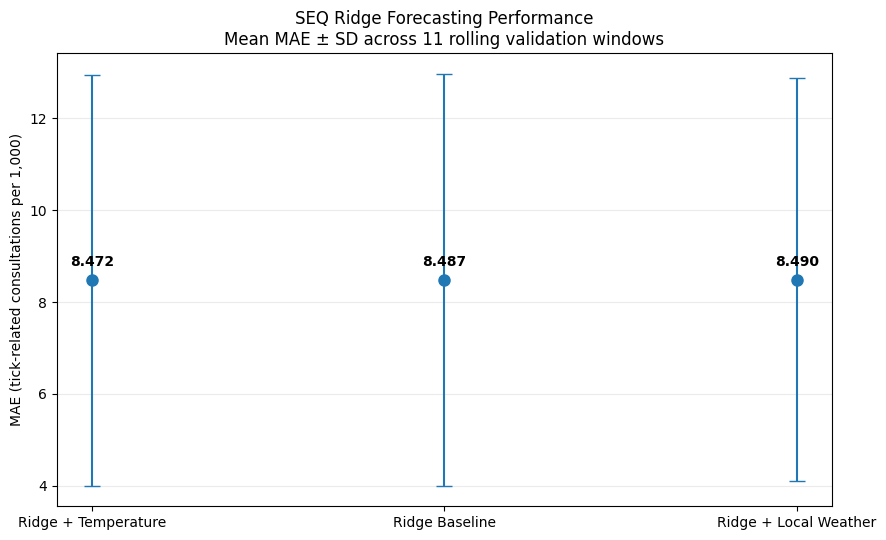

In [82]:
# VISUAL 1 — Mean MAE ± SD across rolling validation folds

import matplotlib.pyplot as plt
import numpy as np

plot_df = (
    ridge_summary
    .sort_values("Mean_MAE")
    .reset_index(drop=True)
)

fig, ax = plt.subplots(figsize=(9, 5.5))

x = np.arange(len(plot_df))

ax.errorbar(
    x,
    plot_df["Mean_MAE"],
    yerr=plot_df["SD_MAE"],
    fmt="o",
    capsize=6,
    markersize=8
)

ax.set_xticks(x)
ax.set_xticklabels(plot_df["Model"])

ax.set_ylabel("MAE (tick-related consultations per 1,000)")
ax.set_title(
    "SEQ Ridge Forecasting Performance\n"
    "Mean MAE ± SD across 11 rolling validation windows"
)

ax.grid(axis="y", alpha=0.25)

for i, value in enumerate(plot_df["Mean_MAE"]):
    ax.annotate(
        f"{value:.3f}",
        (i, value),
        xytext=(0, 10),
        textcoords="offset points",
        ha="center",
        fontweight="bold"
    )

plt.tight_layout()
plt.show()

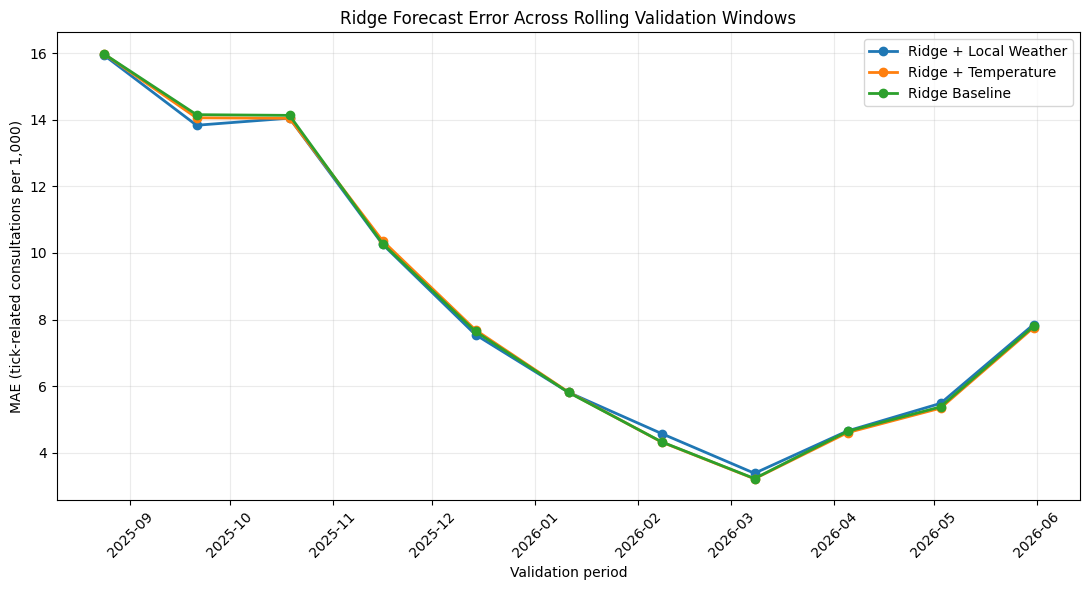

In [83]:
# VISUAL 2 — Model error across rolling validation windows

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(11, 6))

for model_name, group in ridge_fold_results.groupby("Model"):

    group = group.sort_values("Test_Start")

    ax.plot(
        group["Test_Start"],
        group["MAE"],
        marker="o",
        linewidth=2,
        label=model_name
    )

ax.set_title(
    "Ridge Forecast Error Across Rolling Validation Windows"
)

ax.set_xlabel("Validation period")
ax.set_ylabel(
    "MAE (tick-related consultations per 1,000)"
)

ax.legend()
ax.grid(alpha=0.25)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

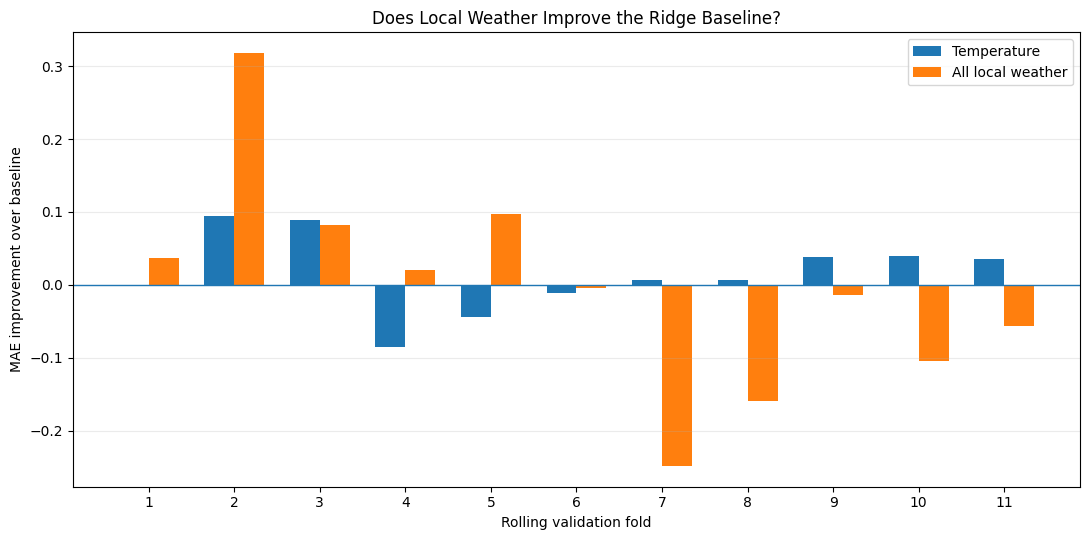

Positive value = lower MAE than baseline
Negative value = worse than baseline


Model,Fold,Temperature_Improvement,Weather_Improvement
0,1,0.000,0.037
1,2,0.094,0.318
2,3,0.089,0.083
3,4,-0.086,0.020
4,5,-0.044,0.098
5,6,-0.011,-0.004
6,7,0.006,-0.249
7,8,0.007,-0.159
8,9,0.039,-0.013
9,10,0.039,-0.105


In [84]:
# VISUAL 3 — Fold-by-fold MAE improvement relative to baseline

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

fold_compare = ridge_fold_results.pivot(
    index="Fold",
    columns="Model",
    values="MAE"
).reset_index()

fold_compare["Temperature_Improvement"] = (
    fold_compare["Ridge Baseline"]
    - fold_compare["Ridge + Temperature"]
)

fold_compare["Weather_Improvement"] = (
    fold_compare["Ridge Baseline"]
    - fold_compare["Ridge + Local Weather"]
)

fig, ax = plt.subplots(figsize=(11, 5.5))

x = np.arange(len(fold_compare))
width = 0.35

ax.bar(
    x - width/2,
    fold_compare["Temperature_Improvement"],
    width,
    label="Temperature"
)

ax.bar(
    x + width/2,
    fold_compare["Weather_Improvement"],
    width,
    label="All local weather"
)

ax.axhline(0, linewidth=1)

ax.set_xticks(x)
ax.set_xticklabels(fold_compare["Fold"])

ax.set_xlabel("Rolling validation fold")
ax.set_ylabel("MAE improvement over baseline")

ax.set_title(
    "Does Local Weather Improve the Ridge Baseline?"
)

ax.legend()
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

print("Positive value = lower MAE than baseline")
print("Negative value = worse than baseline")

display(
    fold_compare[
        [
            "Fold",
            "Temperature_Improvement",
            "Weather_Improvement"
        ]
    ].round(3)
)

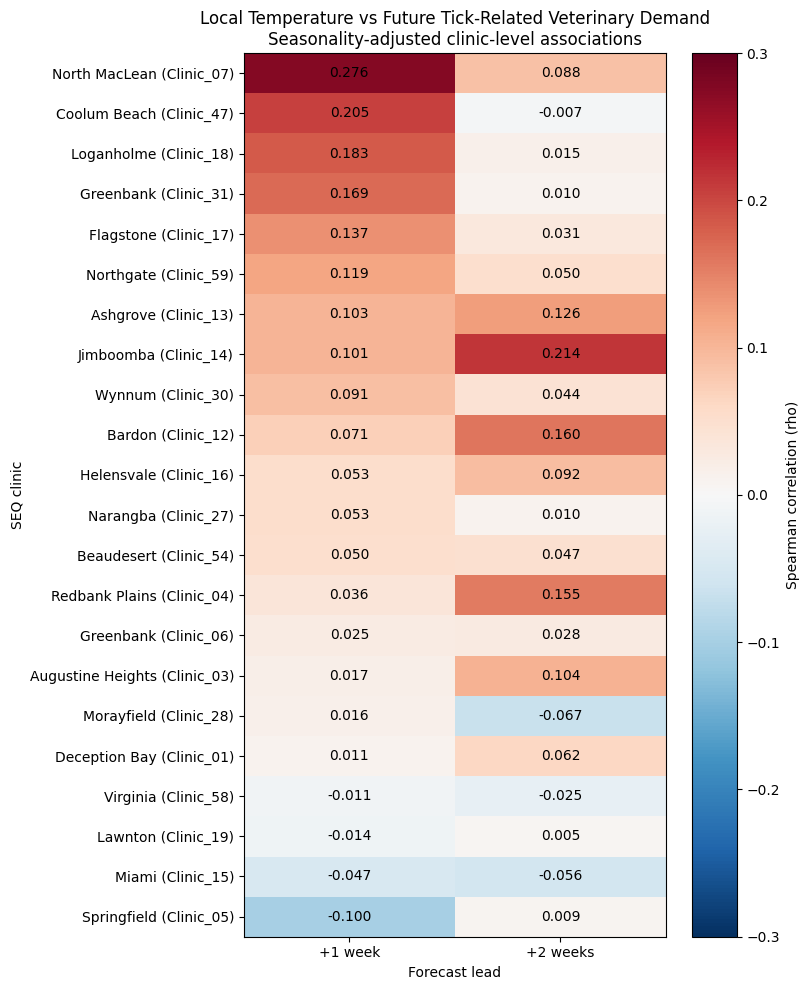

1-week positive clinics: 18 / 22
2-week positive clinics: 18 / 22
Median rho (+1 week): 0.053
Median rho (+2 weeks): 0.038


In [87]:
# VISUAL 4 — Recreate clinic-level temperature results + heatmap

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Results from our clinic-level seasonality-adjusted analysis
temp_data = [
    # Clinic, Suburb, +1 week rho, +2 week rho
    ("Clinic_07", "North MacLean",       0.276,  0.088),
    ("Clinic_47", "Coolum Beach",        0.205, -0.007),
    ("Clinic_18", "Loganholme",          0.183,  0.015),
    ("Clinic_31", "Greenbank",           0.169,  0.010),
    ("Clinic_17", "Flagstone",           0.137,  0.031),
    ("Clinic_59", "Northgate",           0.119,  0.050),
    ("Clinic_13", "Ashgrove",            0.103,  0.126),
    ("Clinic_14", "Jimboomba",           0.101,  0.214),
    ("Clinic_30", "Wynnum",              0.091,  0.044),
    ("Clinic_12", "Bardon",              0.071,  0.160),
    ("Clinic_27", "Narangba",            0.053,  0.010),
    ("Clinic_16", "Helensvale",          0.053,  0.092),
    ("Clinic_54", "Beaudesert",          0.050,  0.047),
    ("Clinic_04", "Redbank Plains",      0.036,  0.155),
    ("Clinic_06", "Greenbank",           0.025,  0.028),
    ("Clinic_03", "Augustine Heights",   0.017,  0.104),
    ("Clinic_28", "Morayfield",          0.016, -0.067),
    ("Clinic_01", "Deception Bay",       0.011,  0.062),
    ("Clinic_58", "Virginia",           -0.011, -0.025),
    ("Clinic_19", "Lawnton",            -0.014,  0.005),
    ("Clinic_15", "Miami",              -0.047, -0.056),
    ("Clinic_05", "Springfield",        -0.100,  0.009)
]

heatmap_df = pd.DataFrame(
    temp_data,
    columns=[
        "Clinic_ID",
        "Suburb",
        "+1 week",
        "+2 weeks"
    ]
)

# Unique label so both Greenbank clinics remain separate
heatmap_df["Clinic"] = (
    heatmap_df["Suburb"]
    + " ("
    + heatmap_df["Clinic_ID"]
    + ")"
)

heatmap_df = (
    heatmap_df
    .set_index("Clinic")[["+1 week", "+2 weeks"]]
    .sort_values("+1 week", ascending=False)
)

# Plot
fig, ax = plt.subplots(figsize=(8, 10))

im = ax.imshow(
    heatmap_df.values,
    aspect="auto",
    cmap="RdBu_r",
    vmin=-0.30,
    vmax=0.30
)

ax.set_xticks(range(2))
ax.set_xticklabels(["+1 week", "+2 weeks"])

ax.set_yticks(range(len(heatmap_df)))
ax.set_yticklabels(heatmap_df.index)

# Put correlation values inside cells
for i in range(len(heatmap_df)):
    for j in range(2):
        value = heatmap_df.iloc[i, j]

        ax.text(
            j,
            i,
            f"{value:.3f}",
            ha="center",
            va="center"
        )

cbar = plt.colorbar(im, ax=ax)
cbar.set_label("Spearman correlation (rho)")

ax.set_title(
    "Local Temperature vs Future Tick-Related Veterinary Demand\n"
    "Seasonality-adjusted clinic-level associations"
)

ax.set_xlabel("Forecast lead")
ax.set_ylabel("SEQ clinic")

plt.tight_layout()
plt.show()

# Summary
print("1-week positive clinics:",
      (heatmap_df["+1 week"] > 0).sum(), "/",
      len(heatmap_df))

print("2-week positive clinics:",
      (heatmap_df["+2 weeks"] > 0).sum(), "/",
      len(heatmap_df))

print("Median rho (+1 week):",
      round(heatmap_df["+1 week"].median(), 3))

print("Median rho (+2 weeks):",
      round(heatmap_df["+2 weeks"].median(), 3))

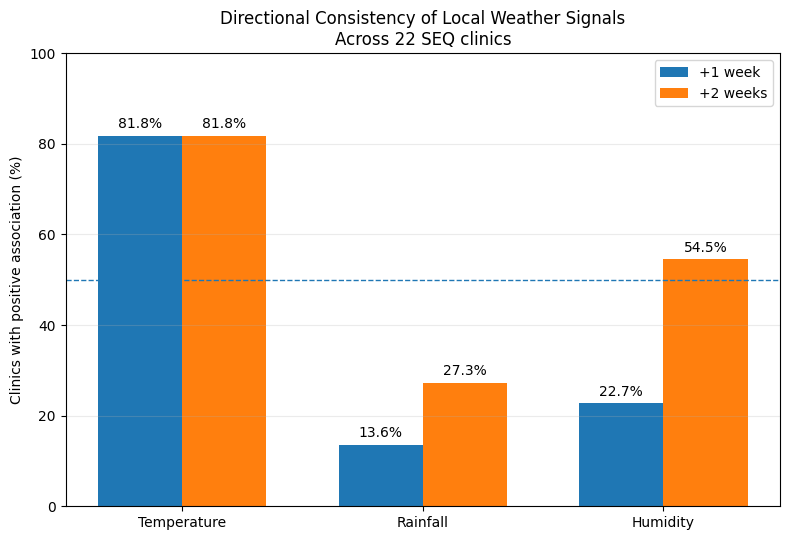

In [88]:
# VISUAL 5 — Directional consistency of environmental signals

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

env_summary = pd.DataFrame({
    "Variable": [
        "Temperature", "Temperature",
        "Rainfall", "Rainfall",
        "Humidity", "Humidity"
    ],
    "Lead": [
        "+1 week", "+2 weeks",
        "+1 week", "+2 weeks",
        "+1 week", "+2 weeks"
    ],
    "Positive_Percent": [
        81.8, 81.8,
        13.6, 27.3,
        22.7, 54.5
    ]
})

pivot_env = env_summary.pivot(
    index="Variable",
    columns="Lead",
    values="Positive_Percent"
)

pivot_env = pivot_env.loc[
    ["Temperature", "Rainfall", "Humidity"]
]

fig, ax = plt.subplots(figsize=(8, 5.5))

x = np.arange(len(pivot_env))
width = 0.35

ax.bar(
    x - width/2,
    pivot_env["+1 week"],
    width,
    label="+1 week"
)

ax.bar(
    x + width/2,
    pivot_env["+2 weeks"],
    width,
    label="+2 weeks"
)

ax.axhline(
    50,
    linestyle="--",
    linewidth=1
)

ax.set_xticks(x)
ax.set_xticklabels(pivot_env.index)

ax.set_ylim(0, 100)

ax.set_ylabel("Clinics with positive association (%)")

ax.set_title(
    "Directional Consistency of Local Weather Signals\n"
    "Across 22 SEQ clinics"
)

ax.legend()
ax.grid(axis="y", alpha=0.25)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f%%",
        padding=3
    )

plt.tight_layout()
plt.show()